In [1]:
pip install pandas pyarrow ydata_profiling numpy matplotlib xgboost lightgbm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Carga de la base

In [2]:
import pandas as pd

# Ruta del archivo
df = pd.read_parquet(r"C:\Users\facun\Desktop\AED 2025\TP clasificación\base_attrition.parquet")

# Mostrar las primeras filas
print(df.head())

         id  anio_mes  fl_cliente_vip  edad_cliente  antiguedad_cliente  \
0  29183981    202101               0            50                 195   
1  29184630    202101               0            59                 320   
2  29185587    202101               0            79                 320   
3  29188277    202101               0            67                 320   
4  29188490    202101               0            45                 305   

   q_productos  q_cta_corriente  vl_cta_corriente  q_csav   vl_csav  ...  \
0            8                1              0.00       2  84725.01  ...   
1            9                1          45880.34       2  29562.06  ...   
2            9                1           -691.51       2  44361.73  ...   
3            5                1              0.00       2  26808.75  ...   
4           12                1           -428.82       2  73574.48  ...   

   fl_app  q_app_trx  tc_visa_delinquency  tc_visa_status  vl_tc_visa_saldo  \
0       0    

# Exploración inicial de la base

In [3]:
print(f"Cantidad de filas y columnas",df.shape)
df.info()

Cantidad de filas y columnas (767222, 78)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 767222 entries, 0 to 767221
Data columns (total 78 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   id                        767222 non-null  int64  
 1   anio_mes                  767222 non-null  int64  
 2   fl_cliente_vip            767222 non-null  int64  
 3   edad_cliente              767222 non-null  int64  
 4   antiguedad_cliente        767222 non-null  int64  
 5   q_productos               767222 non-null  int64  
 6   q_cta_corriente           767222 non-null  int64  
 7   vl_cta_corriente          767222 non-null  float64
 8   q_csav                    767222 non-null  int64  
 9   vl_csav                   767222 non-null  float64
 10  vl_ctas_saldo             767222 non-null  float64
 11  q_td                      767222 non-null  int64  
 12  q_td_trx                  767222 non-null  int64  
 13  vl

Hay dos variables en la base que tienen el mismo nombre: 
- **vl_tc_visa_consumo** y **vl_tc_visa_consumo.1**: El que tiene el nombre vl_tc_visa_consumo.1 se refiere a "Monto total de los consumos en pesos efectuados por el cliente durante ese mes." y el otro tiene la misma definición pero con los consumos de la tarjeta de crédito Visa.

Convertimos **anio_mes** a formato date, con fecha a fin de mes

In [4]:
df['anio_mes_orig'] =df['anio_mes']

In [5]:
df['anio_mes'] = pd.to_datetime(df['anio_mes'].astype(str), format='%Y%m') + pd.offsets.MonthEnd(0)

Transformo **tc_visa_status** en cuali nominal (**tc_visa_status_nominal**)

In [6]:
# Diccionario de mapeo de códigos a etiquetas nominales
status_map = {
    0: "Abierta",
    6: "En proceso de cierre",
    7: "Proceso avanzado de cierre",
    9: "Cuenta cerrada"
}

# Crear nueva variable cualitativa nominal
df['tc_visa_status_nominal'] = df['tc_visa_status'].map(status_map).astype('category')

In [7]:
# cantidad de clientes únicos
df["id"].nunique()

111937

In [8]:
# Detectar filas duplicadas basadas en 'id' y 'anio_mes'
duplicados = df[df.duplicated(subset=['id', 'anio_mes'], keep=False)]
print(f"Total de filas duplicadas: {len(duplicados)}")

duplicados = duplicados.sort_values(['id', 'anio_mes'])
display(duplicados)

Total de filas duplicadas: 0


,id,anio_mes,fl_cliente_vip,edad_cliente,antiguedad_cliente,q_productos,q_cta_corriente,vl_cta_corriente,q_csav,vl_csav,...,tc_visa_delinquency,tc_visa_status,vl_tc_visa_saldo,vl_tc_visa_consumo.1,vl_tc_visa_limite_compra,vl_tc_visa_pagado,tc_visa_fc_alta,q_tc_visa_consumos,anio_mes_orig,tc_visa_status_nominal


In [9]:
# Ajustar el límite de filas visibles en la salida
pd.set_option('display.max_rows', 100)  # o un número mayor si tenés más de 100 filas

## Descriptivos

La base contiene información sobre los clientes del banco X por mes, desde el 1/1/2021 hasta 31/7/2021

In [10]:
#Descriptivos 
df.describe().T

,count,mean,min,25%,50%,75%,max,std
id,767222.0,90016343.82918,29183981.0,60624491.0,85464026.0,116860984.0,187457808.0,37694231.985005
anio_mes,767222,2021-04-30 18:25:21.472533504,2021-01-31 00:00:00,2021-02-28 00:00:00,2021-04-30 00:00:00,2021-06-30 00:00:00,2021-07-31 00:00:00,NaN
fl_cliente_vip,767222.0,0.003051,0.0,0.0,0.0,0.0,1.0,0.055154
edad_cliente,767222.0,46.910901,18.0,37.0,45.0,56.0,99.0,12.945635
antiguedad_cliente,767222.0,135.142948,1.0,63.0,128.0,190.0,379.0,85.863313
q_productos,767222.0,7.551814,3.0,7.0,7.0,8.0,17.0,1.488898
q_cta_corriente,767222.0,1.00262,1.0,1.0,1.0,1.0,5.0,0.052352
vl_cta_corriente,767222.0,3389.756115,-1694435.75,-878.6175,0.0,0.0,32631671.24,119364.645636
q_csav,767222.0,2.131224,2.0,2.0,2.0,2.0,12.0,0.482936
vl_csav,767222.0,84160.489424,-15604.19,6367.465,25841.745,74948.405,26167507.62,253338.651271


## Detección de cosas raras

In [11]:
pd.set_option("display.width", 2000)

### Antiguedad del cliente vs edad

In [12]:
df2= df.copy()

# --- 1. Variables auxiliares ---
df2['antiguedad_en_anios'] = df2['antiguedad_cliente'] / 12
df2['edad_al_ingreso'] = df2['edad_cliente'] - df2['antiguedad_en_anios']

# --- 2. Flag de edad_antiguedad ---
df2['flag_edad_antiguedad'] = (df2['edad_al_ingreso'] < 18) | (df2['edad_al_ingreso'] > df2['edad_cliente']) # Puse 18 años porque es el mínimo en la base

# --- 3. Cantidad de casos únicos inconsistentes ---
ids_inconsistentes = df2.loc[df2['flag_edad_antiguedad'], 'id'].nunique()
ids_totales = df2['id'].nunique()

print(f"- Clientes únicos con edad al ingreso menor a 18 años o mayor que su edad actual: {ids_inconsistentes:,}")
print(f"- Total de clientes: {ids_totales:,}")
print(f"- Porcentaje de clientes inconsistentes: {100 * ids_inconsistentes / ids_totales:.2f}%")

- Clientes únicos con edad al ingreso menor a 18 años o mayor que su edad actual: 973
- Total de clientes: 111,937
- Porcentaje de clientes inconsistentes: 0.87%


In [13]:
pd.set_option('display.max_rows', None)

In [14]:
# df con los ids inconsistentes

# Aseguro auxiliares (por si no quedaron en el df)
df2['antiguedad_en_anios'] = df2['antiguedad_cliente'] / 12
df2['edad_al_ingreso'] = df2['edad_cliente'] - df2['antiguedad_en_anios']
df2['flag_edad_antiguedad'] = (df2['edad_al_ingreso'] < 18) | (df2['edad_al_ingreso'] > df2['edad_cliente'])
df2['meses_alta_visa_tc'] = df2['tc_visa_fc_alta'] / 30.42  # promedio de días por mes

# Todas las filas inconsistentes (sin deduplicar por id)
cols = ['id', 'anio_mes', 'edad_cliente', 'antiguedad_cliente',
        'antiguedad_en_anios', 'edad_al_ingreso','meses_alta_visa_tc']

df_incoh = (
    df2.loc[df2['flag_edad_antiguedad'], cols]
      .sort_values(['edad_al_ingreso'])
      .reset_index(drop=True)
)

print(df_incoh)

             id   anio_mes  edad_cliente  antiguedad_cliente  antiguedad_en_anios  edad_al_ingreso  meses_alta_visa_tc
0      51604679 2021-01-31            40                 373            31.083333         8.916667          187.935569
1      51604679 2021-07-31            41                 379            31.583333         9.416667          193.885602
2      51604679 2021-06-30            41                 378            31.500000         9.500000          192.866535
3      51604679 2021-05-31            41                 377            31.416667         9.583333          191.880342
4      51604679 2021-04-30            41                 376            31.333333         9.666667          190.861275
5      51604679 2021-03-31            41                 375            31.250000         9.750000          189.875082
6      51604679 2021-02-28            41                 374            31.166667         9.833333          188.856016
7      50727520 2021-07-31            43        

## Reporte AED de la base

In [15]:
#from ydata_profiling import ProfileReport
## Generate the EDA report
#profile = ProfileReport(df, title="EDA")
#
## Save the report to an HTML file
#profile.to_file("eda_report.html")

## Densidad de cada variable por anio_mes (revisar)

Marzo y junio 2021 encierro por pandemia
Junio aguinaldo
q_deb_auto_visa tiene variaciones. Conviene con  lags o deltas 

Variables numéricas a graficar: 70
['edad_cliente', 'antiguedad_cliente', 'q_productos', 'q_cta_corriente', 'vl_cta_corriente', 'q_csav', 'vl_csav', 'vl_ctas_saldo', 'q_td', 'q_td_trx', 'vl_td_trx', 'q_tc_visa', 'q_tc_visa_trx', 'vl_tc_visa_consumo', 'q_prest_pers', 'vl_prest_pers', 'q_prest_hipo', 'vl_prest_hipo', 'q_pl_fijo', 'vl_pl_fijo_ars', 'vl_pl_fijo_usd', 'q_inv', 'vl_inv_ars', 'vl_inv_usd', 'q_seg_vida', 'q_seg_vivienda', 'q_haberes_trx', 'vl_haberes', 'q_deb_auto_ctas', 'vl_deb_auto_ctas', 'q_deb_auto_visa', 'vl_deb_auto_visa', 'q_pago_serv', 'vl_pago_serv', 'q_desc_td', 'vl_desc_td', 'q_desc_tc_visa', 'vl_desc_tc_visa', 'q_comisiones_mant', 'vl_comisiones_mant', 'q_comisiones_otras', 'vl_comisiones_otras', 'q_transf_in', 'vl_transf_in', 'q_transf_out', 'vl_transf_out', 'q_cheq_dep', 'vl_cheq_dep', 'q_cheq_emit', 'vl_cheq_emit', 'q_cheq_dep_rech', 'vl_cheq_dep_rech', 'q_cheq_emit_rech', 'vl_cheq_emit_rech', 'q_callcenter_trx', 'q_onlinebank_trx', 'q_cajas_trx', 'q_atm_trx', '

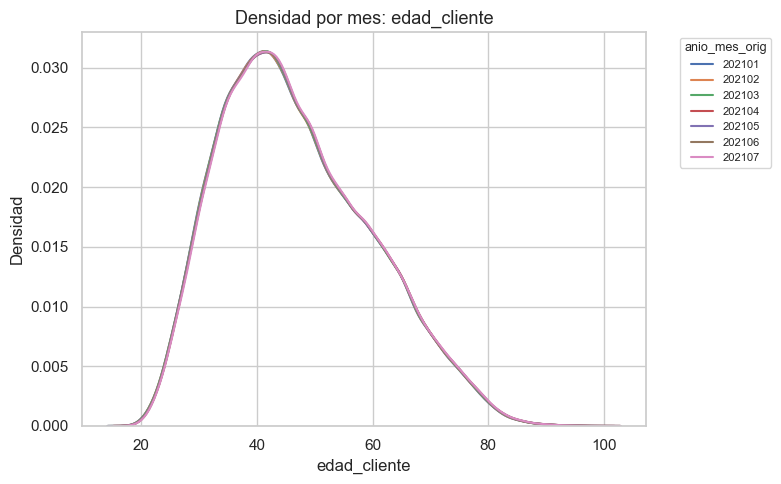

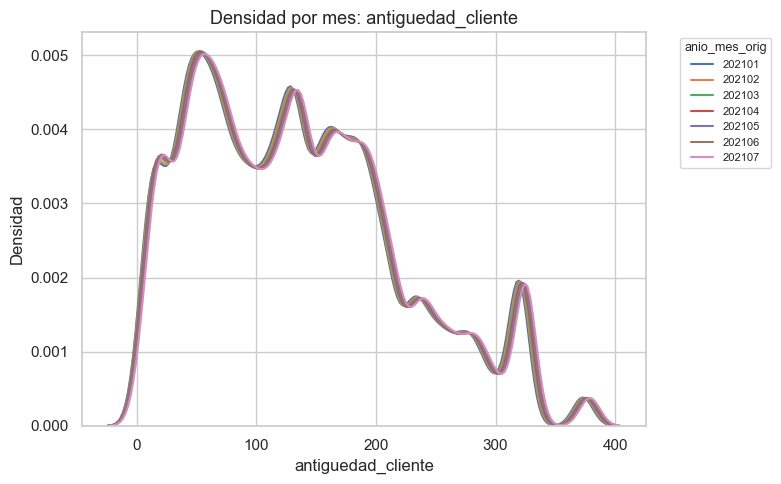

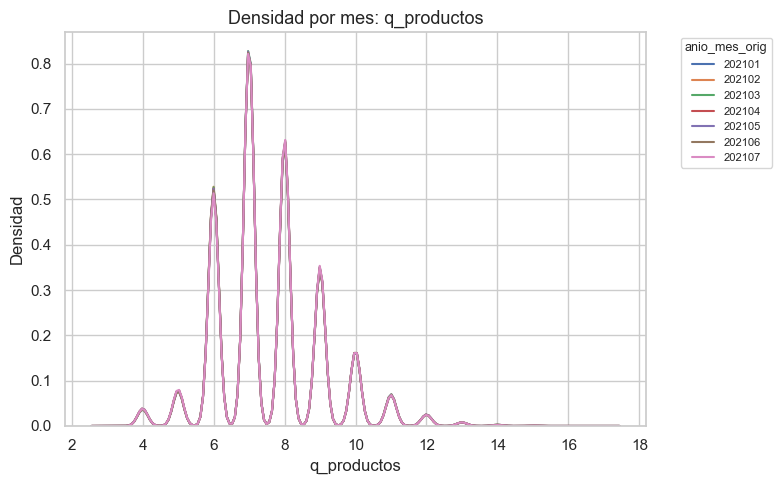

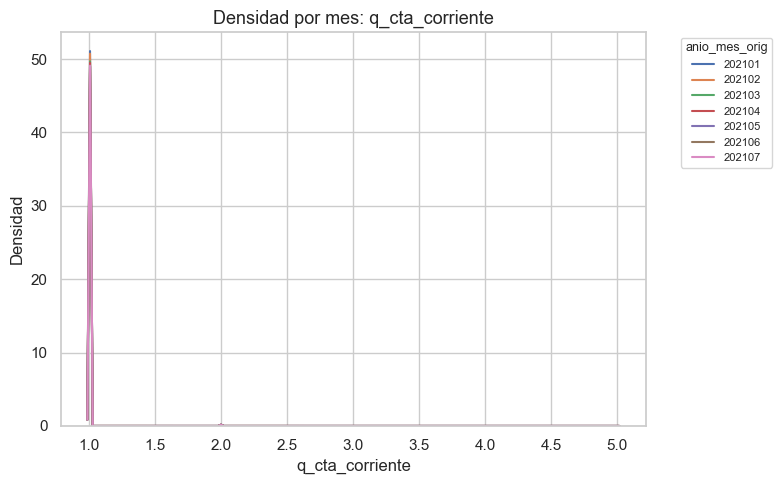

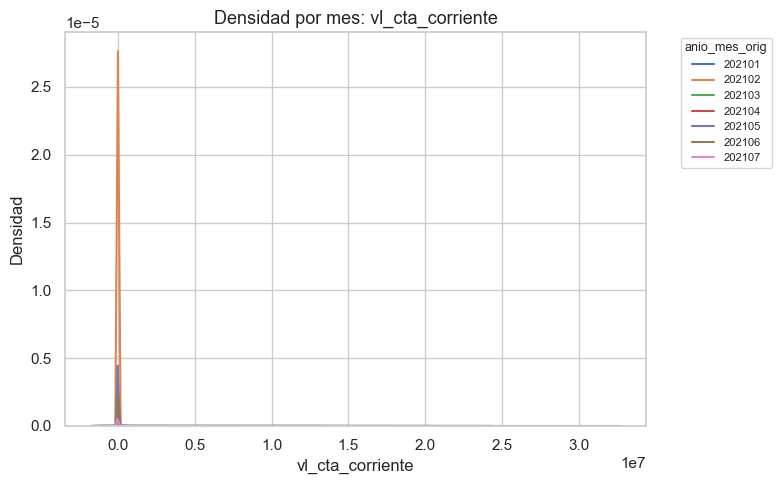

...

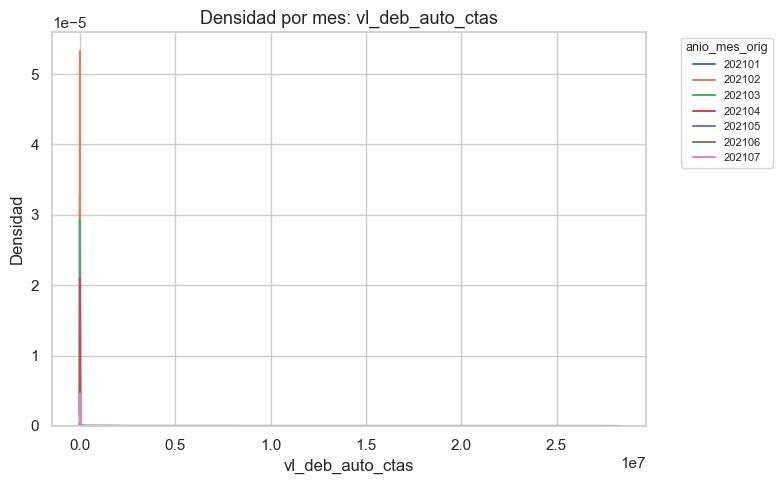

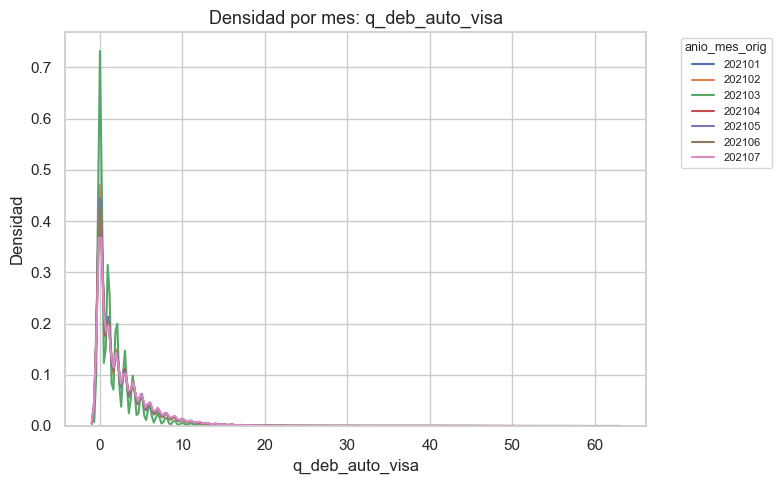

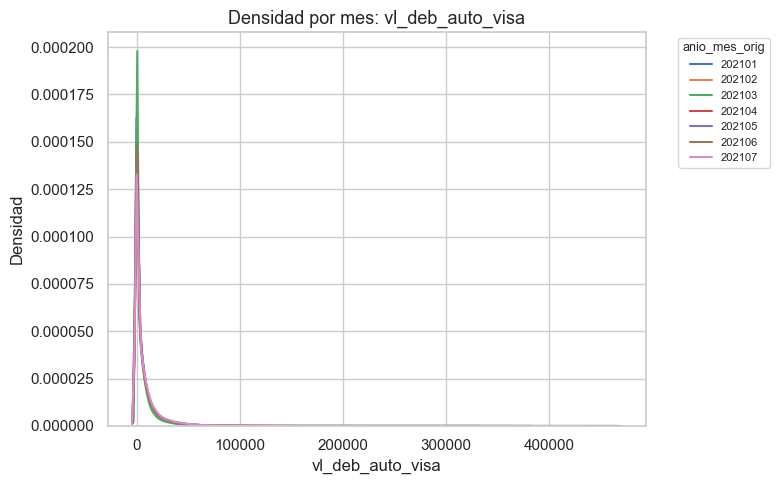

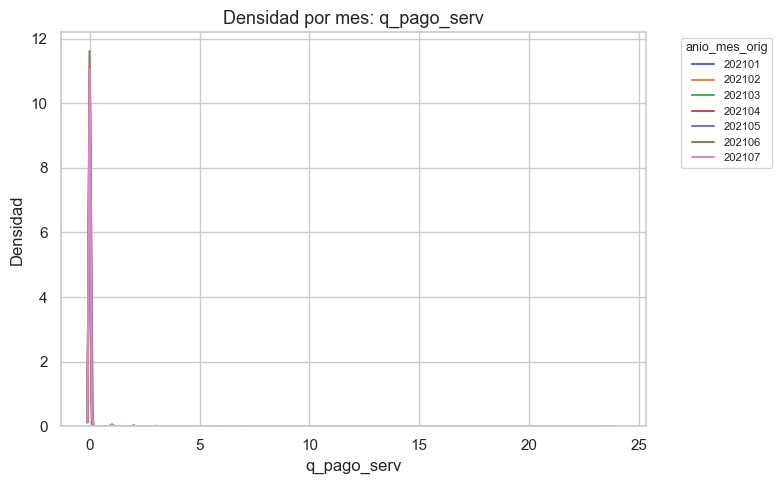

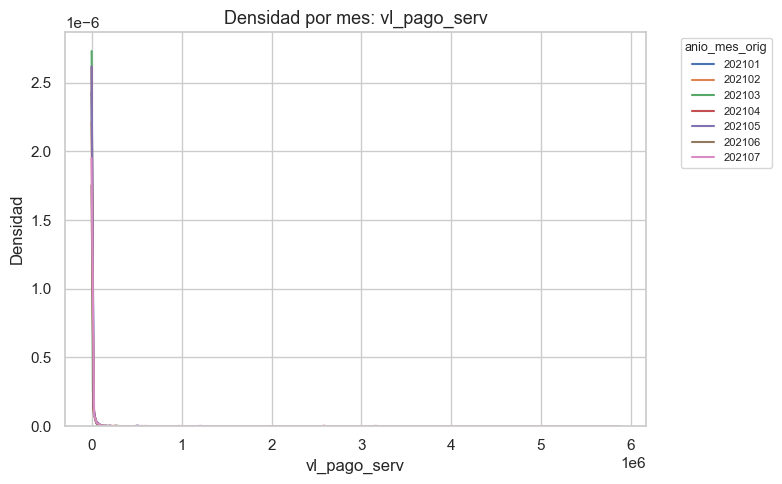

C:\Users\facun\AppData\Local\Temp\ipykernel_21152\101358444.py:50: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


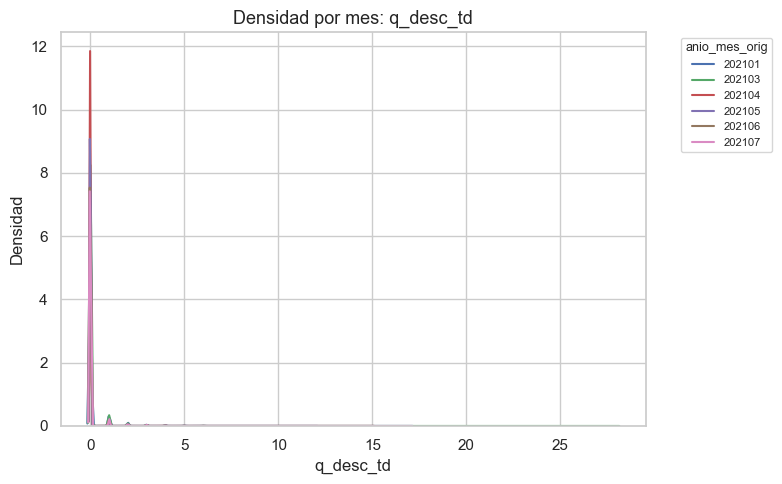

C:\Users\facun\AppData\Local\Temp\ipykernel_21152\101358444.py:50: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


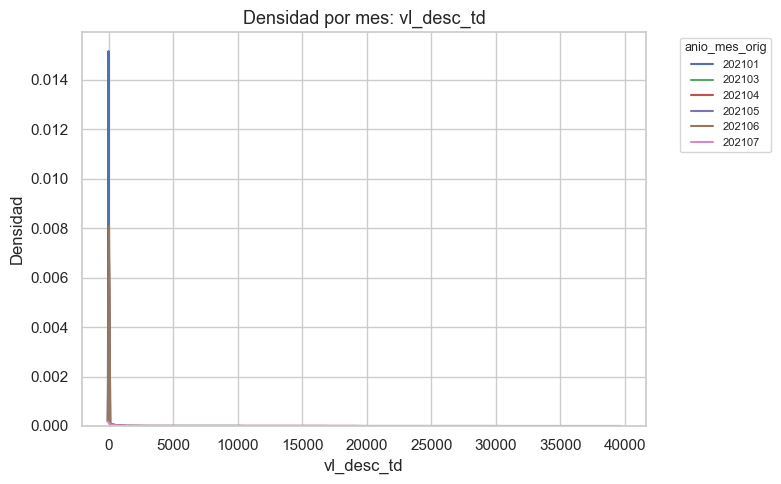

C:\Users\facun\AppData\Local\Temp\ipykernel_21152\101358444.py:50: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


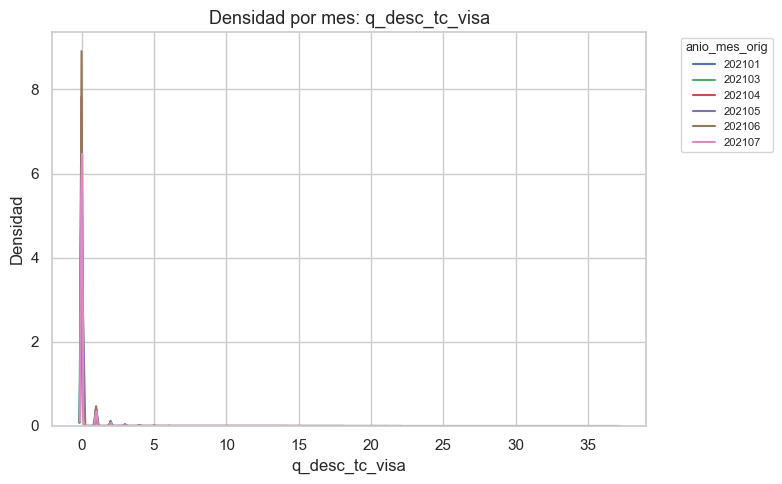

C:\Users\facun\AppData\Local\Temp\ipykernel_21152\101358444.py:50: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


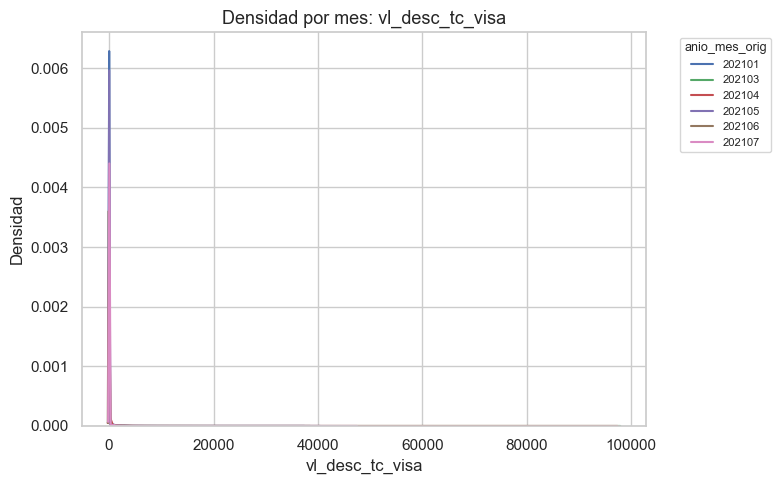

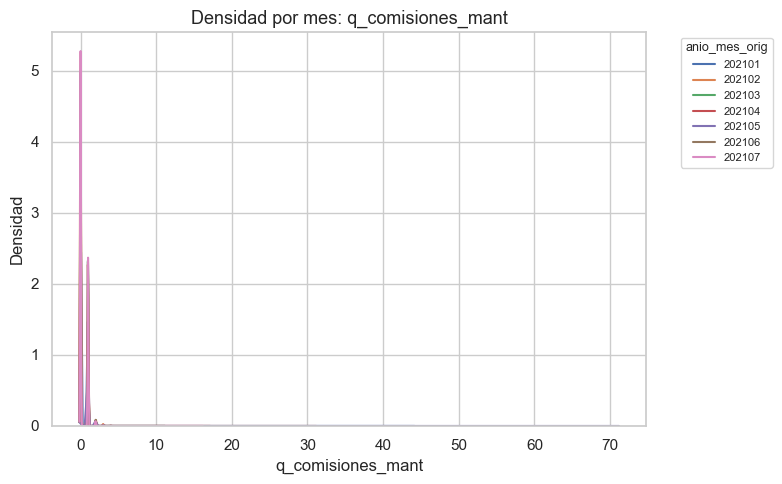

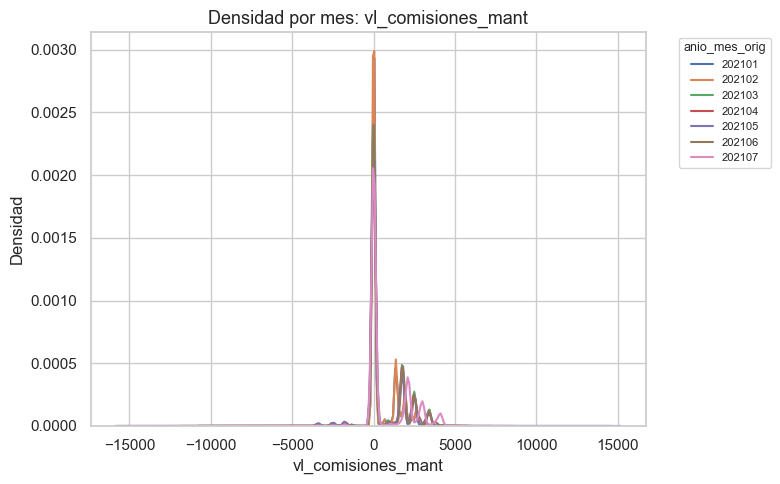

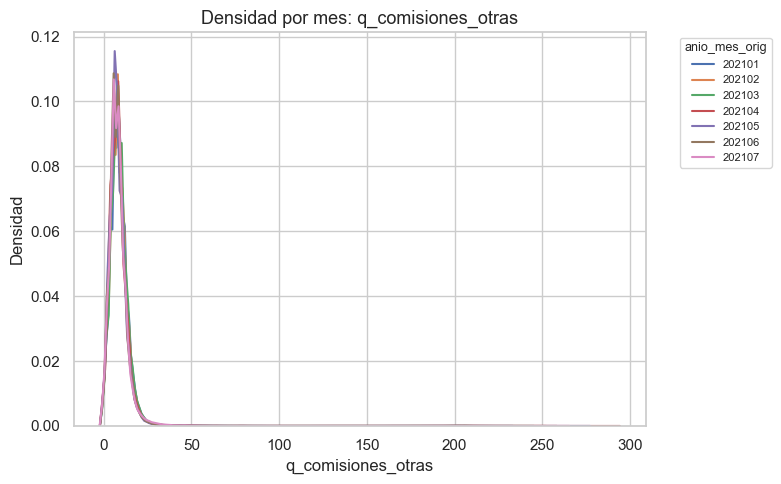

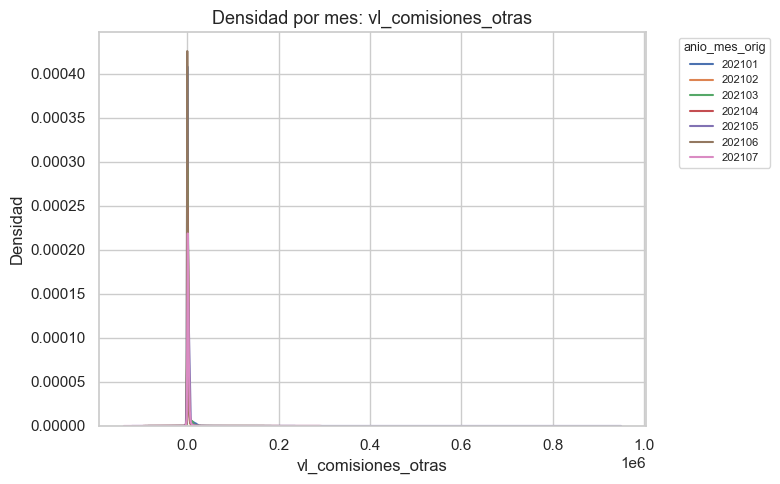

...

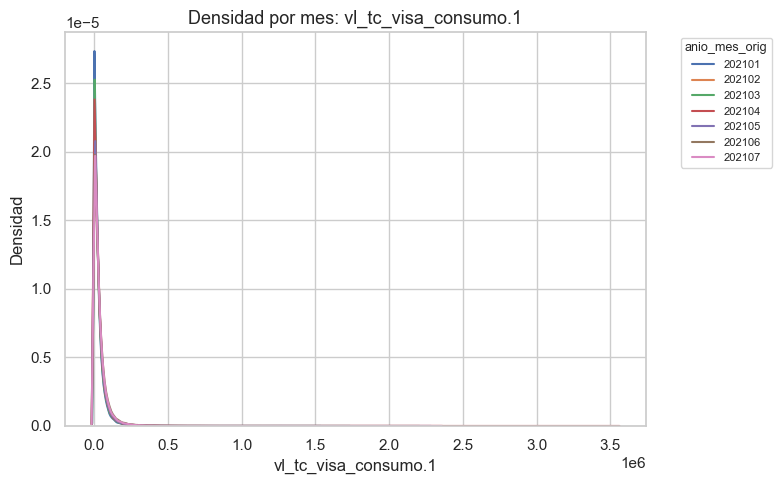

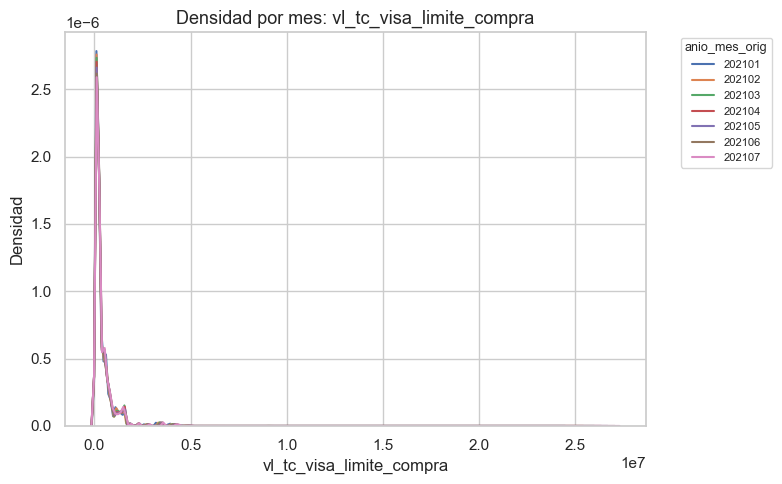

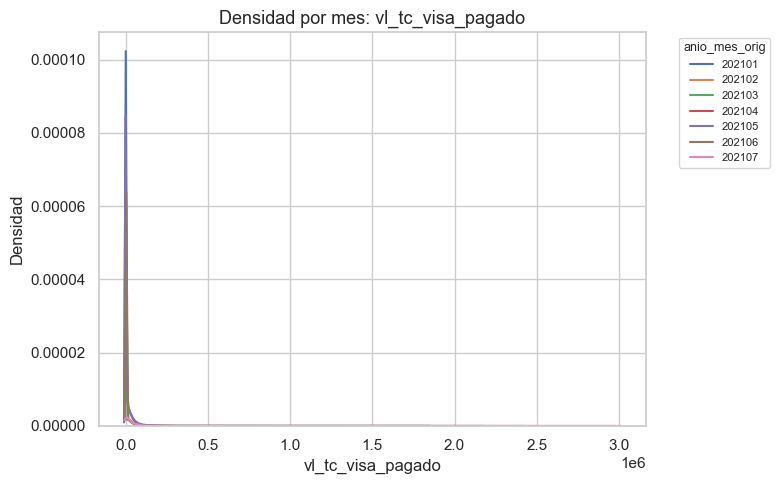

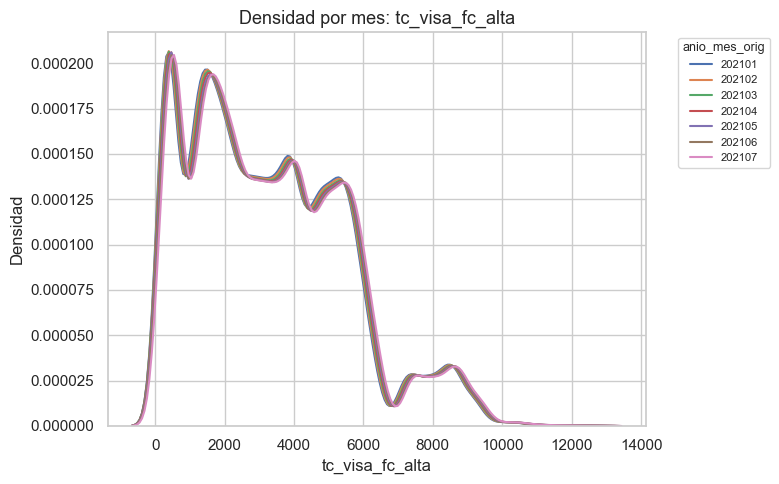

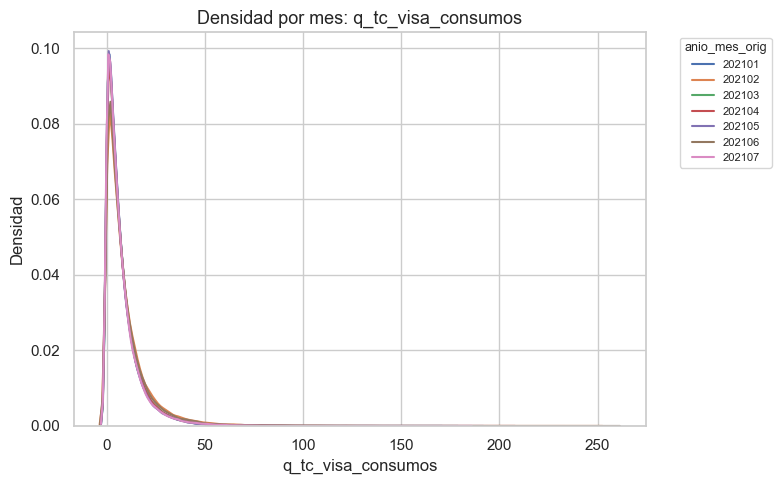

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df_plot = df.copy()

# ============================
# 1) Variables numéricas a graficar
# ============================
num_cols = df_plot.select_dtypes(include='number').columns.tolist()

# columnas a excluir
excluir = ['id','tc_visa_status', 'q_caja_seguridad','anio_mes_orig']
excluir += [c for c in num_cols if c.startswith('fl_')]

vars_num = [c for c in num_cols if c not in excluir]

print(f"Variables numéricas a graficar: {len(vars_num)}")
print(vars_num)

# ============================
# 2) Preparar anio_mes_orig como string para la leyenda
# ============================
if np.issubdtype(df_plot['anio_mes_orig'].dtype, np.datetime64):
    df_plot['anio_mes_str'] = df_plot['anio_mes_orig'].dt.to_period('M').astype(str)
else:
    df_plot['anio_mes_str'] = df_plot['anio_mes_orig'].astype(str)

meses = sorted(df_plot['anio_mes_str'].unique())

sns.set(style="whitegrid")

# ============================
# 3) Gráficos de densidad
# ============================
for col in vars_num:
    serie_all = df_plot[col].dropna()
    if serie_all.empty:
        continue

    plt.figure(figsize=(8, 5))

    for mes in meses:
        s = df_plot.loc[df_plot['anio_mes_str'] == mes, col].dropna()
        # si hay muy pocos datos ese mes, saltamos (KDE se vuelve inestable)
        if len(s) < 30:
            continue

        sns.kdeplot(
            s,
            fill=False,          # ✅ solo líneas, sin relleno
            linewidth=1.5,
            label=mes
        )

    plt.title(f"Densidad por mes: {col}", fontsize=13)
    plt.xlabel(col)
    plt.ylabel("Densidad")

    # leyenda a un costado
    plt.legend(
        title="anio_mes_orig",
        bbox_to_anchor=(1.05, 1),
        loc="upper left",
        fontsize=8,
        title_fontsize=9
    )

    plt.tight_layout()
    plt.show()


# Construcción de la clase ternaria

Se construye en base a la columna *flag_baja*, que indica si el cliente no aparece en el mes siguiente (1 = baja, 0 = continúa, NA = sin horizonte).

Lógica de asignación

Para cada fila (cliente en un mes t), se evalúa:
- target = 1 → baja+1
El cliente no aparece en el mes siguiente (t+1).
→ flag_baja(t) == 1
- target = 2 → baja+2
El cliente sí aparece en t+1, pero no aparece en t+2.
→ flag_baja(t) == 0 y flag_baja(t+1) == 1
- target = 0 → continúa
El cliente aparece tanto en t+1 como en t+2.
→ flag_baja(t) == 0 y flag_baja(t+1) == 0
- target = NA → indeterminado
No hay suficiente horizonte temporal para evaluar (por ejemplo, estamos en el último mes disponible).

In [17]:
import pandas as pd
import numpy as np

# ========= Preparación =========
df = df.sort_values(['id', 'anio_mes']).drop_duplicates(['id', 'anio_mes'], keep='last')

# ========= 1) Identificar el último mes disponible =========
max_mes = df['anio_mes'].max()

# ========= 2) Crear flag_baja para CADA mes =========
# flag_baja(t) = 1 si el cliente NO aparece en t+1
# Creamos un set con todas las combinaciones (id, mes) que existen
existentes = set(zip(df['id'], df['anio_mes']))

def tiene_registro_siguiente(row):
    """Verifica si el cliente tiene registro en el mes siguiente"""
    mes_siguiente = row['anio_mes'] + pd.offsets.MonthEnd(1)
    # Si el mes siguiente excede el máximo observado, devolvemos NA
    if mes_siguiente > max_mes:
        return pd.NA
    # Si existe registro en mes siguiente: 0 (no baja), sino: 1 (baja)
    return 0 if (row['id'], mes_siguiente) in existentes else 1

df['flag_baja'] = df.apply(tiene_registro_siguiente, axis=1)

# ========= 3) Crear diccionario de flag_baja por (id, mes) =========
# Esto nos permite buscar eficientemente el flag_baja de cualquier mes futuro
baja_dict = df.set_index(['id', 'anio_mes'])['flag_baja'].to_dict()

# ========= 4) Construir la target ternaria =========
def calcular_target(row):
    """
    Calcula target ternaria:
    - 1 (baja+1): cliente se da de baja en t+1 (no aparece en t+1)
    - 2 (baja+2): cliente NO se da de baja en t+1 pero SÍ en t+2
    - 0 (continúa): cliente NO se da de baja ni en t+1 ni en t+2
    - NA: no hay horizonte suficiente para determinar
    """
    id_cliente = row['id']
    mes_actual = row['anio_mes']
    
    # Calcular los meses futuros
    mes_plus1 = mes_actual + pd.offsets.MonthEnd(1)
    mes_plus2 = mes_actual + pd.offsets.MonthEnd(2)
    
    # Si no tenemos horizonte de 2 meses, devolvemos NA
    if mes_plus2 > max_mes:
        return pd.NA
    
    # Obtener flag_baja del mes actual
    flag_baja_actual = row['flag_baja']
    
    # Si ya hay NA en el mes actual (no podemos determinar), devolvemos NA
    if pd.isna(flag_baja_actual):
        return pd.NA
    
    # CASO 1: baja+1 (se da de baja en t+1, es decir, no aparece en t+1)
    if flag_baja_actual == 1:
        return 1
    
    # CASO 2 y 0: el cliente SÍ aparece en t+1
    # Necesitamos verificar qué pasa en t+1
    flag_baja_plus1 = baja_dict.get((id_cliente, mes_plus1), pd.NA)
    
    # Si no existe el registro en t+1 cuando esperábamos que existiera, hay inconsistencia
    if pd.isna(flag_baja_plus1):
        return pd.NA
    
    # CASO 2: baja+2 (aparece en t+1 pero se da de baja en t+2)
    if flag_baja_plus1 == 1:
        return 2
    
    # CASO 0: continúa (aparece tanto en t+1 como en t+2)
    if flag_baja_plus1 == 0:
        return 0
    
    # Por las dudas, cualquier otro caso
    return pd.NA

df['target'] = df.apply(calcular_target, axis=1).astype('Int8')

# ========= 5) Verificación =========
print("=" * 60)
print("DISTRIBUCIÓN DE TARGET (incluyendo NA):")
print("=" * 60)
print(df['target'].value_counts(dropna=False).sort_index())
print()

print("=" * 60)
print("DISTRIBUCIÓN POR MES:")
print("=" * 60)
conteo_mes = (
    df.dropna(subset=['target'])
      .groupby(['anio_mes', 'target'])
      .size()
      .reset_index(name='count')
      .pivot(index='anio_mes', columns='target', values='count')
      .fillna(0)
      .astype(int)
)
conteo_mes.columns.name = None
print(conteo_mes)
print()

# ========= 6) Filtro de población objetivo (antigüedad >= 3 meses) =========
# Solo DESPUÉS de crear la target, filtramos por antigüedad
df_filtrado = df[df['antiguedad_cliente'] >= 3].copy()

print("=" * 60)
print("DESPUÉS DE FILTRAR POR ANTIGÜEDAD >= 3:")
print("=" * 60)
print(df_filtrado['target'].value_counts(dropna=False).sort_index())
print()

conteo_mes_filtrado = (
    df_filtrado.dropna(subset=['target'])
      .groupby(['anio_mes', 'target'])
      .size()
      .reset_index(name='count')
      .pivot(index='anio_mes', columns='target', values='count')
      .fillna(0)
      .astype(int)
)
conteo_mes_filtrado.columns.name = None
print(conteo_mes_filtrado)

DISTRIBUCIÓN DE TARGET (incluyendo NA):
target
0       543592
1         1878
2         2315
<NA>    219437
Name: count, dtype: Int64

DISTRIBUCIÓN POR MES:
                 0    1    2
anio_mes                    
2021-01-31  108123   98  236
2021-02-28  108497  237  411
2021-03-31  109003  413  479
2021-04-30  108987  480  649
2021-05-31  108982  650  540

DESPUÉS DE FILTRAR POR ANTIGÜEDAD >= 3:
target
0       542153
1         1872
2         2309
<NA>    219133
Name: count, dtype: Int64

                 0    1    2
anio_mes                    
2021-01-31  107832   97  234
2021-02-28  108213  236  408
2021-03-31  108647  412  478
2021-04-30  108695  478  649
2021-05-31  108766  649  540


## Separación de las bases

In [18]:
df_train1 = df_filtrado[df_filtrado['anio_mes'] == '2021-03-31'].copy()
df_valid1 = df_filtrado[df_filtrado['anio_mes'] == '2021-04-30'].copy()
df_test1 = df_filtrado[df_filtrado['anio_mes'] == '2021-05-31'].copy()

In [19]:
df_train1.columns.to_list()

['id',
 'anio_mes',
 'fl_cliente_vip',
 'edad_cliente',
 'antiguedad_cliente',
 'q_productos',
 'q_cta_corriente',
 'vl_cta_corriente',
 'q_csav',
 'vl_csav',
 'vl_ctas_saldo',
 'q_td',
 'q_td_trx',
 'vl_td_trx',
 'q_tc_visa',
 'q_tc_visa_trx',
 'vl_tc_visa_consumo',
 'q_prest_pers',
 'vl_prest_pers',
 'q_prest_hipo',
 'vl_prest_hipo',
 'q_pl_fijo',
 'vl_pl_fijo_ars',
 'vl_pl_fijo_usd',
 'q_inv',
 'vl_inv_ars',
 'vl_inv_usd',
 'q_seg_vida',
 'q_seg_vivienda',
 'q_caja_seguridad',
 'q_haberes_trx',
 'vl_haberes',
 'q_deb_auto_ctas',
 'vl_deb_auto_ctas',
 'q_deb_auto_visa',
 'vl_deb_auto_visa',
 'q_pago_serv',
 'vl_pago_serv',
 'q_desc_td',
 'vl_desc_td',
 'q_desc_tc_visa',
 'vl_desc_tc_visa',
 'q_comisiones_mant',
 'vl_comisiones_mant',
 'q_comisiones_otras',
 'vl_comisiones_otras',
 'q_transf_in',
 'vl_transf_in',
 'q_transf_out',
 'vl_transf_out',
 'q_cheq_dep',
 'vl_cheq_dep',
 'q_cheq_emit',
 'vl_cheq_emit',
 'q_cheq_dep_rech',
 'vl_cheq_dep_rech',
 'q_cheq_emit_rech',
 'vl_cheq_emi

### Base entrenamiento

#### Comparación visual de Baja+1 y Baja+2

Variables numéricas a comparar: ['fl_cliente_vip', 'edad_cliente', 'antiguedad_cliente', 'q_productos', 'q_cta_corriente', 'vl_cta_corriente', 'q_csav', 'vl_csav', 'vl_ctas_saldo', 'q_td', 'q_td_trx', 'vl_td_trx', 'q_tc_visa', 'q_tc_visa_trx', 'vl_tc_visa_consumo', 'q_prest_pers', 'vl_prest_pers', 'q_prest_hipo', 'vl_prest_hipo', 'q_pl_fijo', 'vl_pl_fijo_ars', 'vl_pl_fijo_usd', 'q_inv', 'vl_inv_ars', 'vl_inv_usd', 'q_seg_vida', 'q_seg_vivienda', 'q_caja_seguridad', 'q_haberes_trx', 'vl_haberes', 'q_deb_auto_ctas', 'vl_deb_auto_ctas', 'q_deb_auto_visa', 'vl_deb_auto_visa', 'q_pago_serv', 'vl_pago_serv', 'q_desc_td', 'vl_desc_td', 'q_desc_tc_visa', 'vl_desc_tc_visa', 'q_comisiones_mant', 'vl_comisiones_mant', 'q_comisiones_otras', 'vl_comisiones_otras', 'q_transf_in', 'vl_transf_in', 'q_transf_out', 'vl_transf_out', 'q_cheq_dep', 'vl_cheq_dep', 'q_cheq_emit', 'vl_cheq_emit', 'q_cheq_dep_rech', 'vl_cheq_dep_rech', 'q_cheq_emit_rech', 'vl_cheq_emit_rech', 'fl_callcenter', 'q_callcenter_trx

C:\Users\facun\AppData\Local\Temp\ipykernel_21152\2558374663.py:18: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


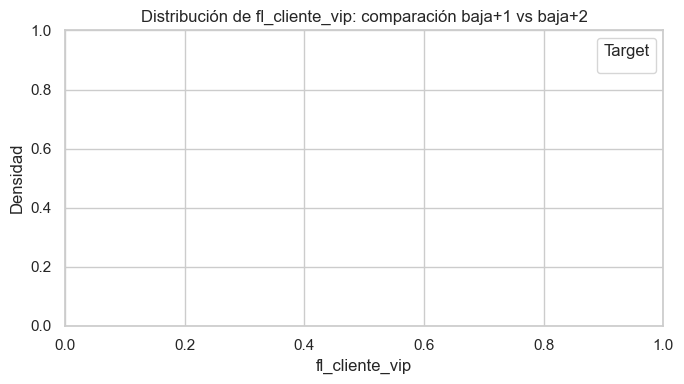

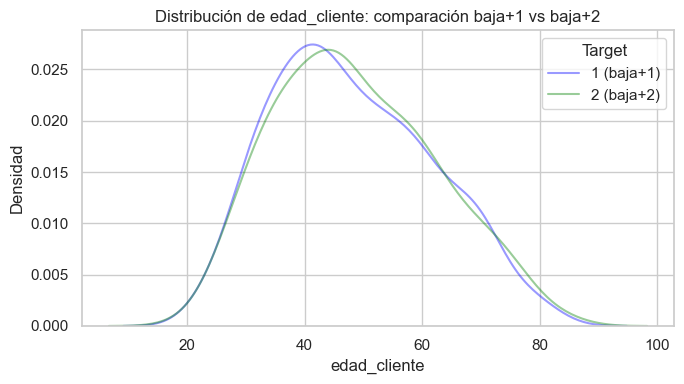

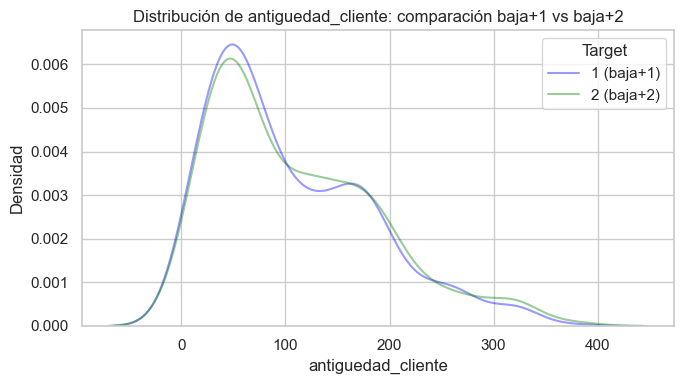

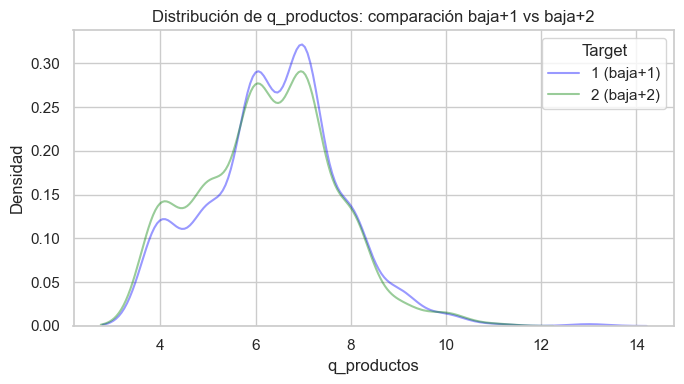

C:\Users\facun\AppData\Local\Temp\ipykernel_21152\2558374663.py:18: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


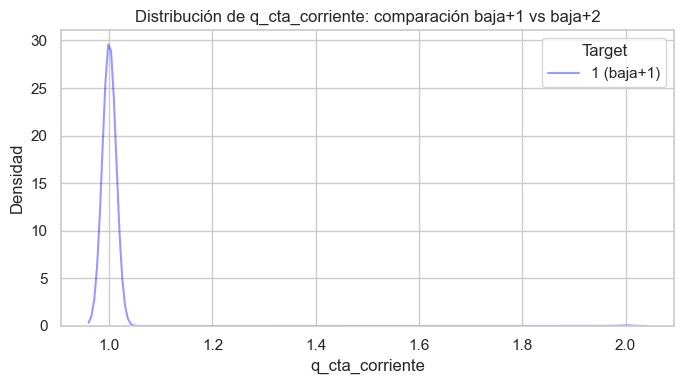

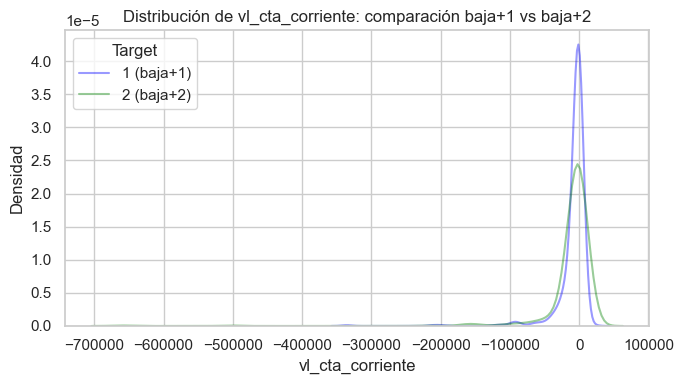

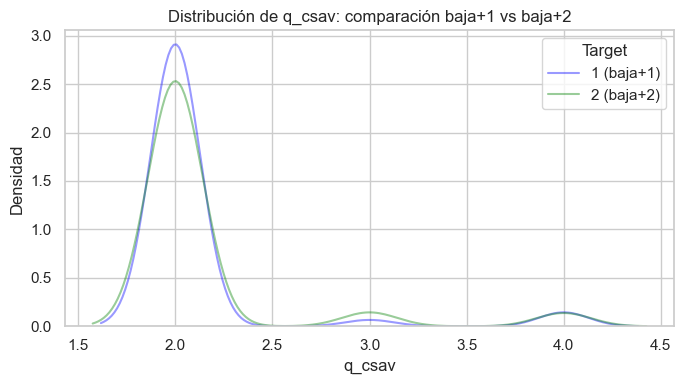

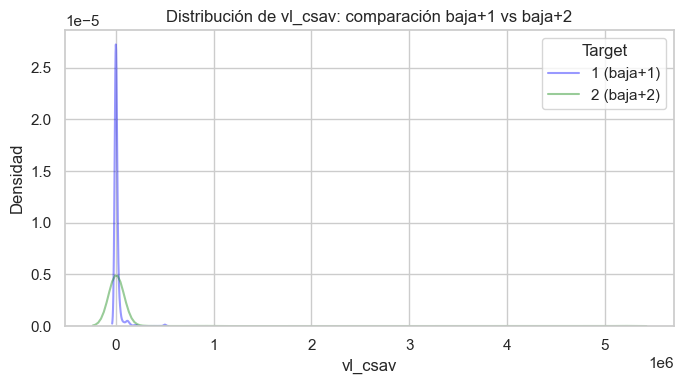

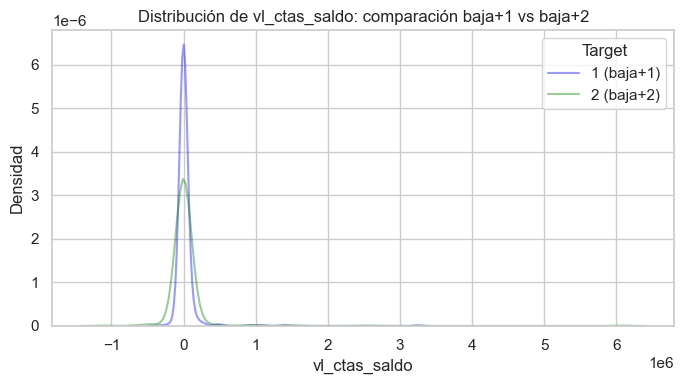

...

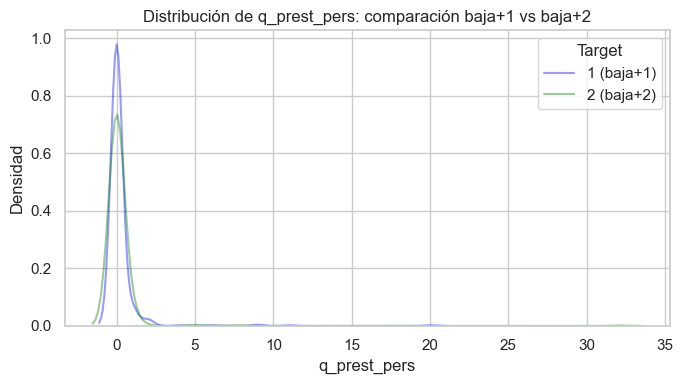

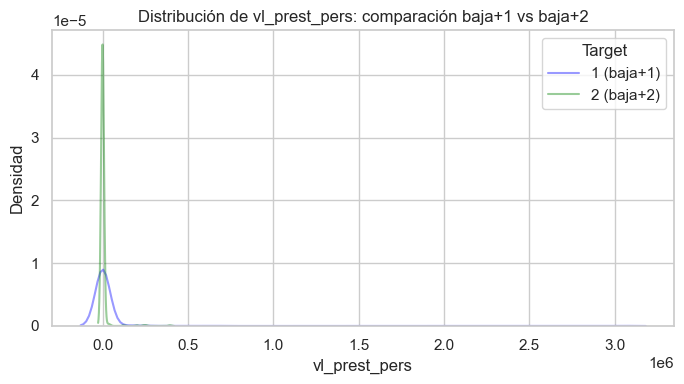

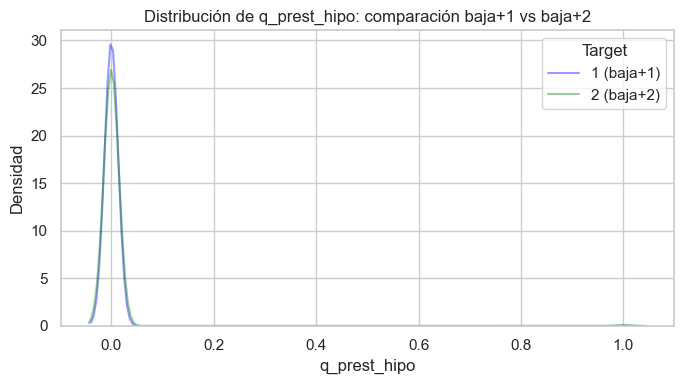

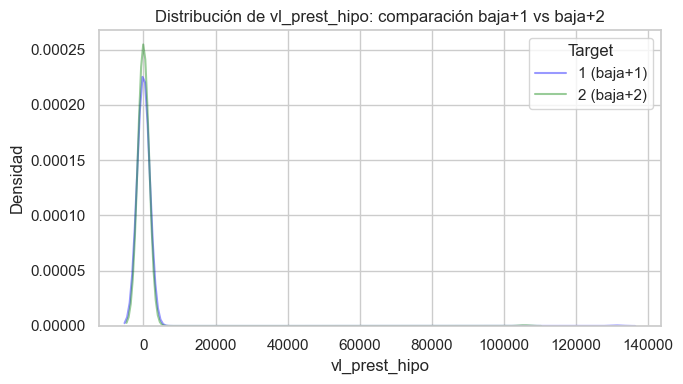

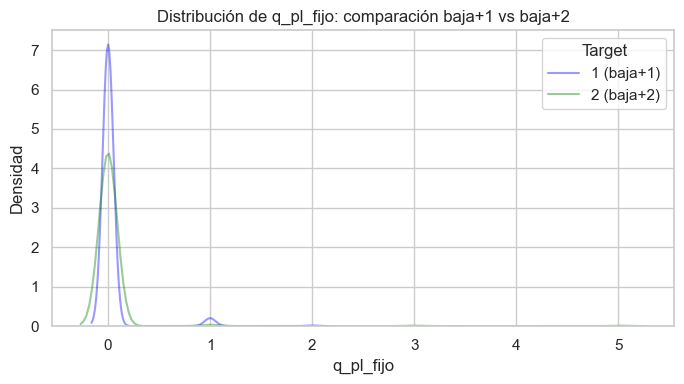

C:\Users\facun\AppData\Local\Temp\ipykernel_21152\2558374663.py:18: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


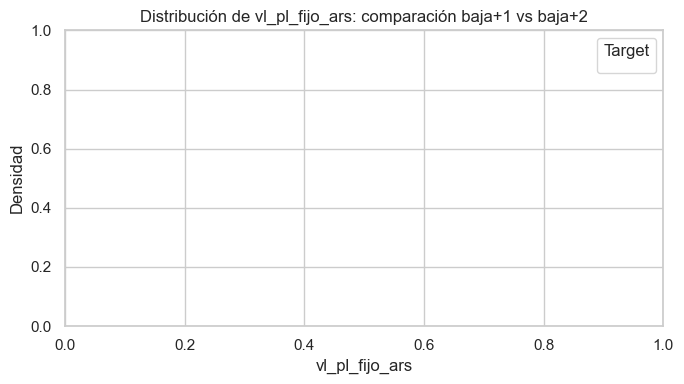

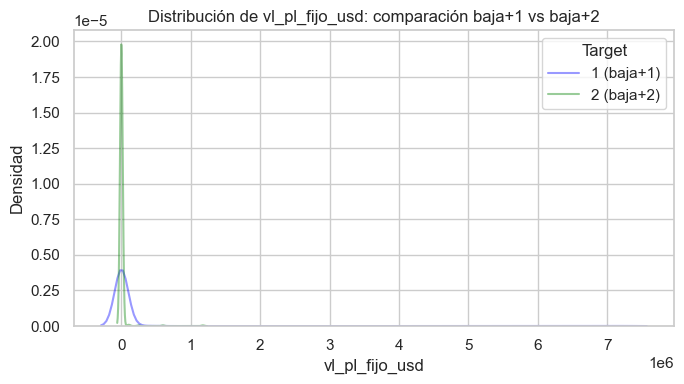

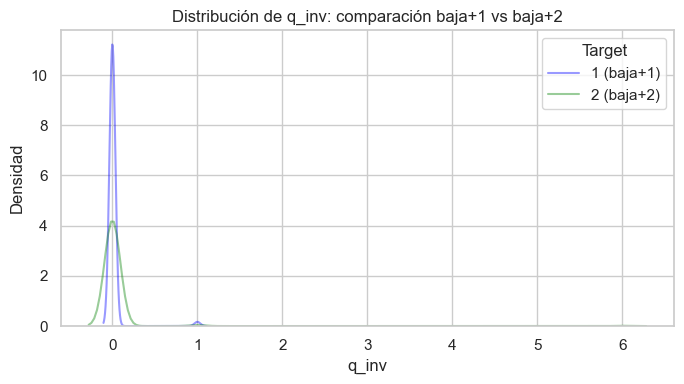

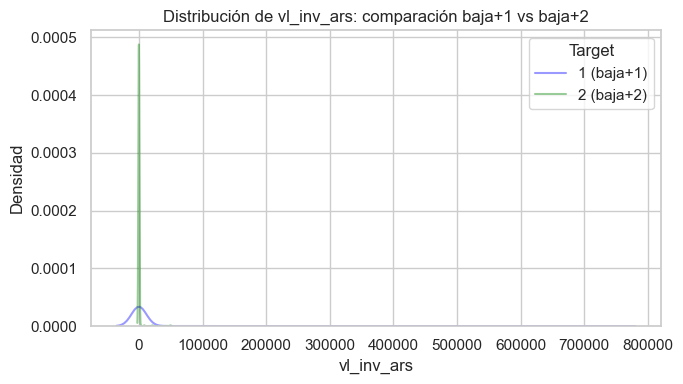

C:\Users\facun\AppData\Local\Temp\ipykernel_21152\2558374663.py:18: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


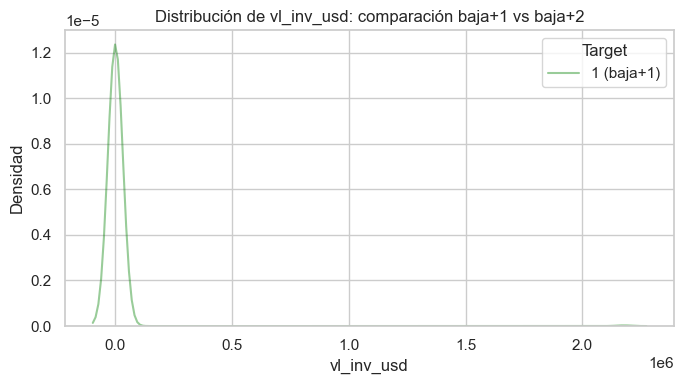

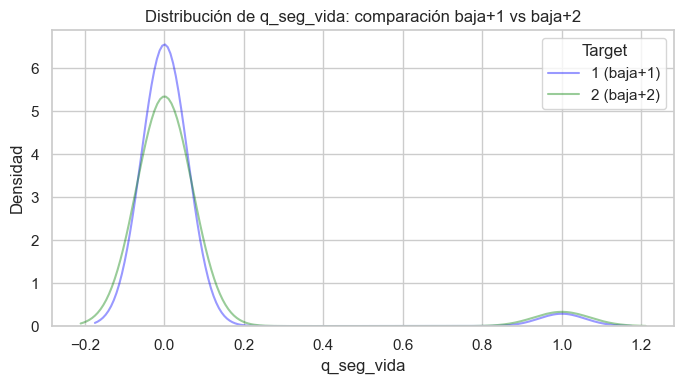

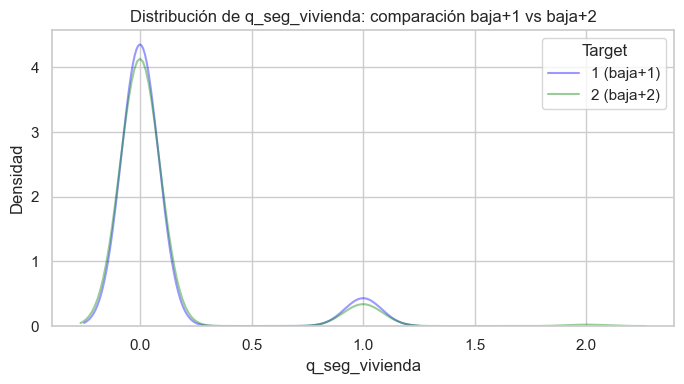

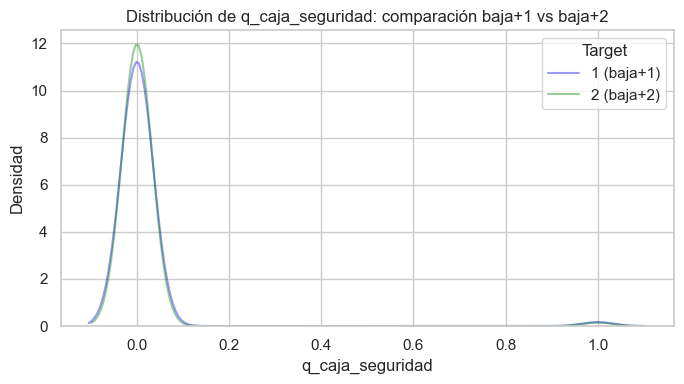

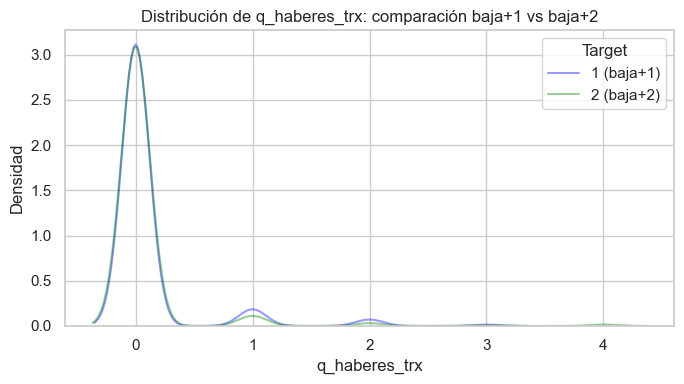

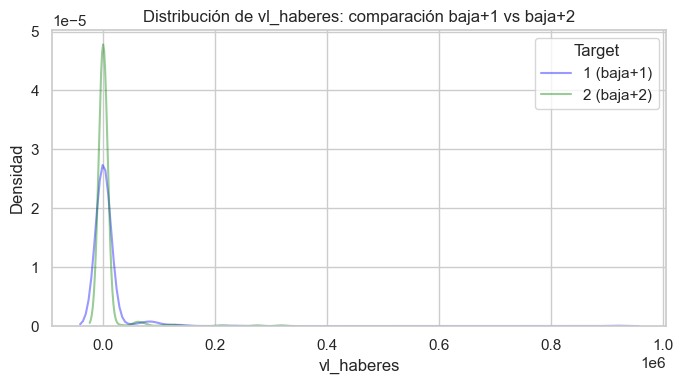

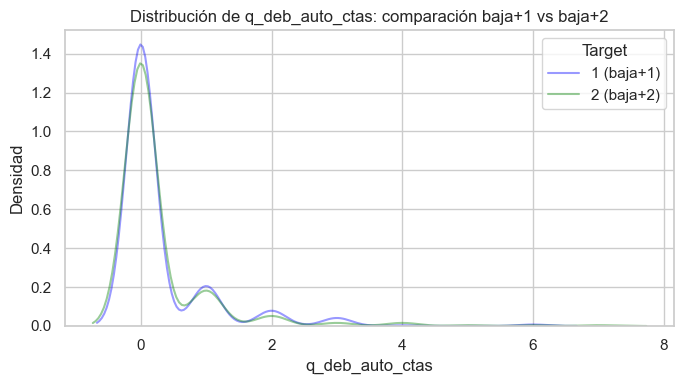

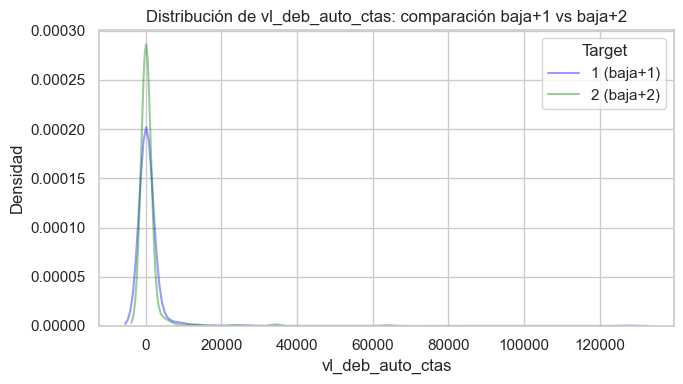

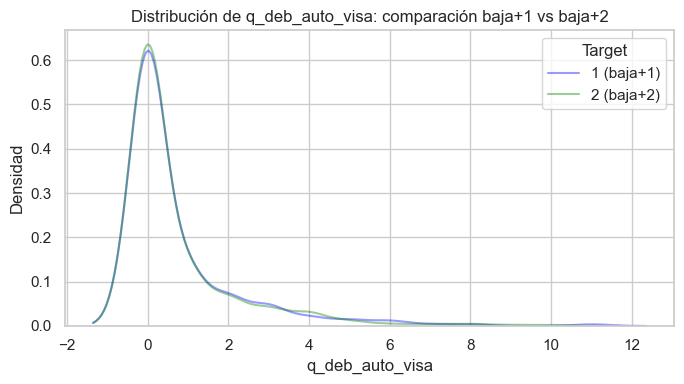

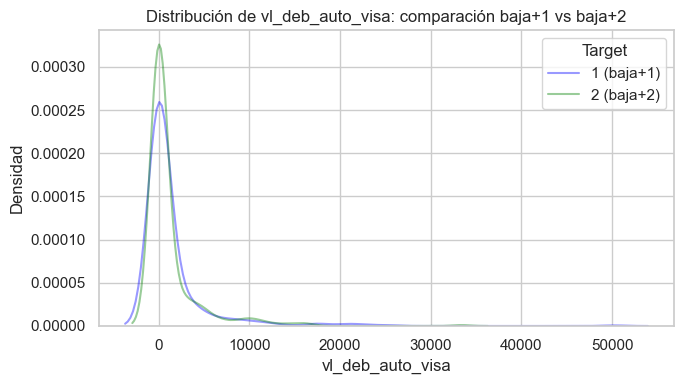

C:\Users\facun\AppData\Local\Temp\ipykernel_21152\2558374663.py:18: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


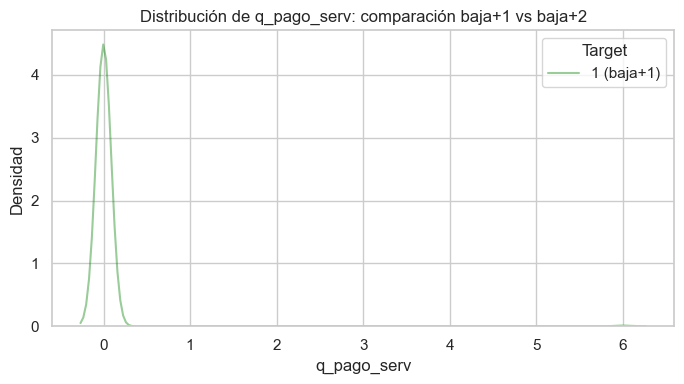

C:\Users\facun\AppData\Local\Temp\ipykernel_21152\2558374663.py:18: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


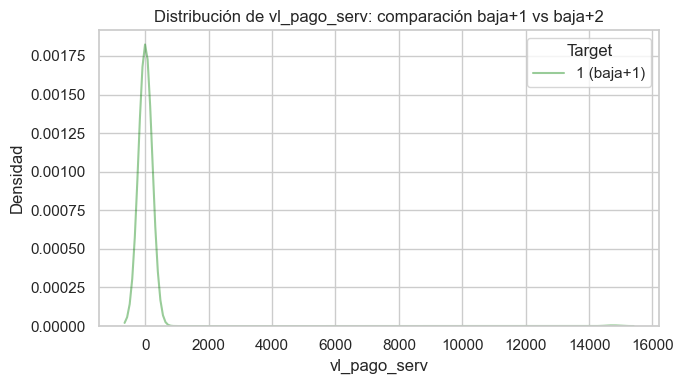

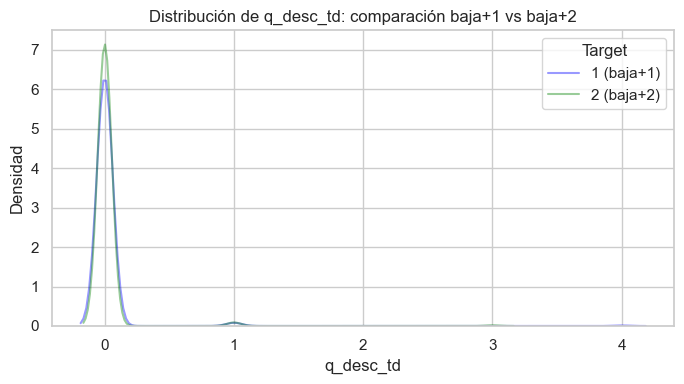

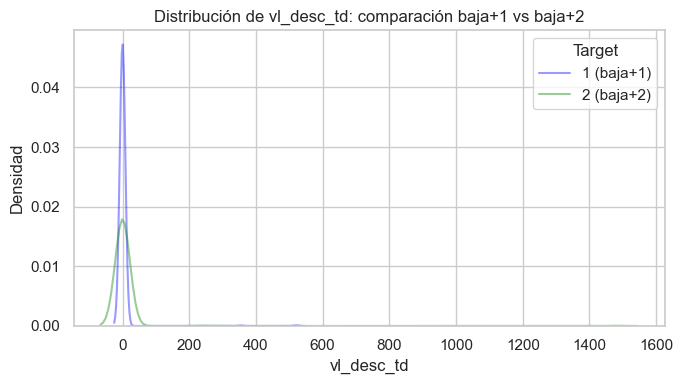

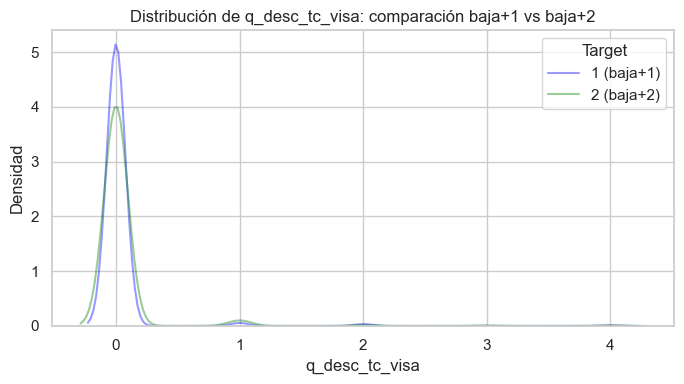

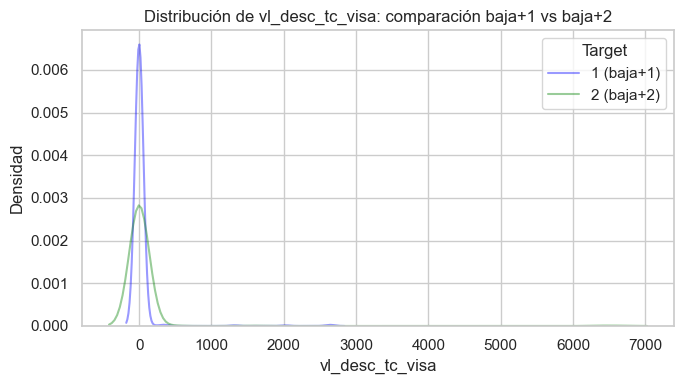

...

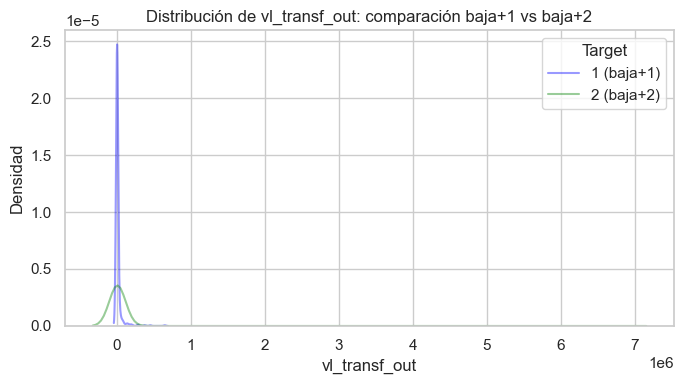

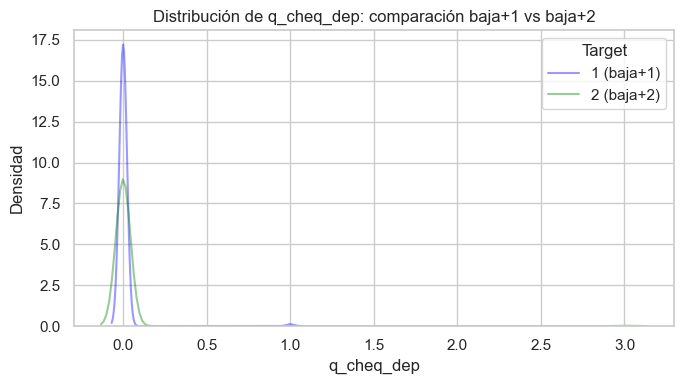

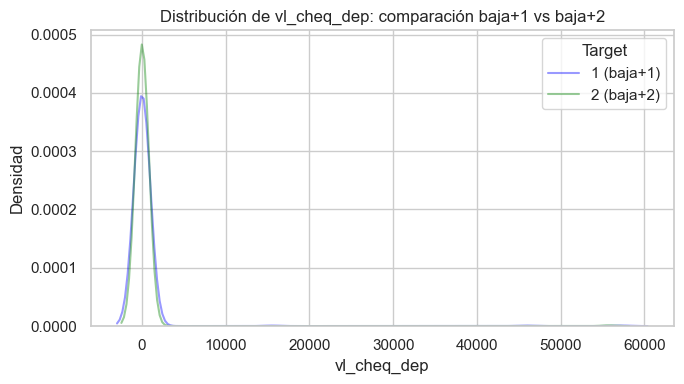

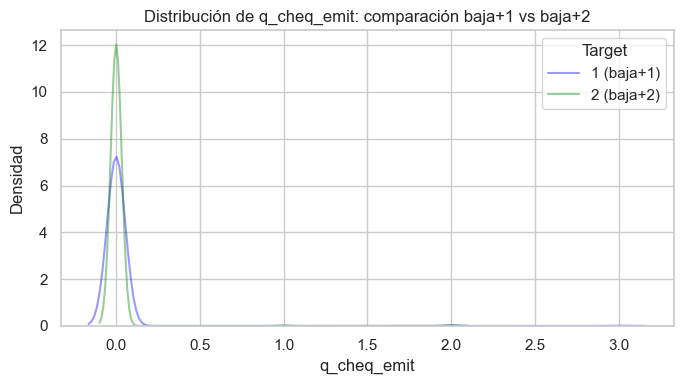

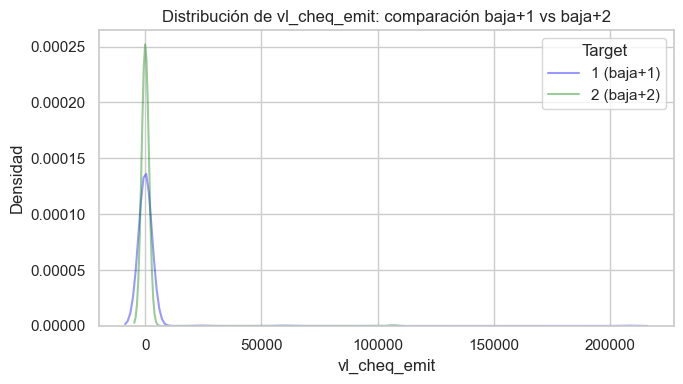

C:\Users\facun\AppData\Local\Temp\ipykernel_21152\2558374663.py:18: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


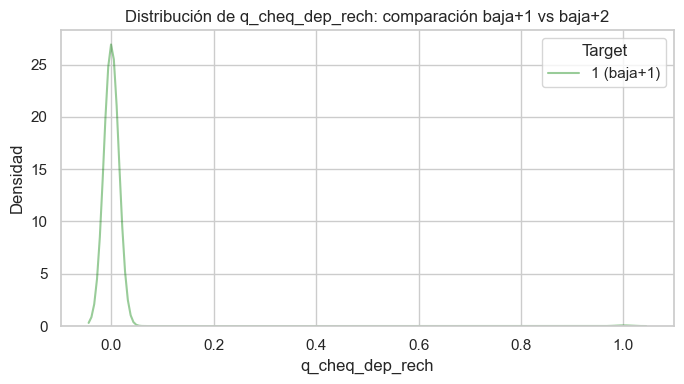

C:\Users\facun\AppData\Local\Temp\ipykernel_21152\2558374663.py:18: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


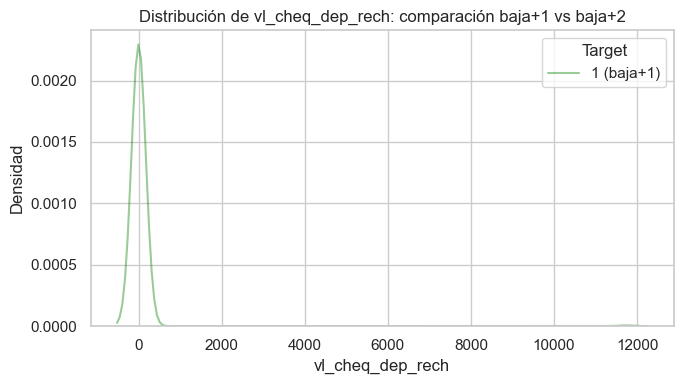

C:\Users\facun\AppData\Local\Temp\ipykernel_21152\2558374663.py:18: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


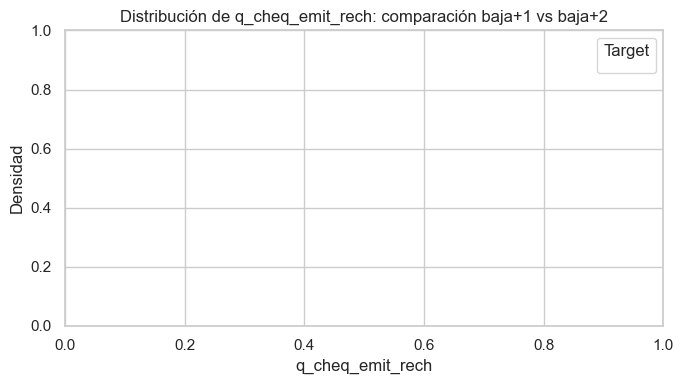

C:\Users\facun\AppData\Local\Temp\ipykernel_21152\2558374663.py:18: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


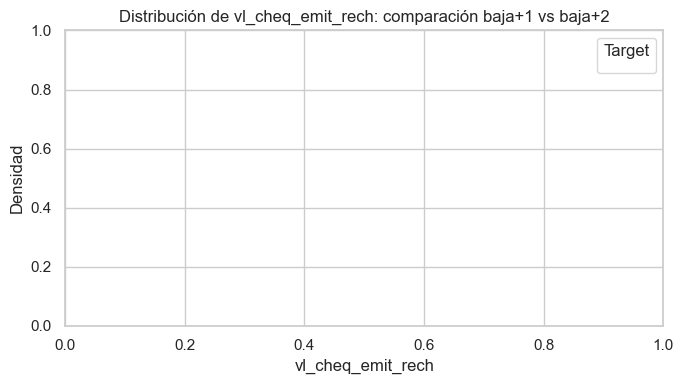

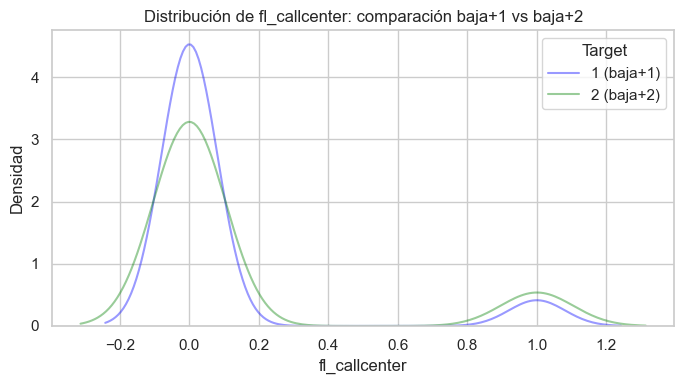

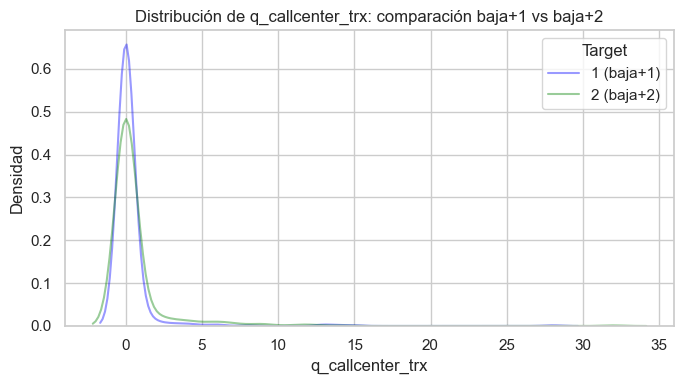

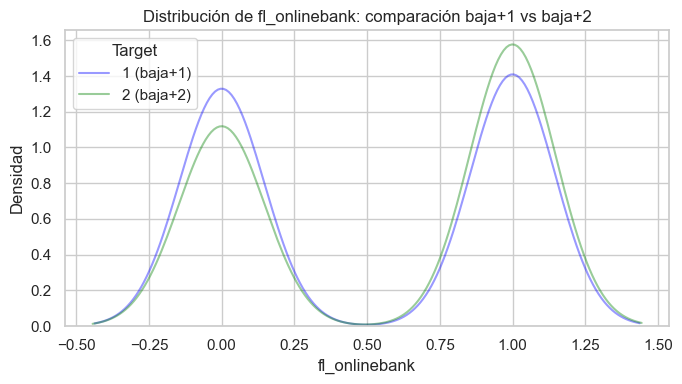

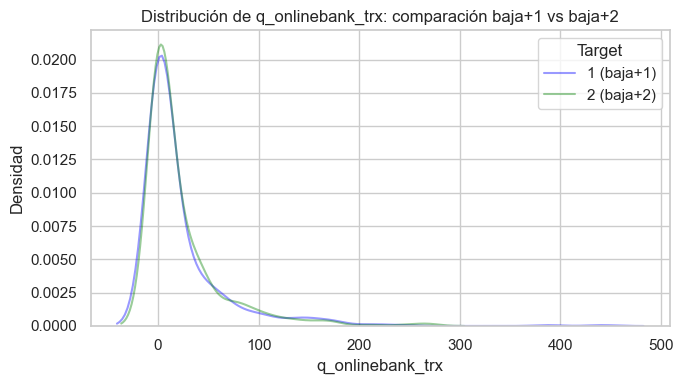

...

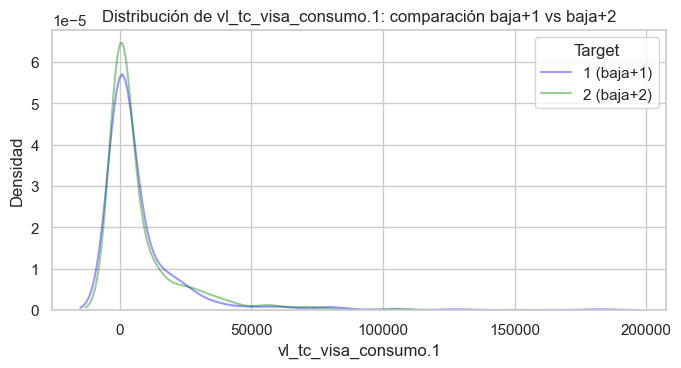

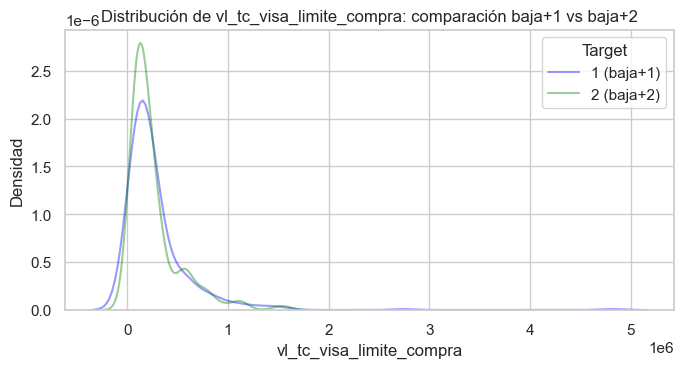

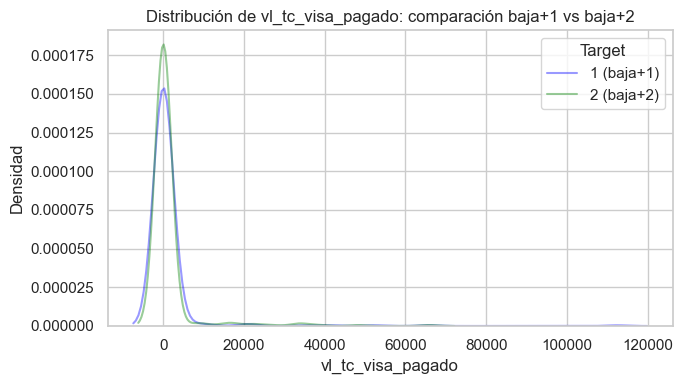

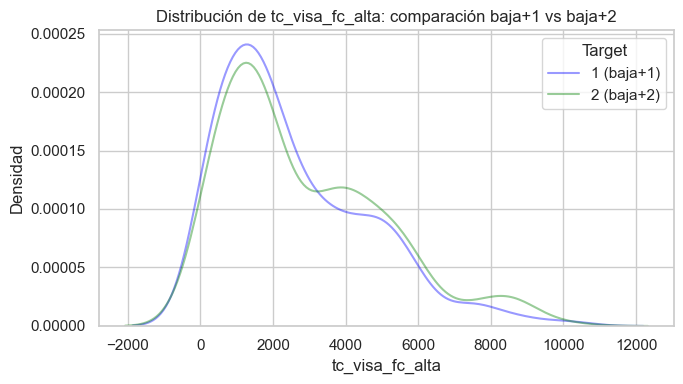

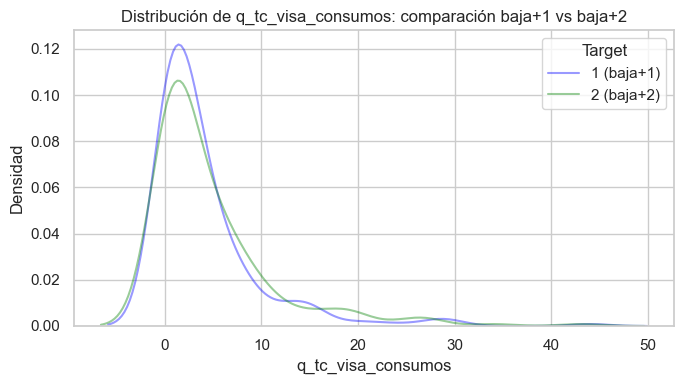

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. Filtro de base ---
df_entrenamiento = df_train1[df_train1['target'].isin([1, 2])].copy()

# --- 2. Seleccionar variables numéricas (excluyendo columnas auxiliares) ---
cols_excluir = ['id', 'anio_mes', 'flag_baja', 'anio_mes_orig', 'tc_visa_status_nominal', 'target']
vars_num = [c for c in df_train1.select_dtypes(include='number').columns if c not in cols_excluir]

print(f"Variables numéricas a comparar: {vars_num}")

# --- 3. Gráficos de densidad (KDE) comparando target=1 vs target=2 ---
sns.set(style="whitegrid", palette="muted")

for col in vars_num:
    plt.figure(figsize=(7,4))
    sns.kdeplot(
        data=df_entrenamiento, x=col, hue='target',
        fill=False, common_norm=False, alpha=0.4, linewidth=1.5,
        palette={1: 'green', 2: 'blue'}
    )
    plt.title(f'Distribución de {col}: comparación baja+1 vs baja+2')
    plt.xlabel(col)
    plt.ylabel('Densidad')
    plt.legend(title='Target', labels=['1 (baja+1)', '2 (baja+2)'])
    plt.tight_layout()
    plt.show()


En términos generales las distribuciones de Baja+1 y Baja+2 son similares en cuanto a la forma de distribución, aunque existen algunas diferencias entre ambas en variables relacionadas con montos, como *vl_csav*, *vl_pres_pers*, *vl_pl_fijo_usd*, *vl_invs_ars* y *vl_transf_out*.

Sin embargo, dado a que hay pocos casos de la variable target en comparación a los clientes que continúan, decidí continuar con la fusión de baja+1 y baja+2 en entrenamiento teniendo en cuenta estas diferencias en las variables mencionadas. 

### Agrupación Baja+1 y Baja+2

In [21]:
#Agrupo en una nueva variable la target
df_train1['target_new'] = np.where(df_train1['target'].isin([1, 2]), 1, 0)
print(df_train1['target_new'].value_counts())

target_new
0    108647
1       890
Name: count, dtype: int64


In [22]:
#Sólo para chequear
df_train1.shape

(109537, 83)

#### Descriptivos

In [23]:
df_train1.describe().T

,count,mean,min,25%,50%,75%,max,std
id,109537.0,89822162.17605,29183981.0,60571016.0,85333428.0,116595381.0,185277426.0,37535253.387018
anio_mes,109537,2021-03-31 00:00:00,2021-03-31 00:00:00,2021-03-31 00:00:00,2021-03-31 00:00:00,2021-03-31 00:00:00,2021-03-31 00:00:00,NaN
fl_cliente_vip,109537.0,0.002511,0.0,0.0,0.0,0.0,1.0,0.050043
edad_cliente,109537.0,46.866693,18.0,37.0,45.0,56.0,99.0,12.946355
antiguedad_cliente,109537.0,134.661055,3.0,63.0,127.0,189.0,375.0,85.606015
q_productos,109537.0,7.550919,3.0,7.0,7.0,8.0,17.0,1.488631
q_cta_corriente,109537.0,1.002629,1.0,1.0,1.0,1.0,5.0,0.052442
vl_cta_corriente,109537.0,2790.658979,-1631766.73,-962.51,0.0,0.0,23394149.69,105929.434934
q_csav,109537.0,2.129198,2.0,2.0,2.0,2.0,12.0,0.478519
vl_csav,109537.0,78477.535546,-1023.61,6720.22,25229.2,69783.72,12883120.34,220353.387279


#### Tabla de frecuencias 

##### Variables de cantidades

##### Desglosada

In [24]:
# =============================================================================
# 1) DICCIONARIO DE DESCRIPCIONES (solo variables que comienzan con q_)
#    Nota: tuve que cambiarle el nombre a dos de las variables del diccionario para que coincidan con el nombre
#    que tiene en la base (q_onlinebank_trx y vl_csav) 
# =============================================================================
desc_q = {
    "q_productos"        : "Cantidad de productos que el cliente posee con el banco (familias: tarjetas, préstamos, etc.).",
    "q_cta_corriente"    : "Cantidad de cuentas corrientes que tiene el cliente.",
    "q_csav"             : "Cantidad de cajas de ahorro que tiene el cliente.",
    "q_td"               : "Cantidad de tarjetas de débito que posee el cliente.",
    "q_td_trx"           : "Cantidad de transacciones con tarjeta de débito durante el mes.",
    "q_tc_visa"          : "Cantidad de cuentas VISA que posee el cliente.",
    "q_tc_visa_trx"      : "Cantidad de transacciones efectuadas en el mes con la TC VISA.",
    "q_prest_pers"       : "Cantidad de préstamos personales vigentes del cliente.",
    "q_prest_hipo"       : "Cantidad de préstamos hipotecarios vigentes del cliente.",
    "q_pl_fijo"          : "Cantidad de plazos fijos del cliente (cualquier moneda).",
    "q_inv"              : "Cantidad de inversiones vigentes del cliente.",
    "q_seg_vida"         : "Cantidad de seguros de vida contratados voluntariamente por el cliente.",
    "q_seg_vivienda"     : "Cantidad de seguros de vivienda contratados voluntariamente por el cliente.",
    "q_caja_seguridad"   : "Indica si el cliente tiene cajas de seguridad (suele ser 0/1).",
    "q_haberes_trx"      : "Cantidad de acreditaciones de haberes en relación de dependencia del mes.",
    "q_deb_auto_ctas"    : "Cantidad de débitos automáticos en cuentas durante el mes.",
    "q_deb_auto_visa"    : "Cantidad de débitos automáticos en la tarjeta VISA durante el mes.",
    "q_pago_serv"        : "Cantidad de pagos de servicios efectuados durante el mes.",
    "q_desc_td"          : "Cantidad de descuentos con tarjeta de débito de los que se benefició el cliente en el mes.",
    "q_desc_tc_visa"     : "Cantidad de descuentos con tarjeta de crédito VISA de los que se benefició el cliente en el mes.",
    "q_comisiones_mant"  : "Cantidad de comisiones de mantenimiento cobradas durante el mes.",
    "q_comisiones_otras" : "Cantidad de otras comisiones cobradas durante el mes.",
    "q_transf_in"        : "Cantidad de transferencias recibidas en el mes (todas las cuentas).",
    "q_transf_out"       : "Cantidad de transferencias emitidas en el mes (todas las cuentas).",
    "q_cheq_dep"         : "Cantidad de cheques depositados en cuentas del cliente durante el mes.",
    "q_cheq_emit"        : "Cantidad de cheques del cliente que se cobraron durante el mes.",
    "q_cheq_dep_rech"    : "Cantidad de cheques depositados en cuentas del cliente que fueron rechazados (mes).",
    "q_ched_dep_rech"    : "Cantidad de cheques depositados rechazados (alias por si viene con esta variante de nombre).",
    "q_cheq_emit_rech"   : "Cantidad de cheques emitidos por el cliente que fueron rechazados (mes).",
    "q_callcenter_trx"   : "Cantidad de transacciones por canal de banca telefónica en el mes.",
    "q_onlinebank_trx"   : "Cantidad de transacciones por Online Banking en el mes.",
    "q_cajas_trx"        : "Cantidad de transacciones en línea de cajas de sucursales en el mes.",
    "q_atm_trx"          : "Cantidad de transacciones en cajeros automáticos propios en el mes.",
    "q_atm2_trx"         : "Cantidad de transacciones en cajeros automáticos de otras redes en el mes.",
    "q_trx_trim"         : "Cantidad de movimientos voluntarios en cuentas en los últimos 90 días.",
    "q_app_trx"          : "Cantidad de transacciones realizadas desde la app móvil en el mes.",
    "q_tc_visa_consumos" : "Cantidad de consumos con la tarjeta de crédito VISA durante el mes.",
}

# Variables q_ presentes
cols_q = [c for c in df_train1.columns if c.startswith('q_')]
print(f"Variables 'q_' encontradas: {len(cols_q)}")

# --- Función: tabla combinada n + % por target_new ---
def tabla_frecuencia_combinada(df, col_q, id_col='id', target_col='target_new', round_pct=2):
    # Conteos de IDs únicos
    counts = (
        df.groupby([target_col, col_q])[id_col]
          .nunique()
          .reset_index(name='n_clientes')
          .pivot(index=col_q, columns=target_col, values='n_clientes')
          .fillna(0)
          .astype(int)
    )

    # Asegurar orden de columnas (0,1)
    cols_order = [c for c in [0,1] if c in counts.columns] + [c for c in counts.columns if c not in [0,1]]
    counts = counts[cols_order]

    # Porcentajes por columna (target_new)
    pct = (counts / counts.sum(axis=0)).replace([np.inf, np.nan], 0.0) * 100
    pct = pct.round(round_pct)

    # Combinado (n y % lado a lado)
    combo = pd.concat({'n': counts, '%': pct}, axis=1)
    combo = combo.swaplevel(axis=1).sort_index(axis=1)  # (target_new, n/%)
    return combo

# --- Generar y mostrar tabla combinada para cada variable ---
tablas_combinadas = {}

for col in cols_q:
    combo = tabla_frecuencia_combinada(df_train1, col_q=col)
    tablas_combinadas[col] = combo

    desc = desc_q.get(col, "(sin descripción disponible)")
    print("="*110)
    print(f"📊 Variable: {col}")
    print(f"📝 Descripción: {desc}")
    print("-"*110)
    print(combo)
    print("\n")

Variables 'q_' encontradas: 36
📊 Variable: q_productos
📝 Descripción: Cantidad de productos que el cliente posee con el banco (familias: tarjetas, préstamos, etc.).
--------------------------------------------------------------------------------------------------------------
target_new       0             1     
                 %      n      %    n
q_productos                          
3             0.01      7   0.00    0
4             1.27   1381  12.70  113
5             2.78   3019  13.60  121
6            19.10  20755  26.97  240
7            30.83  33491  29.55  263
8            23.22  25232  12.36  110
9            12.79  13901   3.15   28
10            6.10   6628   1.35   12
11            2.56   2786   0.22    2
12            0.92    996   0.00    0
13            0.29    320   0.11    1
14            0.10    105   0.00    0
15            0.02     19   0.00    0
16            0.00      4   0.00    0
17            0.00      3   0.00    0


📊 Variable: q_cta_corriente
📝 Descripc

##### Agrupada

In [25]:
import numpy as np
import pandas as pd
# =============================================================================
# 1) DICCIONARIO DE DESCRIPCIONES (solo variables que comienzan con q_)
#    Nota: tuve que cambiarle el nombre a dos de las variables del diccionario para que coincidan con el nombre
#    que tiene en la base (q_onlinebank_trx y vl_csav) 
# =============================================================================
desc_q = {
    "q_productos"        : "Cantidad de productos que el cliente posee con el banco (familias: tarjetas, préstamos, etc.).",
    "q_cta_corriente"    : "Cantidad de cuentas corrientes que tiene el cliente.",
    "q_csav"             : "Cantidad de cajas de ahorro que tiene el cliente.",
    "q_td"               : "Cantidad de tarjetas de débito que posee el cliente.",
    "q_td_trx"           : "Cantidad de transacciones con tarjeta de débito durante el mes.",
    "q_tc_visa"          : "Cantidad de cuentas VISA que posee el cliente.",
    "q_tc_visa_trx"      : "Cantidad de transacciones efectuadas en el mes con la TC VISA.",
    "q_prest_pers"       : "Cantidad de préstamos personales vigentes del cliente.",
    "q_prest_hipo"       : "Cantidad de préstamos hipotecarios vigentes del cliente.",
    "q_pl_fijo"          : "Cantidad de plazos fijos del cliente (cualquier moneda).",
    "q_inv"              : "Cantidad de inversiones vigentes del cliente.",
    "q_seg_vida"         : "Cantidad de seguros de vida contratados voluntariamente por el cliente.",
    "q_seg_vivienda"     : "Cantidad de seguros de vivienda contratados voluntariamente por el cliente.",
    "q_caja_seguridad"   : "Indica si el cliente tiene cajas de seguridad (suele ser 0/1).",
    "q_haberes_trx"      : "Cantidad de acreditaciones de haberes en relación de dependencia del mes.",
    "q_deb_auto_ctas"    : "Cantidad de débitos automáticos en cuentas durante el mes.",
    "q_deb_auto_visa"    : "Cantidad de débitos automáticos en la tarjeta VISA durante el mes.",
    "q_pago_serv"        : "Cantidad de pagos de servicios efectuados durante el mes.",
    "q_desc_td"          : "Cantidad de descuentos con tarjeta de débito de los que se benefició el cliente en el mes.",
    "q_desc_tc_visa"     : "Cantidad de descuentos con tarjeta de crédito VISA de los que se benefició el cliente en el mes.",
    "q_comisiones_mant"  : "Cantidad de comisiones de mantenimiento cobradas durante el mes.",
    "q_comisiones_otras" : "Cantidad de otras comisiones cobradas durante el mes.",
    "q_transf_in"        : "Cantidad de transferencias recibidas en el mes (todas las cuentas).",
    "q_transf_out"       : "Cantidad de transferencias emitidas en el mes (todas las cuentas).",
    "q_cheq_dep"         : "Cantidad de cheques depositados en cuentas del cliente durante el mes.",
    "q_cheq_emit"        : "Cantidad de cheques del cliente que se cobraron durante el mes.",
    "q_cheq_dep_rech"    : "Cantidad de cheques depositados en cuentas del cliente que fueron rechazados (mes).",
    "q_ched_dep_rech"    : "Cantidad de cheques depositados rechazados (alias por si viene con esta variante de nombre).",
    "q_cheq_emit_rech"   : "Cantidad de cheques emitidos por el cliente que fueron rechazados (mes).",
    "q_callcenter_trx"   : "Cantidad de transacciones por canal de banca telefónica en el mes.",
    "q_onlinebank_trx"   : "Cantidad de transacciones por Online Banking en el mes.",
    "q_cajas_trx"        : "Cantidad de transacciones en línea de cajas de sucursales en el mes.",
    "q_atm_trx"          : "Cantidad de transacciones en cajeros automáticos propios en el mes.",
    "q_atm2_trx"         : "Cantidad de transacciones en cajeros automáticos de otras redes en el mes.",
    "q_trx_trim"         : "Cantidad de movimientos voluntarios en cuentas en los últimos 90 días.",
    "q_app_trx"          : "Cantidad de transacciones realizadas desde la app móvil en el mes.",
    "q_tc_visa_consumos" : "Cantidad de consumos con la tarjeta de crédito VISA durante el mes.",
}

# Variables q_ presentes
cols_q = [c for c in df_train1.columns if c.startswith('q_')]
print(f"Variables 'q_' encontradas: {len(cols_q)}")

def tabla_frecuencia_combinada(
        df,
        col_q,
        id_col='id',
        target_col='target_new',
        round_pct=2,
        agrupar_rangos=True
    ):
    """
    Si agrupar_rangos=True y la variable tiene muchos valores numéricos,
    la agrupa en rangos antes de armar la tabla de frecuencias.
    """

    serie_original = df[col_q]

    # --- 1) Definir cómo se va a agrupar la variable ---
    if agrupar_rangos and pd.api.types.is_numeric_dtype(serie_original):
        n_unique = serie_original.nunique(dropna=True)
        rango = serie_original.max() - serie_original.min()

        # Regla simple: si tiene muchos valores distintos -> agrupo
        if n_unique > 10 or rango > 10:
            # Bins genéricos para "conteos" tipo q_
            bins = [-0.1, 0, 1, 3, 5, 10, 20, 50, 100, np.inf]
            labels = ['0', '1', '2-3', '4-5', '6-10',
                      '11-20', '21-50', '51-100', '>100']

            serie_binned = pd.cut(
                serie_original,
                bins=bins,
                labels=labels,
                include_lowest=True
            )

            # Manejo de NAs: los dejo como categoría "NA"
            serie_final = serie_binned.astype(object)
            serie_final = serie_final.where(serie_original.notna(), other='NA')

            nombre_grupo = f"{col_q}_rango"
        else:
            # Pocos valores distintos -> uso el valor tal cual
            serie_final = serie_original.where(serie_original.notna(), other='NA')
            nombre_grupo = col_q
    else:
        # No se agrupa en rangos o no es numérica
        serie_final = serie_original.where(serie_original.notna(), other='NA')
        nombre_grupo = col_q

    # --- 2) Armar un df auxiliar con la variable (posiblemente agrupada) ---
    df_aux = df.copy()
    df_aux[nombre_grupo] = serie_final

    # --- 3) Conteos de IDs únicos por target y grupo ---
    counts = (
        df_aux.groupby([target_col, nombre_grupo])[id_col]
              .nunique()
              .reset_index(name='n_clientes')
              .pivot(index=nombre_grupo, columns=target_col, values='n_clientes')
              .fillna(0)
              .astype(int)
    )

    # 🔥 SI LA VARIABLE TIENE RANGOS, ORDENARLOS EXPLÍCITAMENTE
    if 'labels' in locals():  # existe solo si la variable fue agrupada
        counts = counts.reindex(labels, fill_value=0)
    

    # --- 4) Asegurar orden de columnas ---
    cols_order = [c for c in [0, 1] if c in counts.columns] + \
                 [c for c in counts.columns if c not in [0, 1]]
    counts = counts[cols_order]

    # --- 5) Porcentajes por columna (target_new) ---
    pct = (counts / counts.sum(axis=0)).replace([np.inf, np.nan], 0.0) * 100
    pct = pct.round(round_pct)

    # --- 6) Combinado (n y % lado a lado) ---
    combo = pd.concat({'n': counts, '%': pct}, axis=1)
    combo = combo.swaplevel(axis=1).sort_index(axis=1)  # (target_new, n/%)

    return combo

tablas_combinadas = {}

for col in cols_q:
    combo = tabla_frecuencia_combinada(df_train1, col_q=col, agrupar_rangos=True)
    tablas_combinadas[col] = combo

    desc = desc_q.get(col, "(sin descripción disponible)")
    print("="*110)
    print(f"📊 Variable: {col}")
    print(f"📝 Descripción: {desc}")
    print("-"*110)
    print(combo)
    print("\n")


Variables 'q_' encontradas: 36
📊 Variable: q_productos
📝 Descripción: Cantidad de productos que el cliente posee con el banco (familias: tarjetas, préstamos, etc.).
--------------------------------------------------------------------------------------------------------------
target_new             0              1     
                       %       n      %    n
q_productos_rango                           
0                   0.00       0   0.00    0
1                   0.00       0   0.00    0
2-3                 0.01       7   0.00    0
4-5                 4.05    4400  26.29  234
6-10               92.05  100007  73.37  653
11-20               3.90    4233   0.34    3
21-50               0.00       0   0.00    0
51-100              0.00       0   0.00    0
>100                0.00       0   0.00    0


📊 Variable: q_cta_corriente
📝 Descripción: Cantidad de cuentas corrientes que tiene el cliente.
--------------------------------------------------------------------------------------

La variable q_app_trx, si bien está definida como la cantidad de transacciones realizadas desde la app en el mes, parece ser una variable dicotómica. Lo mismo sucede con q_cajas_trx.

##### Variables de flags y "tc_"

In [26]:
import numpy as np
import pandas as pd

desc_fl_tc = {
    # ---------------------
    # Variables que comienzan con "fl_"
    # ---------------------
    "fl_cliente_vip": "Indica si el cliente es considerado cliente VIP.",
    "fl_callcenter": "Indica si la persona está adherida al canal de banca telefónica.",
    "fl_onlinebank": "Indica si el cliente está adherido al canal de Online Banking.",
    "fl_app": "Indica si la persona instaló alguna vez la aplicación móvil.",

    # ---------------------
    # Variables que comienzan con "tc_"
    # ---------------------
    "tc_visa_delinquency": (
        "Indica si el cliente no completó el pago mínimo y se encuentra moroso. "
        "Estos clientes no pueden utilizar la tarjeta hasta regularizar su situación."
    ),
    "tc_visa_status": (
        "Código de estado de la cuenta de tarjeta de crédito VISA: "
        "Abajo está la tabla con las etiquetas correspondientes."
    ),
    "tc_visa_status_nominal": (
        "Código de estado de la cuenta de tarjeta de crédito VISA: "
        "{0: abierta, 6: en proceso de cierre, 7: proceso avanzado de cierre, 9: cuenta cerrada}."
    ),
    "tc_visa_fc_alta_rango": "La variable original es la cantidad de días desde el alta"
    "de la cuenta de la tarjeta de crédito. Se agrupa en rangos anuales para facilitar el análisis.",
}

# =============================================================================
# 1) FUNCIÓN: tabla combinada (n y %) por target_new para una variable dada
# =============================================================================
def tabla_frecuencia_combinada(df, col, id_col='id', target_col='target_new', round_pct=2):
    """
    Devuelve un DataFrame con columnas MultiIndex:
      (target_new, 'n') y (target_new, '%'), donde
      'n' = cantidad de IDs únicos y '%' = porcentaje por columna (suma 100% por target).
    """
    counts = (
        df.groupby([target_col, col])[id_col]
          .nunique()
          .reset_index(name='n_clientes')
          .pivot(index=col, columns=target_col, values='n_clientes')
          .fillna(0)
          .astype(int)
    )

    cols_order = [c for c in [0, 1] if c in counts.columns] + \
                 [c for c in counts.columns if c not in [0, 1]]
    counts = counts[cols_order]

    pct = (counts / counts.sum(axis=0)).replace([np.inf, np.nan], 0.0) * 100
    pct = pct.round(round_pct)

    combo = pd.concat({'n': counts, '%': pct}, axis=1)
    combo = combo.swaplevel(axis=1).sort_index(axis=1)  # (target_new, n/%)
    return combo

# =============================================================================
# 2) RECORRER PREFIJOS fl_ y tc_ Y MOSTRAR TABLAS
#    (tc_visa_fc_alta se agrupa por rangos)
# =============================================================================
prefijos = ['fl_', 'tc_']

for prefix in prefijos:
    cols_prefijo = [c for c in df_train1.columns if c.startswith(prefix)]
    print(f"\n{'#'*110}")
    print(f"### Análisis de variables con prefijo '{prefix}' (encontradas: {len(cols_prefijo)})")
    print(f"{'#'*110}\n")

    if not cols_prefijo:
        print(f"(No se encontraron columnas que comiencen con '{prefix}' en df_train)\n")
        continue

    for col in cols_prefijo:
        col_para_tabla = col
        nota_extra = ""

        # 👉 caso especial: agrupar tc_visa_fc_alta en rangos
        if col == "tc_visa_fc_alta":
            # rangos de días: podés ajustarlos si querés
            bins = [-np.inf,
                    365,        # hasta 1 año
                    3*365,      # 1–3 años
                    5*365,      # 3–5 años
                    np.inf]     # 5+ años

            labels = ["≤1 año", "1–3 años", "3–5 años", "≥5 años"]

            col_para_tabla = "tc_visa_fc_alta_rango"
            df_train1[col_para_tabla] = pd.cut(
                df_train1[col],
                bins=bins,
                labels=labels,
                include_lowest=True
            )
            nota_extra = " (agrupada por rangos de días)"

        combo = tabla_frecuencia_combinada(df_train1, col_para_tabla)
        desc = desc_fl_tc.get(col, "(sin descripción disponible)")

        print("="*110)
        print(f"📊 Variable: {col}{nota_extra}")
        print(f"📝 Descripción: {desc}")
        print("-"*110)
        print(combo)
        print("\n")



##############################################################################################################
### Análisis de variables con prefijo 'fl_' (encontradas: 4)
##############################################################################################################

📊 Variable: fl_cliente_vip
📝 Descripción: Indica si el cliente es considerado cliente VIP.
--------------------------------------------------------------------------------------------------------------
target_new          0              1     
                    %       n      %    n
fl_cliente_vip                           
0               99.75  108372  100.0  890
1                0.25     275    0.0    0


📊 Variable: fl_callcenter
📝 Descripción: Indica si la persona está adherida al canal de banca telefónica.
--------------------------------------------------------------------------------------------------------------
target_new        0             1     
                  %      n      %    n
fl_cal

C:\Users\facun\AppData\Local\Temp\ipykernel_21152\1371224560.py:42: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby([target_col, col])[id_col]
C:\Users\facun\AppData\Local\Temp\ipykernel_21152\1371224560.py:42: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby([target_col, col])[id_col]


##### Variables de monto

In [27]:
# ==============================
# 1️⃣ Diccionario de descripciones
# ==============================
desc_vl = {
    "vl_cta_corriente": "Monto total de las cuentas corrientes del paquete premium",
    "vl_csav": "Monto total de la caja de ahorro",
    "vl_ctas_saldo": "Saldo total de todas las cuentas del cliente",
    "vl_td_trx": "Monto total de las transacciones con tarjeta de débito durante el mes",
    "vl_tc_visa_consumo": "Monto total de los consumos efectuados con la tarjeta de crédito VISA",
    "vl_tc_visa_consumo.1": "Monto total de los consumos en pesos efectuados por el cliente durante ese mes.",
    "vl_prest_pers": "Monto total de deuda restante de préstamos personales",
    "vl_prest_hipo": "Monto total de deuda restante de préstamos hipotecarios",
    "vl_pl_fijo_usd": "Monto total de plazos fijos en dólares (convertidos a pesos)",
    "vl_pl_fijo_ars": "Monto total de plazos fijos en pesos",
    "vl_inv_ars": "Monto total de inversiones convertidas en pesos",
    "vl_inv_usd": "Monto total de inversiones en dólares (expresado en pesos)",
    "vl_haberes": "Monto total de haberes acreditados durante el mes",
    "vl_deb_auto_ctas": "Monto total de débitos automáticos en cuentas",
    "vl_deb_auto_visa": "Monto total de débitos automáticos en tarjeta VISA",
    "vl_pago_serv": "Monto total de pagos de servicios efectuados durante el mes",
    "vl_desc_td": "Monto total de descuentos obtenidos con tarjeta de débito",
    "vl_desc_tc_visa": "Monto total de descuentos obtenidos con tarjeta VISA",
    "vl_comisiones_mant": "Monto total en pesos de comisiones de mantenimiento cobradas durante el mes",
    "vl_comisiones_otras": "Monto total en pesos de otras comisiones cobradas durante el mes",
    "vl_transf_inf": "Monto total de transferencias recibidas durante el mes",
    "vl_transf_out": "Monto total de transferencias emitidas durante el mes",
    "vl_cheq_dep": "Monto total de cheques depositados y cobrados durante el mes",
    "vl_cheq_emit": "Monto total de cheques emitidos y cobrados durante el mes",
    "vl_cheq_dep_rech": "Monto total de cheques depositados y rechazados durante el mes",
    "vl_cheq_emit_rech": "Monto total de cheques emitidos y rechazados durante el mes",
    "vl_atm": "Monto total de operaciones en cajeros automáticos del banco",
    "vl_atm2": "Monto total de operaciones en cajeros automáticos de otros bancos",
    "vl_tc_Visa_saldo": "Saldo en pesos de la tarjeta VISA en ese mes",
    "vl_tc_visa_limite_compra": "Límite de compra en la tarjeta de crédito VISA",
    "vl_tc_visa_pagado": "Monto total de pagos efectuados sobre la tarjeta VISA"
}

# ==============================
# 2️⃣ Variables que comienzan con "vl_"
# ==============================
cols_vl = [c for c in df_train1.columns if c.startswith("vl_")]
print(f"Variables 'vl_' encontradas: {len(cols_vl)}\n")

# ==============================
# 3️⃣ Función: tabla combinada (n + %)
# ==============================
def tabla_frecuencia_combinada(df, col, id_col='id', target_col='target_new', round_pct=2):
    """
    Genera tabla combinada de frecuencias absolutas y relativas
    para una variable cuantitativa agrupada por target.
    El primer rango es para valores < 0, luego se discretizan los valores >= 0.
    """
    df_tmp = df[[col, id_col, target_col]].copy()
    df_tmp = df_tmp.dropna(subset=[col])

    if df_tmp[col].nunique() > 20:
        mask_neg = df_tmp[col] < 0
        mask_no_neg = df_tmp[col] >= 0
        df_tmp[col + '_cat'] = pd.NA

        if mask_neg.any():
            df_tmp.loc[mask_neg, col + '_cat'] = '1. < 0'

        if mask_no_neg.any():
            valores_no_neg = df_tmp.loc[mask_no_neg, col].copy()
            try:
                _, bin_edges = pd.qcut(valores_no_neg, 9, duplicates='drop', retbins=True)
            except ValueError:
                n_bins = min(9, valores_no_neg.nunique())
                _, bin_edges = pd.qcut(valores_no_neg, n_bins, duplicates='drop', retbins=True)

            bin_edges[0] = 0  # Asegurar corte exacto en 0
            bin_edges[-1] += 1e-6  # Incluir el valor máximo en el último bin

            bins_no_neg = pd.cut(valores_no_neg, bins=bin_edges, include_lowest=True, right=False)
            df_tmp.loc[mask_no_neg, col + '_cat'] = bins_no_neg.astype(str).apply(lambda x: f'2. {x}')

        # Eliminar cualquier fila sin categoría asignada
        df_tmp = df_tmp[df_tmp[col + '_cat'].notna()]
        col_to_use = col + '_cat'
    else:
        col_to_use = col

    counts = (
        df_tmp.groupby([target_col, col_to_use])[id_col]
              .nunique()
              .reset_index(name='n_clientes')
              .pivot(index=col_to_use, columns=target_col, values='n_clientes')
              .fillna(0)
              .astype(int)
    )

    cols_order = [c for c in [0, 1] if c in counts.columns]
    counts = counts[cols_order]

    pct = (counts / counts.sum(axis=0) * 100).round(round_pct)
    combo = pd.concat({'n': counts, '%': pct}, axis=1)
    combo = combo.swaplevel(axis=1).sort_index(axis=1)
    return combo

# ==============================
# 4️⃣ Generar todas las tablas
# ==============================
tablas_vl = {}

for col in cols_vl:
    combo = tabla_frecuencia_combinada(df_train1, col)
    tablas_vl[col] = combo

    desc = desc_vl.get(col, "(sin descripción disponible)")
    print("=" * 110)
    print(f"📊 Variable: {col}")
    print(f"📝 Descripción: {desc}")
    print("-" * 110)
    print(combo)
    print("\n")

Variables 'vl_' encontradas: 31

📊 Variable: vl_cta_corriente
📝 Descripción: Monto total de las cuentas corrientes del paquete premium
--------------------------------------------------------------------------------------------------------------
target_new                     0             1     
                               %      n      %    n
vl_cta_corriente_cat                               
1. < 0                     43.79  47576  70.79  630
2. [0.0, 220.859)          49.95  54274  27.19  242
2. [220.859, 23394149.69)   6.26   6797   2.02   18


📊 Variable: vl_csav
📝 Descripción: Monto total de la caja de ahorro
--------------------------------------------------------------------------------------------------------------
target_new                       0             1     
                                 %      n      %    n
vl_csav_cat                                          
1. < 0                        0.00      3   0.00    0
2. [0.0, 705.55)             10.76  11690  54

##### Edad y antiguedad del cliente

In [28]:
# Resumen estadístico de edad_cliente y antiguedad_cliente
df_train1[['edad_cliente', 'antiguedad_cliente']].describe()

,edad_cliente,antiguedad_cliente
count,109537.000000,109537.000000
mean,46.866693,134.661055
std,12.946355,85.606015
min,18.000000,3.000000
25%,37.000000,63.000000
50%,45.000000,127.000000
75%,56.000000,189.000000
max,99.000000,375.000000


In [29]:
import pandas as pd
import numpy as np

# =====================================================================
# 1) Convertir antigüedad de meses → años
# =====================================================================
df_train1["antiguedad_anios"] = df_train1["antiguedad_cliente"] / 12


# =====================================================================
# 2) Crear rangos de antigüedad (en años)
# =====================================================================
df_train1["antiguedad_rango"] = pd.cut(
    df_train1["antiguedad_anios"],
    bins=[-np.inf, 1, 3, 5, 10, np.inf],
    labels=["≤1 año", "1–3 años", "3–5 años", "5–10 años", ">10 años"],
    include_lowest=True
)


# =====================================================================
# 3) Crear rangos de edad 
# =====================================================================
df_train1["edad_rango"] = pd.cut(
    df_train1["edad_cliente"],
    bins=[-np.inf, 18, 30, 45, 60, 90, np.inf],
    labels=["≤18 años", "19–30 años", "31–45 años", "46–60 años", "61–90 años", ">90 años"],
    include_lowest=True
)


# =====================================================================
# 4) Función de tabla combinada n + %
# =====================================================================
def tabla_frecuencia_combinada(df, col, id_col='id', target_col='target_new', round_pct=2):
    counts = (
        df.groupby([target_col, col])[id_col]
          .nunique()
          .reset_index(name="n_clientes")
          .pivot(index=col, columns=target_col, values="n_clientes")
          .fillna(0)
          .astype(int)
    )

    # ordenar columnas por target
    cols_order = [c for c in [0,1] if c in counts.columns] + \
                 [c for c in counts.columns if c not in [0,1]]
    counts = counts[cols_order]

    pct = (counts / counts.sum(axis=0) * 100).round(round_pct)

    combo = pd.concat({'n': counts, '%': pct}, axis=1)
    combo = combo.swaplevel(axis=1).sort_index(axis=1)
    return combo


# =====================================================================
# 5) Generar tablas
# =====================================================================

variables_rangos = ["edad_rango", "antiguedad_rango"]

for col in variables_rangos:
    print("="*110)
    print(f"📊 Variable: {col}")
    print("-"*110)
    print(tabla_frecuencia_combinada(df_train1, col))
    print("\n")


📊 Variable: edad_rango
--------------------------------------------------------------------------------------------------------------
target_new      0             1     
                %      n      %    n
edad_rango                          
≤18 años     0.00      1   0.00    0
19–30 años   8.68   9432   7.98   71
31–45 años  42.60  46286  37.87  337
46–60 años  31.96  34723  33.71  300
61–90 años  16.72  18170  20.45  182
>90 años     0.03     35   0.00    0


📊 Variable: antiguedad_rango
--------------------------------------------------------------------------------------------------------------
target_new            0             1     
                      %      n      %    n
antiguedad_rango                          
≤1 año             2.92   3174   4.16   37
1–3 años           8.76   9518  13.26  118
3–5 años          12.27  13330  20.00  178
5–10 años         23.33  25348  23.71  211
>10 años          52.72  57277  38.88  346




C:\Users\facun\AppData\Local\Temp\ipykernel_21152\1878185258.py:37: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby([target_col, col])[id_col]
C:\Users\facun\AppData\Local\Temp\ipykernel_21152\1878185258.py:37: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby([target_col, col])[id_col]


#### Gráficos comparando por la target

descartar

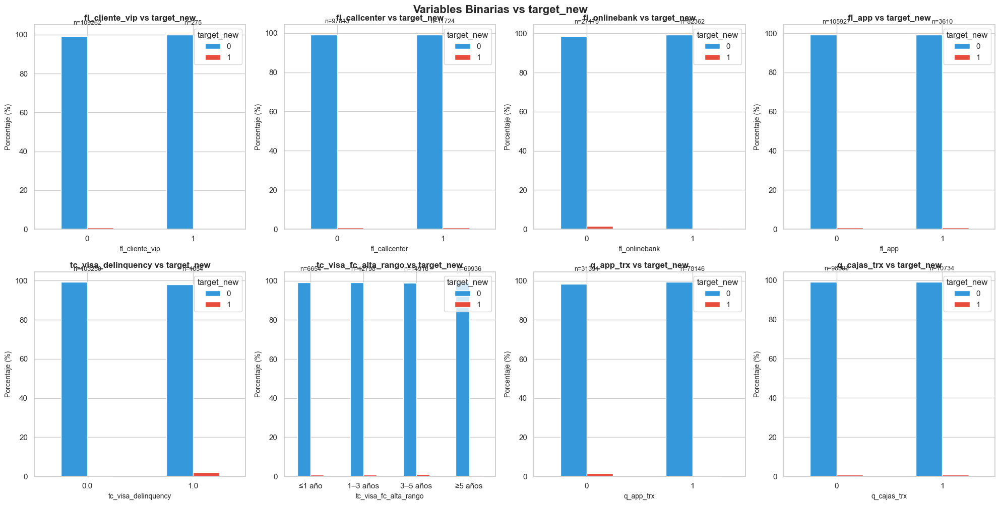

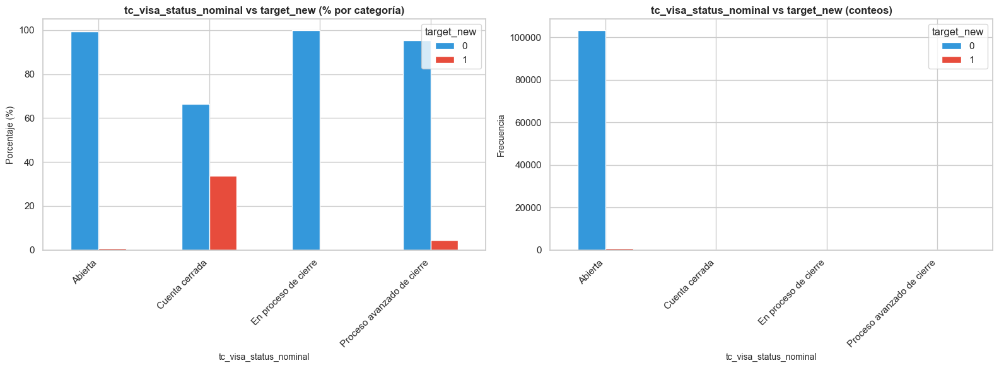

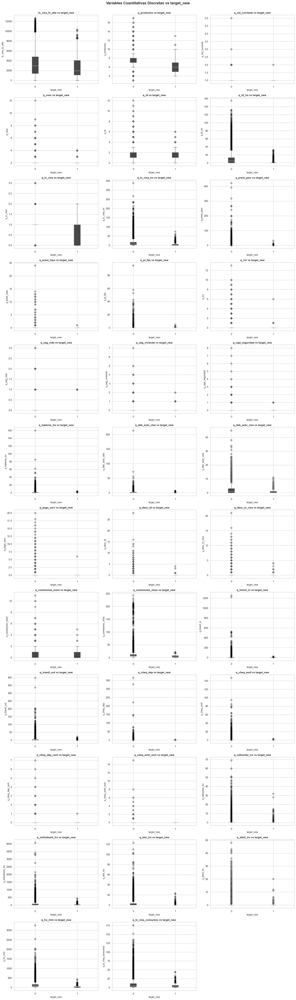

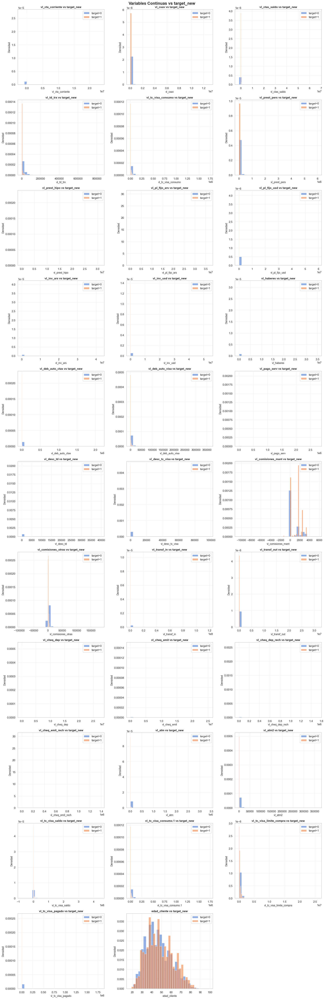


RESUMEN ESTADÍSTICO POR TARGET

--- TARGET = 0 ---
       vl_cta_corriente       vl_csav  vl_ctas_saldo      vl_td_trx  vl_tc_visa_consumo  vl_prest_pers  vl_prest_hipo  vl_pl_fijo_ars  vl_pl_fijo_usd    vl_inv_ars  ...     q_cheq_dep    q_cheq_emit  q_cheq_dep_rech  q_cheq_emit_rech  q_callcenter_trx  q_onlinebank_trx      q_atm_trx    q_atm2_trx     q_trx_trim  q_tc_visa_consumos
count      1.086470e+05  1.086470e+05   1.086470e+05  108647.000000        1.086470e+05   1.086470e+05   1.086470e+05    1.086470e+05    1.086470e+05  1.086470e+05  ...  108647.000000  108647.000000    108647.000000     108647.000000     108647.000000     108647.000000  108647.000000  108647.00000  108647.000000        94885.000000
mean       2.893379e+03  7.897438e+04   2.099333e+05   20280.002987        3.126632e+04   3.198423e+04   2.426426e+04    6.343384e+03    1.016436e+05  1.934750e+04  ...       0.121246       0.120997         0.002504          0.002283          0.439092         57.971467       1.96

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración de estilo
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (15, 6)

# ============================================
# 1. VARIABLES BINARIAS
# ============================================
variables_binarias = [
    'fl_cliente_vip', 'fl_callcenter', 'fl_onlinebank', 'fl_app',
    'tc_visa_delinquency', 'tc_visa_fc_alta_rango', 'q_app_trx', 'q_cajas_trx'
]

# Filtrar solo las que existen en el dataset
vars_bin_existentes = [v for v in variables_binarias if v in df_train1.columns]

n_vars_bin = len(vars_bin_existentes)
n_cols = 4
n_rows = int(np.ceil(n_vars_bin / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5*n_rows))
axes = axes.flatten() if n_vars_bin > 1 else [axes]

for idx, var in enumerate(vars_bin_existentes):
    ax = axes[idx]
    
    # Calcular proporciones de target_new por cada valor de la variable binaria
    crosstab = pd.crosstab(df_train1[var], df_train1['target_new'], normalize='index') * 100
    
    crosstab.plot(kind='bar', ax=ax, color=['#3498db', '#e74c3c'])
    ax.set_title(f'{var} vs target_new', fontsize=12, fontweight='bold')
    ax.set_xlabel(var, fontsize=10)
    ax.set_ylabel('Porcentaje (%)', fontsize=10)
    ax.legend(title='target_new', loc='upper right')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    
    # Añadir conteos totales
    for i, (idx_val, row) in enumerate(crosstab.iterrows()):
        total = df_train1[df_train1[var] == idx_val].shape[0]
        ax.text(i, 105, f'n={total}', ha='center', fontsize=9)

# Ocultar ejes vacíos
for idx in range(n_vars_bin, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.suptitle('Variables Binarias vs target_new', fontsize=16, fontweight='bold', y=1.001)
plt.show()

# ============================================
# 2. VARIABLE CUALITATIVA NOMINAL
# ============================================
if 'tc_visa_status_nominal' in df_train1.columns:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Gráfico 1: Barras apiladas con porcentajes
    crosstab = pd.crosstab(df_train1['tc_visa_status_nominal'], df_train1['target_new'], normalize='index') * 100
    crosstab.plot(kind='bar', stacked=False, ax=axes[0], color=['#3498db', '#e74c3c'])
    axes[0].set_title('tc_visa_status_nominal vs target_new (% por categoría)', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('tc_visa_status_nominal', fontsize=10)
    axes[0].set_ylabel('Porcentaje (%)', fontsize=10)
    axes[0].legend(title='target_new')
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
    
    # Gráfico 2: Conteo absoluto
    crosstab_abs = pd.crosstab(df_train1['tc_visa_status_nominal'], df_train1['target_new'])
    crosstab_abs.plot(kind='bar', ax=axes[1], color=['#3498db', '#e74c3c'])
    axes[1].set_title('tc_visa_status_nominal vs target_new (conteos)', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('tc_visa_status_nominal', fontsize=10)
    axes[1].set_ylabel('Frecuencia', fontsize=10)
    axes[1].legend(title='target_new')
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    plt.show()

# ============================================
# 3. VARIABLES CUANTITATIVAS DISCRETAS
# ============================================
# tc_visa_fc_alta + todas las q_ excepto q_app_trx y q_cajas_trx
vars_discretas = ['tc_visa_fc_alta']
vars_discretas += [col for col in df_train1.columns if col.startswith('q_') and col not in ['q_app_trx', 'q_cajas_trx']]

# Filtrar las que existen
vars_disc_existentes = [v for v in vars_discretas if v in df_train1.columns]

n_vars_disc = len(vars_disc_existentes)
n_cols = 3
n_rows = int(np.ceil(n_vars_disc / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5*n_rows))
axes = axes.flatten() if n_vars_disc > 1 else [axes]

for idx, var in enumerate(vars_disc_existentes):
    ax = axes[idx]
    
    # Boxplot por categoría de target
    df_train1.boxplot(column=var, by='target_new', ax=ax, patch_artist=True)
    ax.set_title(f'{var} vs target_new', fontsize=11, fontweight='bold')
    ax.set_xlabel('target_new', fontsize=10)
    ax.set_ylabel(var, fontsize=10)
    plt.sca(ax)
    plt.xticks([1, 2], ['0', '1'])

# Ocultar ejes vacíos
for idx in range(n_vars_disc, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.suptitle('Variables Cuantitativas Discretas vs target_new', fontsize=16, fontweight='bold', y=1.001)
plt.show()

# ============================================
# 4. VARIABLES CONTINUAS
# ============================================
# Todo lo que empiece con vl_, más edad_cliente y antigüedad_cliente
vars_continuas = [col for col in df_train1.columns if col.startswith('vl_')]
vars_continuas += ['edad_cliente', 'antigüedad_cliente']

# Filtrar las que existen
vars_cont_existentes = [v for v in vars_continuas if v in df_train1.columns]

n_vars_cont = len(vars_cont_existentes)
n_cols = 3
n_rows = int(np.ceil(n_vars_cont / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5*n_rows))
axes = axes.flatten() if n_vars_cont > 1 else [axes]

for idx, var in enumerate(vars_cont_existentes):
    ax = axes[idx]
    
    # Histogramas superpuestos con densidad
    for target_val in sorted(df_train1['target_new'].unique()):
        data = df_train1[df_train1['target_new'] == target_val][var].dropna()
        ax.hist(data, bins=30, alpha=0.6, label=f'target={target_val}', density=True)
    
    ax.set_title(f'{var} vs target_new', fontsize=11, fontweight='bold')
    ax.set_xlabel(var, fontsize=10)
    ax.set_ylabel('Densidad', fontsize=10)
    ax.legend()
    ax.grid(True, alpha=0.3)

# Ocultar ejes vacíos
for idx in range(n_vars_cont, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.suptitle('Variables Continuas vs target_new', fontsize=16, fontweight='bold', y=1.001)
plt.show()

# ============================================
# 5. RESUMEN ESTADÍSTICO
# ============================================
print("\n" + "="*80)
print("RESUMEN ESTADÍSTICO POR TARGET")
print("="*80)

for target_val in sorted(df_train1['target_new'].unique()):
    print(f"\n--- TARGET = {target_val} ---")
    print(df_train1[df_train1['target_new'] == target_val][vars_cont_existentes + vars_disc_existentes].describe())

DISTRIBUCIÓN DE TARGET_NEW
Clase 0: 108,647 (99.19%)
Clase 1: 890 (0.81%)
Ratio desbalanceo: 122.1:1



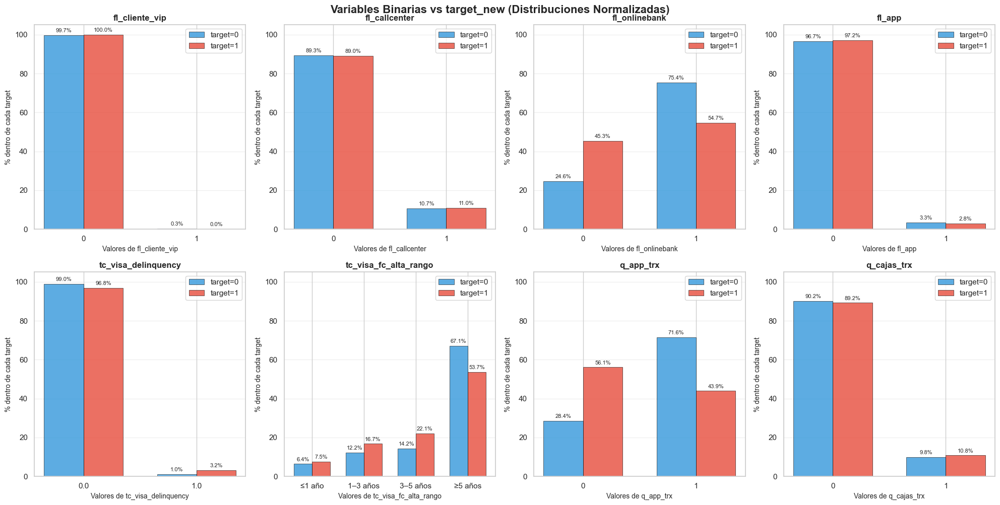

C:\Users\facun\AppData\Local\Temp\ipykernel_21152\1695813808.py:116: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tasa_target = df_train1.groupby('tc_visa_status_nominal')['target_new'].agg(['sum', 'count'])


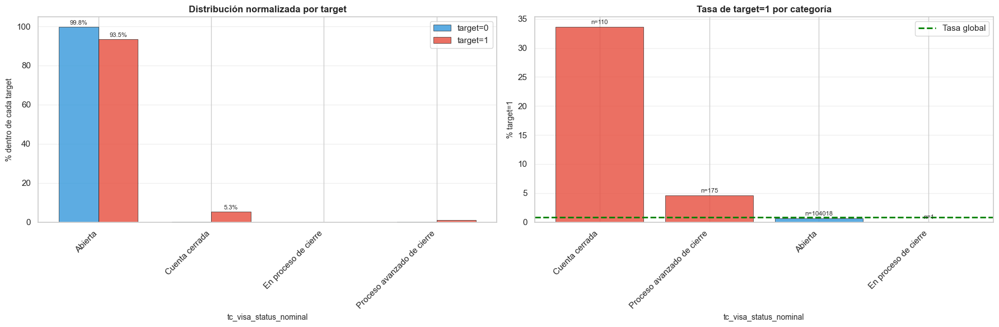

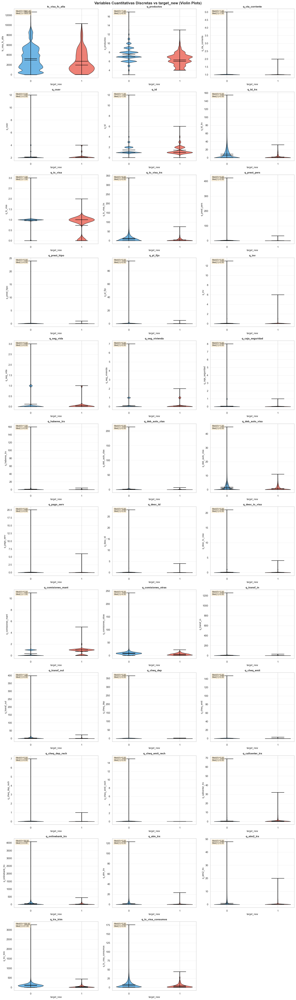

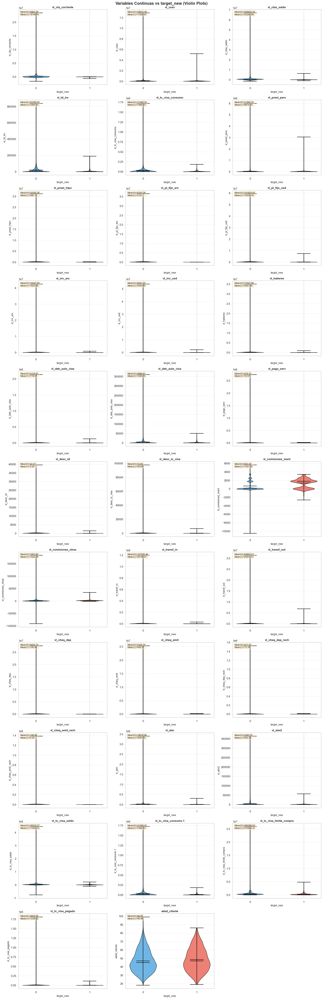


RESUMEN DE DISTRIBUCIONES POR TARGET_NEW (SIN DIFERENCIAS)
                variable    n_0  n_1      mean_0      mean_1    median_0    median_1       std_0       std_1
            edad_cliente 108647  890      46.854      48.457      45.000      47.000      12.940      13.598
              q_atm2_trx 108647  890       0.821       0.173       0.000       0.000       2.152       1.054
               q_atm_trx 108647  890       1.960       0.420       0.000       0.000       3.839       1.816
        q_caja_seguridad 108647  890       0.071       0.013       0.000       0.000       0.273       0.115
        q_callcenter_trx 108647  890       0.439       0.472       0.000       0.000       1.926       2.165
              q_cheq_dep 108647  890       0.121       0.007       0.000       0.000       2.039       0.116
         q_cheq_dep_rech 108647  890       0.003       0.001       0.000       0.000       0.066       0.034
             q_cheq_emit 108647  890       0.121       0.011       0

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración de estilo
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (15, 6)

# Información sobre el desbalanceo
print("="*80)
print("DISTRIBUCIÓN DE TARGET_NEW")
print("="*80)
target_counts = df_train1['target_new'].value_counts()
target_props = df_train1['target_new'].value_counts(normalize=True) * 100
print(f"Clase 0: {target_counts[0]:,} ({target_props[0]:.2f}%)")
print(f"Clase 1: {target_counts[1]:,} ({target_props[1]:.2f}%)")
print(f"Ratio desbalanceo: {target_counts[0]/target_counts[1]:.1f}:1\n")

# ============================================
# 1. VARIABLES BINARIAS
# ============================================
variables_binarias = [
    'fl_cliente_vip', 'fl_callcenter', 'fl_onlinebank', 'fl_app',
    'tc_visa_delinquency', 'tc_visa_fc_alta_rango', 'q_app_trx', 'q_cajas_trx'
]

vars_bin_existentes = [v for v in variables_binarias if v in df_train1.columns]

n_vars_bin = len(vars_bin_existentes)
n_cols = 4
n_rows = int(np.ceil(n_vars_bin / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5*n_rows))
axes = axes.flatten() if n_vars_bin > 1 else [axes]

for idx, var in enumerate(vars_bin_existentes):
    ax = axes[idx]
    
    # Calcular proporciones NORMALIZADAS (cada target suma 100%)
    # Esto muestra la DISTRIBUCIÓN DENTRO de cada clase de target
    crosstab = pd.crosstab(df_train1['target_new'], df_train1[var], normalize='index') * 100
    
    # Transponer para que las barras sean las categorías de la variable
    crosstab_t = crosstab.T
    
    # Gráfico de barras agrupadas
    x = np.arange(len(crosstab_t.index))
    width = 0.35
    
    bars1 = ax.bar(x - width/2, crosstab_t[0], width, label='target=0', 
                   color='#3498db', alpha=0.8, edgecolor='black', linewidth=0.5)
    bars2 = ax.bar(x + width/2, crosstab_t[1], width, label='target=1', 
                   color='#e74c3c', alpha=0.8, edgecolor='black', linewidth=0.5)
    
    ax.set_title(f'{var}', fontsize=12, fontweight='bold')
    ax.set_xlabel(f'Valores de {var}', fontsize=10)
    ax.set_ylabel('% dentro de cada target', fontsize=10)
    ax.set_xticks(x)
    ax.set_xticklabels(crosstab_t.index)
    ax.legend(loc='upper right')
    ax.set_ylim(0, 105)
    ax.grid(axis='y', alpha=0.3)
    
    # Añadir valores en las barras
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 1,
                   f'{height:.1f}%', ha='center', va='bottom', fontsize=8)

for idx in range(n_vars_bin, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.suptitle('Variables Binarias vs target_new (Distribuciones Normalizadas)', 
             fontsize=16, fontweight='bold', y=1.001)
plt.show()

# ============================================
# 2. VARIABLE CUALITATIVA NOMINAL
# ============================================
if 'tc_visa_status_nominal' in df_train1.columns:
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    
    # Gráfico 1: Distribuciones normalizadas por target
    crosstab = pd.crosstab(df_train1['target_new'], df_train1['tc_visa_status_nominal'], 
                           normalize='index') * 100
    crosstab_t = crosstab.T
    
    x = np.arange(len(crosstab_t.index))
    width = 0.35
    
    bars1 = axes[0].bar(x - width/2, crosstab_t[0], width, label='target=0', 
                        color='#3498db', alpha=0.8, edgecolor='black', linewidth=0.5)
    bars2 = axes[0].bar(x + width/2, crosstab_t[1], width, label='target=1', 
                        color='#e74c3c', alpha=0.8, edgecolor='black', linewidth=0.5)
    
    axes[0].set_title('Distribución normalizada por target', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('tc_visa_status_nominal', fontsize=10)
    axes[0].set_ylabel('% dentro de cada target', fontsize=10)
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(crosstab_t.index, rotation=45, ha='right')
    axes[0].legend()
    axes[0].grid(axis='y', alpha=0.3)
    
    # Añadir valores en las barras
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            if height > 2:  # Solo mostrar si es mayor a 2%
                axes[0].text(bar.get_x() + bar.get_width()/2., height + 0.5,
                           f'{height:.1f}%', ha='center', va='bottom', fontsize=8)
    
    # Gráfico 2: Tasa de target=1 por categoría
    tasa_target = df_train1.groupby('tc_visa_status_nominal')['target_new'].agg(['sum', 'count'])
    tasa_target['tasa'] = (tasa_target['sum'] / tasa_target['count']) * 100
    tasa_target = tasa_target.sort_values('tasa', ascending=False)
    
    colors = ['#e74c3c' if x > df_train1['target_new'].mean()*100 else '#3498db' 
              for x in tasa_target['tasa']]
    
    axes[1].bar(range(len(tasa_target)), tasa_target['tasa'], color=colors, 
                alpha=0.8, edgecolor='black', linewidth=0.5)
    axes[1].axhline(y=df_train1['target_new'].mean()*100, color='green', 
                    linestyle='--', linewidth=2, label='Tasa global')
    axes[1].set_title('Tasa de target=1 por categoría', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('tc_visa_status_nominal', fontsize=10)
    axes[1].set_ylabel('% target=1', fontsize=10)
    axes[1].set_xticks(range(len(tasa_target)))
    axes[1].set_xticklabels(tasa_target.index, rotation=45, ha='right')
    axes[1].legend()
    axes[1].grid(axis='y', alpha=0.3)
    
    # Añadir conteos
    for i, (idx_val, row) in enumerate(tasa_target.iterrows()):
        axes[1].text(i, row['tasa'] + 0.5, f"n={int(row['count'])}", 
                    ha='center', fontsize=8)
    
    plt.tight_layout()
    plt.show()

# ============================================
# 3. VARIABLES CUANTITATIVAS DISCRETAS
# ============================================
vars_discretas = ['tc_visa_fc_alta']
vars_discretas += [col for col in df_train1.columns if col.startswith('q_') 
                   and col not in ['q_app_trx', 'q_cajas_trx']]

vars_disc_existentes = [v for v in vars_discretas if v in df_train1.columns]

n_vars_disc = len(vars_disc_existentes)
n_cols = 3
n_rows = int(np.ceil(n_vars_disc / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5*n_rows))
axes = axes.flatten() if n_vars_disc > 1 else [axes]

for idx, var in enumerate(vars_disc_existentes):
    ax = axes[idx]
    
    # Violin plot para comparar distribuciones
    parts = ax.violinplot([df_train1[df_train1['target_new']==0][var].dropna(),
                           df_train1[df_train1['target_new']==1][var].dropna()],
                          positions=[0, 1], showmeans=True, showmedians=True)
    
    # Colorear los violines
    colors = ['#3498db', '#e74c3c']
    for pc, color in zip(parts['bodies'], colors):
        pc.set_facecolor(color)
        pc.set_alpha(0.7)
        pc.set_edgecolor('black')
        pc.set_linewidth(1.5)
    
    # Colorear otros elementos
    for partname in ('cbars', 'cmins', 'cmaxes', 'cmedians', 'cmeans'):
        if partname in parts:
            vp = parts[partname]
            vp.set_edgecolor('black')
            vp.set_linewidth(1.5)
    
    ax.set_title(f'{var}', fontsize=11, fontweight='bold')
    ax.set_xlabel('target_new', fontsize=10)
    ax.set_ylabel(var, fontsize=10)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['0', '1'])
    ax.grid(axis='y', alpha=0.3)
    
    # Añadir estadísticas
    median_0 = df_train1[df_train1['target_new']==0][var].median()
    median_1 = df_train1[df_train1['target_new']==1][var].median()
    ax.text(0.02, 0.98, f'Med(0)={median_0:.2f}\nMed(1)={median_1:.2f}', 
            transform=ax.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

for idx in range(n_vars_disc, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.suptitle('Variables Cuantitativas Discretas vs target_new (Violin Plots)', 
             fontsize=16, fontweight='bold', y=1.001)
plt.show()

# ============================================
# 4. VARIABLES CONTINUAS
# ============================================
vars_continuas = [col for col in df_train1.columns if col.startswith('vl_')]
vars_continuas += ['edad_cliente', 'antigüedad_cliente']

vars_cont_existentes = [v for v in vars_continuas if v in df_train1.columns]

n_vars_cont = len(vars_cont_existentes)
n_cols = 3
n_rows = int(np.ceil(n_vars_cont / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5*n_rows))
axes = axes.flatten() if n_vars_cont > 1 else [axes]

for idx, var in enumerate(vars_cont_existentes):
    ax = axes[idx]
    
    # Violin plot para variables continuas
    parts = ax.violinplot([df_train1[df_train1['target_new']==0][var].dropna(),
                           df_train1[df_train1['target_new']==1][var].dropna()],
                          positions=[0, 1], showmeans=True, showmedians=True)
    
    # Colorear los violines
    colors = ['#3498db', '#e74c3c']
    for pc, color in zip(parts['bodies'], colors):
        pc.set_facecolor(color)
        pc.set_alpha(0.7)
        pc.set_edgecolor('black')
        pc.set_linewidth(1.5)
    
    # Colorear otros elementos
    for partname in ('cbars', 'cmins', 'cmaxes', 'cmedians', 'cmeans'):
        if partname in parts:
            vp = parts[partname]
            vp.set_edgecolor('black')
            vp.set_linewidth(1.5)
    
    ax.set_title(f'{var}', fontsize=11, fontweight='bold')
    ax.set_xlabel('target_new', fontsize=10)
    ax.set_ylabel(var, fontsize=10)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['0', '1'])
    ax.grid(axis='y', alpha=0.3)
    
    # Añadir estadísticas
    mean_0 = df_train1[df_train1['target_new']==0][var].mean()
    mean_1 = df_train1[df_train1['target_new']==1][var].mean()
    ax.text(0.02, 0.98, f'Mean(0)={mean_0:.2f}\nMean(1)={mean_1:.2f}', 
            transform=ax.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

for idx in range(n_vars_cont, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.suptitle('Variables Continuas vs target_new (Violin Plots)', 
             fontsize=16, fontweight='bold', y=1.001)
plt.show()

# ============================================
# 5. RESUMEN COMPARATIVO (SIN DIFERENCIAS)
# ============================================
print("\n" + "="*80)
print("RESUMEN DE DISTRIBUCIONES POR TARGET_NEW (SIN DIFERENCIAS)")
print("="*80)

resumen = []
vars_analisis = list(dict.fromkeys(vars_cont_existentes + vars_disc_existentes))  # sin duplicados

for var in vars_analisis:
    serie_0 = df_train1.loc[df_train1['target_new'] == 0, var].dropna()
    serie_1 = df_train1.loc[df_train1['target_new'] == 1, var].dropna()
    
    stats = {
        'variable': var,
        'n_0': len(serie_0),
        'n_1': len(serie_1),
        'mean_0': serie_0.mean(),
        'mean_1': serie_1.mean(),
        'median_0': serie_0.median(),
        'median_1': serie_1.median(),
        'std_0': serie_0.std(),
        'std_1': serie_1.std(),
    }
    resumen.append(stats)

df_resumen = pd.DataFrame(resumen)

# Orden alfabético por variable (podés cambiar el criterio si querés)
df_resumen = df_resumen.sort_values('variable')

# Mostrar con menos decimales
pd.options.display.float_format = '{:,.3f}'.format

print(df_resumen.to_string(index=False))


In [32]:
df_train1.columns.tolist()

['id',
 'anio_mes',
 'fl_cliente_vip',
 'edad_cliente',
 'antiguedad_cliente',
 'q_productos',
 'q_cta_corriente',
 'vl_cta_corriente',
 'q_csav',
 'vl_csav',
 'vl_ctas_saldo',
 'q_td',
 'q_td_trx',
 'vl_td_trx',
 'q_tc_visa',
 'q_tc_visa_trx',
 'vl_tc_visa_consumo',
 'q_prest_pers',
 'vl_prest_pers',
 'q_prest_hipo',
 'vl_prest_hipo',
 'q_pl_fijo',
 'vl_pl_fijo_ars',
 'vl_pl_fijo_usd',
 'q_inv',
 'vl_inv_ars',
 'vl_inv_usd',
 'q_seg_vida',
 'q_seg_vivienda',
 'q_caja_seguridad',
 'q_haberes_trx',
 'vl_haberes',
 'q_deb_auto_ctas',
 'vl_deb_auto_ctas',
 'q_deb_auto_visa',
 'vl_deb_auto_visa',
 'q_pago_serv',
 'vl_pago_serv',
 'q_desc_td',
 'vl_desc_td',
 'q_desc_tc_visa',
 'vl_desc_tc_visa',
 'q_comisiones_mant',
 'vl_comisiones_mant',
 'q_comisiones_otras',
 'vl_comisiones_otras',
 'q_transf_in',
 'vl_transf_in',
 'q_transf_out',
 'vl_transf_out',
 'q_cheq_dep',
 'vl_cheq_dep',
 'q_cheq_emit',
 'vl_cheq_emit',
 'q_cheq_dep_rech',
 'vl_cheq_dep_rech',
 'q_cheq_emit_rech',
 'vl_cheq_emi

#### Matriz de correlaciones

##### Correlación de Pearson

Número de variables numéricas incluidas en la correlación: 77

Matriz de correlaciones (fragmento):
                    fl_cliente_vip  edad_cliente  antiguedad_cliente  q_productos  q_cta_corriente  vl_cta_corriente  q_csav  vl_csav  vl_ctas_saldo  q_td  ...  q_app_trx  tc_visa_delinquency  tc_visa_status  vl_tc_visa_saldo  vl_tc_visa_consumo.1  vl_tc_visa_limite_compra  vl_tc_visa_pagado  tc_visa_fc_alta  q_tc_visa_consumos  target_new
fl_cliente_vip               1.000         0.060               0.050        0.080            0.320             0.020   0.120    0.060          0.310 0.030  ...     -0.010               -0.000          -0.000             0.030                 0.060                     0.120              0.010            0.050               0.050      -0.000
edad_cliente                 0.060         1.000               0.450        0.120            0.060             0.030   0.120    0.080          0.070 0.190  ...     -0.270               -0.020          -0.010         

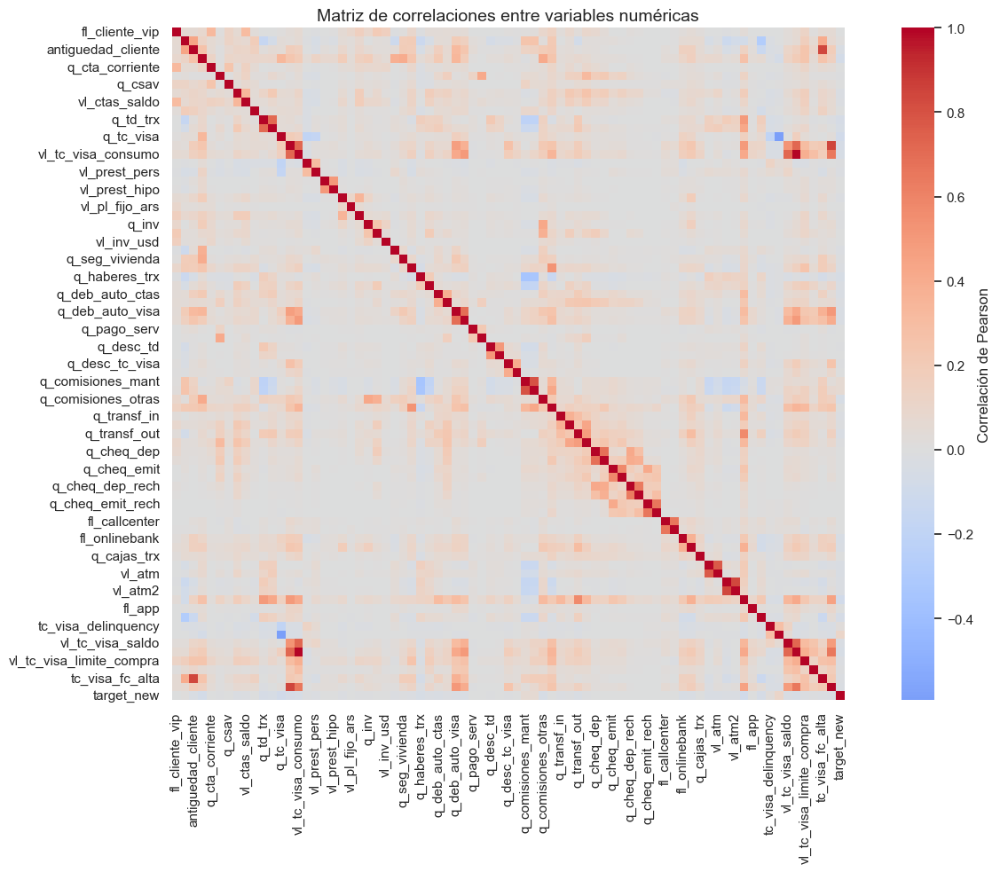

In [33]:
# --- Copia base de trabajo ---
df_corr = df_train1.copy()

# --- Excluir columnas que no deben entrar ---
cols_excluir = ['id', 'anio_mes','flag_baja', 'anio_mes_orig', 'tc_visa_status_nominal','tc_visa_fc_alta_rango','antiguedad_anios','antiguedad_rango','edad_rango',"target"]
df_corr = df_corr.drop(columns=[c for c in cols_excluir if c in df_corr.columns], errors='ignore')

# --- Quedarse sólo con columnas numéricas ---
df_corr = df_corr.select_dtypes(include=[np.number])

print(f"Número de variables numéricas incluidas en la correlación: {df_corr.shape[1]}")

# --- Calcular matriz de correlaciones (Pearson por defecto) ---
corr_matrix = df_corr.corr(method='pearson')

# --- Mostrar primeras filas ---
print("\nMatriz de correlaciones (fragmento):")
print(corr_matrix.round(2).head())

# --- Graficar mapa de calor ---
plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    annot=False,        # ponelo en True si querés ver los números
    fmt=".2f",
    square=True,
    cbar_kws={'label': 'Correlación de Pearson'}
)
plt.title("Matriz de correlaciones entre variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()


In [34]:
# --- Pasar a formato largo (pares de variables) ---
corr_long = (
    corr_matrix.unstack()
    .reset_index()
    .rename(columns={'level_0': 'var1', 'level_1': 'var2', 0: 'corr'})
)

# --- Quitar duplicados y auto-correlaciones ---
corr_long = corr_long[corr_long['var1'] < corr_long['var2']]

# --- Ordenar por valor absoluto de la correlación ---
corr_long['abs_corr'] = corr_long['corr'].abs()
top20 = corr_long.sort_values('abs_corr', ascending=False).head(20)

# --- Mostrar resultados ---
print("🔝 Top 20 correlaciones de Pearson más fuertes (positivas o negativas):")
print(top20[['var1', 'var2', 'corr']].to_string(index=False, justify='left'))

🔝 Top 20 correlaciones de Pearson más fuertes (positivas o negativas):
var1                 var2                  corr 
  vl_tc_visa_consumo vl_tc_visa_consumo.1  1.000
  q_tc_visa_consumos        q_tc_visa_trx  0.847
  antiguedad_cliente      tc_visa_fc_alta  0.837
          q_atm2_trx              vl_atm2  0.835
   q_comisiones_mant   vl_comisiones_mant  0.797
           q_atm_trx               vl_atm  0.767
vl_tc_visa_consumo.1     vl_tc_visa_saldo  0.723
  vl_tc_visa_consumo     vl_tc_visa_saldo  0.723
       q_tc_visa_trx vl_tc_visa_consumo.1  0.722
       q_tc_visa_trx   vl_tc_visa_consumo  0.722
            q_td_trx            vl_td_trx  0.712
     q_deb_auto_visa     vl_deb_auto_visa  0.692
          q_cheq_dep          vl_cheq_dep  0.681
    q_cheq_emit_rech    vl_cheq_emit_rech  0.658
       fl_callcenter     q_callcenter_trx  0.658
  q_tc_visa_consumos vl_tc_visa_consumo.1  0.656
  q_tc_visa_consumos   vl_tc_visa_consumo  0.656
     q_cheq_dep_rech     vl_cheq_dep_rech  0.63

Comentarios:
- Quitaría vl_tc_visa_consumo.1 del análsis porque se correlacionan perfectamente positivas en forma lineal
- Ya que las variables relacionadas con las cantidades y los montos están correlacionadas quizás se puedan armar features (ratio, variaciones, etc)

In [35]:
# --- Calcular correlaciones con target_new ---
corr_target = df_corr.corrwith(df_corr['target_new']).dropna().sort_values(key=abs, ascending=False)

# --- Crear DataFrame ordenado ---
corr_target_df = corr_target.reset_index()
corr_target_df.columns = ['variable', 'corr_target_new']

# --- Mostrar Top 20 ---
top20_target = corr_target_df.head(20)
print("🔝 Top 20 variables más correlacionadas con target_new:")
print(top20_target.to_string(index=False, justify='left'))

🔝 Top 20 variables más correlacionadas con target_new:
variable              corr_target_new
          target_new  1.000          
      tc_visa_status  0.108          
           q_tc_visa -0.088          
          q_trx_trim -0.084          
         q_productos -0.075          
   q_comisiones_mant  0.064          
  vl_comisiones_mant  0.057          
            q_td_trx -0.056          
           q_app_trx -0.055          
       q_tc_visa_trx -0.053          
       q_haberes_trx -0.052          
  q_comisiones_otras -0.049          
           vl_td_trx -0.049          
vl_tc_visa_consumo.1 -0.046          
  vl_tc_visa_consumo -0.046          
       fl_onlinebank -0.043          
        q_transf_out -0.039          
     q_deb_auto_ctas -0.038          
     q_deb_auto_visa -0.037          
    q_onlinebank_trx -0.037          


Comentarios:
- Las correlciones lineales de las posibles variables predictivas con la target son muy bajas, casi nulas

##### Correlación de Spearman


Matriz de correlaciones (fragmento):
                    fl_cliente_vip  edad_cliente  antiguedad_cliente  q_productos  q_cta_corriente  vl_cta_corriente  q_csav  vl_csav  vl_ctas_saldo  q_td  ...  q_app_trx  tc_visa_delinquency  tc_visa_status  vl_tc_visa_saldo  vl_tc_visa_consumo.1  vl_tc_visa_limite_compra  vl_tc_visa_pagado  tc_visa_fc_alta  q_tc_visa_consumos  target_new
fl_cliente_vip               1.000         0.050               0.040        0.060            0.320             0.020   0.090    0.040          0.050 0.030  ...     -0.010               -0.000          -0.000             0.020                 0.030                     0.060              0.000            0.040               0.030      -0.000
edad_cliente                 0.050         1.000               0.420        0.140            0.050             0.140   0.100    0.100          0.090 0.170  ...     -0.260               -0.020          -0.010             0.020                 0.030                     0.200     

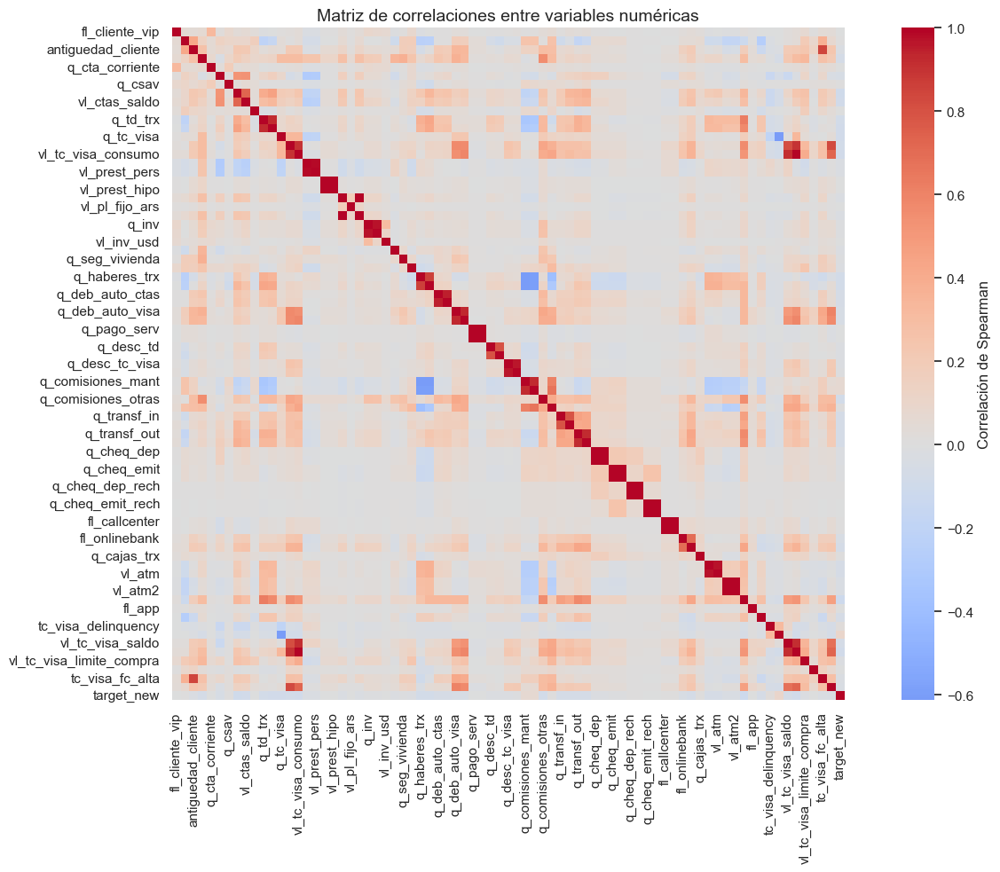

In [36]:
df_corr = df_train1.copy()

# --- Excluir columnas que no deben entrar ---
cols_excluir = ['id', 'anio_mes','flag_baja', 'anio_mes_orig', 'tc_visa_status_nominal','tc_visa_fc_alta_rango','antiguedad_anios','antiguedad_rango','edad_rango',"target"]
df_corr = df_corr.drop(columns=[c for c in cols_excluir if c in df_corr.columns], errors='ignore')

# --- Quedarse sólo con columnas numéricas ---
df_corr = df_corr.select_dtypes(include=[np.number])

corr_matrix = df_corr.corr(method='spearman')  # o 'kendall'
# --- Mostrar primeras filas ---
print("\nMatriz de correlaciones (fragmento):")
print(corr_matrix.round(2).head())

# --- Graficar mapa de calor ---
plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    annot=False,        # ponelo en True si querés ver los números
    fmt=".2f",
    square=True,
    cbar_kws={'label': 'Correlación de Spearman'}
)
plt.title("Matriz de correlaciones entre variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()

In [37]:
# --- Pasar a formato largo (pares de variables) ---
corr_long = (
    corr_matrix.unstack()
    .reset_index()
    .rename(columns={'level_0': 'var1', 'level_1': 'var2', 0: 'corr'})
)

# --- Quitar duplicados y auto-correlaciones ---
corr_long = corr_long[corr_long['var1'] < corr_long['var2']]

# --- Ordenar por valor absoluto de la correlación ---
corr_long['abs_corr'] = corr_long['corr'].abs()
top20 = corr_long.sort_values('abs_corr', ascending=False).head(20)

# --- Mostrar resultados ---
print("🔝 Top 20 correlaciones de Spearman más fuertes (positivas o negativas):")
print(top20[['var1', 'var2', 'corr']].to_string(index=False, justify='left'))

🔝 Top 20 correlaciones de Spearman más fuertes (positivas o negativas):
var1               var2                  corr
vl_tc_visa_consumo vl_tc_visa_consumo.1 1.000
  q_cheq_emit_rech    vl_cheq_emit_rech 1.000
   q_cheq_dep_rech     vl_cheq_dep_rech 1.000
      q_prest_hipo        vl_prest_hipo 1.000
       q_pago_serv         vl_pago_serv 1.000
       q_cheq_emit         vl_cheq_emit 1.000
        q_cheq_dep          vl_cheq_dep 1.000
     fl_callcenter     q_callcenter_trx 0.998
        q_atm2_trx              vl_atm2 0.993
         q_pl_fijo       vl_pl_fijo_usd 0.991
      q_prest_pers        vl_prest_pers 0.987
         q_atm_trx               vl_atm 0.973
             q_inv           vl_inv_ars 0.969
    q_desc_tc_visa      vl_desc_tc_visa 0.960
   q_deb_auto_ctas     vl_deb_auto_ctas 0.948
   q_deb_auto_visa     vl_deb_auto_visa 0.935
          q_td_trx            vl_td_trx 0.924
 q_comisiones_mant   vl_comisiones_mant 0.920
      q_transf_out        vl_transf_out 0.919
vl_tc_vi

In [38]:
# --- Calcular correlaciones con target_new ---
corr_target = df_corr.corrwith(df_corr['target_new']).dropna().sort_values(key=abs, ascending=False)

# --- Crear DataFrame ordenado ---
corr_target_df = corr_target.reset_index()
corr_target_df.columns = ['variable', 'corr_target_new']

# --- Mostrar Top 20 ---
top20_target = corr_target_df.head(20)
print("🔝 Top 20 variables más correlacionadas con target_new:")
print(top20_target.to_string(index=False, justify='left'))

🔝 Top 20 variables más correlacionadas con target_new:
variable              corr_target_new
          target_new  1.000          
      tc_visa_status  0.108          
           q_tc_visa -0.088          
          q_trx_trim -0.084          
         q_productos -0.075          
   q_comisiones_mant  0.064          
  vl_comisiones_mant  0.057          
            q_td_trx -0.056          
           q_app_trx -0.055          
       q_tc_visa_trx -0.053          
       q_haberes_trx -0.052          
  q_comisiones_otras -0.049          
           vl_td_trx -0.049          
vl_tc_visa_consumo.1 -0.046          
  vl_tc_visa_consumo -0.046          
       fl_onlinebank -0.043          
        q_transf_out -0.039          
     q_deb_auto_ctas -0.038          
     q_deb_auto_visa -0.037          
    q_onlinebank_trx -0.037          


### Base validación

In [39]:
print(df_valid1['target'].value_counts().sort_index())

target
0    108695
1       478
2       649
Name: count, dtype: Int64


In [40]:
# Me quedo con los que sean target=0 (continua) y target=2 (baja+2)
df_valid1 = df_valid1[df_valid1['target'].isin([0, 2])].copy()

#transformo el target=2 en target=1
df_valid1.loc[df_valid1['target'] == 2, 'target'] = 1

print(df_valid1['target'].value_counts().sort_index())

target
0    108695
1       649
Name: count, dtype: Int64


In [41]:
df_valid1['target_new']=df_valid1['target']

### Base testeo

In [42]:
print(df_test1['target'].value_counts().sort_index())

target
0    108766
1       649
2       540
Name: count, dtype: Int64


In [43]:
# Me quedo con los que sean target=0 (continua) y target=2 (baja+2)
df_test1 = df_test1[df_test1['target'].isin([0, 2])].copy()

#transformo el target=2 en target=1
df_test1.loc[df_test1['target'] == 2, 'target'] = 1

print(df_test1['target'].value_counts().sort_index())

target
0    108766
1       540
Name: count, dtype: Int64


In [44]:
df_test1['target_new']=df_test1['target']

# Prueba 1 (baseline): Modelo lightgbm con todas las variables originales

In [45]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report,
    roc_auc_score, accuracy_score, f1_score, precision_score, recall_score, matthews_corrcoef)

# =============================================================================
#  Preparación del dataset: copiar para no modificar los originales
# =============================================================================
df_train = df_train1.copy()
df_valid = df_valid1.copy()


# Definir rango y columnas relevantes
cols_excluir = ['id', 'anio_mes','flag_baja', 'anio_mes_orig', 'tc_visa_status','tc_visa_fc_alta_rango','antiguedad_anios','antiguedad_rango','edad_rango',"target"]
df_train_prueba = df_train.drop(columns=[c for c in cols_excluir if c in df_train.columns], errors='ignore')
df_valid_prueba = df_valid.drop(columns=[c for c in cols_excluir if c in df_valid.columns], errors='ignore')


# =============================================================================
#  Separar features y target
# =============================================================================
X_train = df_train_prueba.drop(columns='target_new')
y_train = df_train_prueba['target_new']

X_valid = df_valid_prueba.drop(columns='target_new')
y_valid = df_valid_prueba['target_new']

# =============================================================================
#  Crear dummies (por si hay categóricas en las primeras 78 columnas)
# =============================================================================
X_train = pd.get_dummies(X_train, drop_first=True)
X_valid = pd.get_dummies(X_valid, drop_first=True)

# Alinear columnas entre train y valid
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)


# =============================================================================
#  Crear datasets LightGBM
# =============================================================================
train_data = lgb.Dataset(X_train, label=y_train)
valid_data = lgb.Dataset(X_valid, label=y_valid, reference=train_data)

# =============================================================================
#  Configurar parámetros LightGBM
# =============================================================================
params = {
    'objective': 'binary',
    'metric': 'auc',
    'learning_rate': 0.1,
    'num_leaves': 31,
    'verbose': -1,
    'seed': 42
}

# =============================================================================
#  Entrenamiento
# =============================================================================
model = lgb.train(
    params,
    train_data,
    num_boost_round=200,
    valid_sets=[valid_data],
    callbacks=[lgb.early_stopping(stopping_rounds=3)]
)

# =============================================================================
#  Predicción y evaluación
# =============================================================================
y_pred_proba = model.predict(X_valid, num_iteration=model.best_iteration)
y_pred_class = (y_pred_proba >= 0.5).astype(int)

auc = roc_auc_score(y_valid, y_pred_proba)
acc = accuracy_score(y_valid, y_pred_class)

# Métricas
print("🔍 Matriz de confusión:")
print(confusion_matrix(y_valid, y_pred_class))

print("\n📋 Reporte de clasificación:")
print(classification_report(y_valid, y_pred_class, digits=3))

print(f"AUC: {roc_auc_score(y_valid, y_pred_proba):.4f}")
print(f"Accuracy: {accuracy_score(y_valid, y_pred_class):.4f}")
print(f"Precision: {precision_score(y_valid, y_pred_class):.4f}")
print(f"Recall: {recall_score(y_valid, y_pred_class):.4f}")
print(f"F1-score: {f1_score(y_valid, y_pred_class):.4f}")
mcc = matthews_corrcoef(y_valid, y_pred_class)
print(f"Matthews Correlation Coefficient (MCC): {mcc:.4f}")


Training until validation scores don't improve for 3 rounds
Early stopping, best iteration is:
[13]	valid_0's auc: 0.90776
🔍 Matriz de confusión:
[[108564    131]
 [   606     43]]

📋 Reporte de clasificación:
              precision    recall  f1-score   support

         0.0      0.994     0.999     0.997    108695
         1.0      0.247     0.066     0.104       649

    accuracy                          0.993    109344
   macro avg      0.621     0.533     0.551    109344
weighted avg      0.990     0.993     0.991    109344

AUC: 0.9078
Accuracy: 0.9933
Precision: 0.2471
Recall: 0.0663
F1-score: 0.1045
Matthews Correlation Coefficient (MCC): 0.1254


Si bien en presento todos los indicadores asociados al umbral 0.5 (por default), la métrica que elegí para evaluar los modelos es el AUC, el cual me dio bastante bien (0.9078) para ser el modelo baseline.

# Prueba 2: Modelo XGBoost con todas las variables

In [46]:
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, classification_report
)

# --- Preparación del dataset ---
df_train = df_train1.copy()
df_valid = df_valid1.copy()

## Mapear tc_visa_status a etiquetas nominales
#status_map = {
#    0: "Abierta",
#    6: "En proceso de cierre",
#    7: "Proceso avanzado de cierre",
#    9: "Cuenta cerrada"
#}
#df_train['tc_visa_status_nominal'] = df_train['tc_visa_status'].map(status_map).astype('category')
#df_valid['tc_visa_status_nominal'] = df_valid['tc_visa_status'].map(status_map).astype('category')

# Eliminar columnas irrelevantes
cols_excluir = ['id', 'anio_mes','flag_baja', 'anio_mes_orig', 'tc_visa_status','tc_visa_fc_alta_rango','antiguedad_anios','antiguedad_rango','edad_rango',"target"]
df_train_prueba = df_train.drop(columns=[c for c in cols_excluir if c in df_train.columns], errors='ignore')
df_valid_prueba = df_valid.drop(columns=[c for c in cols_excluir if c in df_valid.columns], errors='ignore')

# --- Separar features y target ---
X_train = df_train_prueba.drop(columns='target_new')
y_train = df_train_prueba['target_new']
X_valid = df_valid_prueba.drop(columns='target_new')
y_valid = df_valid_prueba['target_new']

# --- Crear dummies para variables categóricas
X_train = pd.get_dummies(X_train, drop_first=True)
X_valid = pd.get_dummies(X_valid, drop_first=True)

# Alinear columnas entre train y valid
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)


# --- Modelo XGBoost ---
model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    min_child_weight=1,
    subsample=1.0,
    colsample_bytree=1.0,
    gamma=0,
    reg_alpha=0,
    reg_lambda=1,
    tree_method='auto',
    enable_categorical=False,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42
)

# --- Entrenamiento ---
model.fit(X_train, y_train)

# --- Predicción ---
y_pred_proba = model.predict_proba(X_valid)[:, 1]
y_pred_class = (y_pred_proba >= 0.5).astype(int)

# --- Evaluación ---
print("🔍 Matriz de confusión:")
print(confusion_matrix(y_valid, y_pred_class))

print("\n📋 Reporte de clasificación:")
print(classification_report(y_valid, y_pred_class, digits=3))

print(f"AUC: {roc_auc_score(y_valid, y_pred_proba):.4f}")
print(f"Accuracy: {accuracy_score(y_valid, y_pred_class):.4f}")
print(f"Precision: {precision_score(y_valid, y_pred_class):.4f}")
print(f"Recall: {recall_score(y_valid, y_pred_class):.4f}")
print(f"F1-score: {f1_score(y_valid, y_pred_class):.4f}")

mcc = matthews_corrcoef(y_valid, y_pred_class)
print(f"Matthews Correlation Coefficient (MCC): {mcc:.4f}")


c:\Users\facun\AppData\Local\Programs\Python\Python310\lib\site-packages\xgboost\training.py:183: UserWarning: [18:34:19] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


🔍 Matriz de confusión:
[[108659     36]
 [   628     21]]

📋 Reporte de clasificación:
              precision    recall  f1-score   support

         0.0      0.994     1.000     0.997    108695
         1.0      0.368     0.032     0.059       649

    accuracy                          0.994    109344
   macro avg      0.681     0.516     0.528    109344
weighted avg      0.991     0.994     0.991    109344

AUC: 0.9150
Accuracy: 0.9939
Precision: 0.3684
Recall: 0.0324
F1-score: 0.0595
Matthews Correlation Coefficient (MCC): 0.1078


Este modelo tiene un AUC de 0.915, apenas un poco mejor que el modelo LightGBM con las mismas variables

# Prueba 3: Lightgbm con incorporación de 'is_unbalance': True

In [47]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score

# --- Preparación del dataset ---
df_train = df_train1.copy()
df_valid = df_valid1.copy()

## Mapear tc_visa_status a etiquetas nominales
#status_map = {
#    0: "Abierta",
#    6: "En proceso de cierre",
#    7: "Proceso avanzado de cierre",
#    9: "Cuenta cerrada"
#}
#
#df_train['tc_visa_status_nominal'] = df_train['tc_visa_status'].map(status_map).astype('category')
#df_valid['tc_visa_status_nominal'] = df_valid['tc_visa_status'].map(status_map).astype('category')

# Eliminar columnas irrelevantes
cols_excluir = ['id', 'anio_mes','flag_baja', 'anio_mes_orig', 'tc_visa_status','tc_visa_fc_alta_rango','antiguedad_anios','antiguedad_rango','edad_rango',"target"]
df_train_prueba = df_train.drop(columns=[c for c in cols_excluir if c in df_train.columns], errors='ignore')
df_valid_prueba = df_valid.drop(columns=[c for c in cols_excluir if c in df_valid.columns], errors='ignore')

# --- Separar features y target ---
X_train = df_train_prueba.drop(columns='target_new')
y_train = df_train_prueba['target_new']

X_valid = df_valid_prueba.drop(columns='target_new')
y_valid = df_valid_prueba['target_new']

# --- Crear dummies para variables categóricas (incluye tc_visa_status_nominal)
X_train = pd.get_dummies(X_train, drop_first=True)
X_valid = pd.get_dummies(X_valid, drop_first=True)

# Alinear columnas entre train y valid
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)


# --- Crear datasets LightGBM ---
train_data = lgb.Dataset(X_train, label=y_train)
valid_data = lgb.Dataset(X_valid, label=y_valid, reference=train_data)

# --- Parámetros para clasificación binaria ---
params = {
    'objective': 'binary',
    'metric': 'auc',
    'is_unbalance': True,
    'learning_rate': 0.1,
    'num_leaves': 31,
    'verbose': -1,
    'seed': 42
}

# --- Entrenamiento ---
model = lgb.train(
    params,
    train_data,
    num_boost_round=200,
    valid_sets=[valid_data],
    callbacks=[lgb.early_stopping(stopping_rounds=3)]
)

# --- Predicción y evaluación ---
y_pred_proba = model.predict(X_valid, num_iteration=model.best_iteration)
y_pred_class = (y_pred_proba >= 0.5).astype(int)

# --- Métricas ---
auc = roc_auc_score(y_valid, y_pred_proba)
acc = accuracy_score(y_valid, y_pred_class)


# Métricas
print("🔍 Matriz de confusión:")
print(confusion_matrix(y_valid, y_pred_class))

print("\n📋 Reporte de clasificación:")
print(classification_report(y_valid, y_pred_class, digits=3))

print(f"AUC: {roc_auc_score(y_valid, y_pred_proba):.4f}")
print(f"Accuracy: {accuracy_score(y_valid, y_pred_class):.4f}")
print(f"Precision: {precision_score(y_valid, y_pred_class):.4f}")
print(f"Recall: {recall_score(y_valid, y_pred_class):.4f}")
print(f"F1-score: {f1_score(y_valid, y_pred_class):.4f}")
mcc = matthews_corrcoef(y_valid, y_pred_class)
print(f"Matthews Correlation Coefficient (MCC): {mcc:.4f}")

Training until validation scores don't improve for 3 rounds
Early stopping, best iteration is:
[1]	valid_0's auc: 0.886176
🔍 Matriz de confusión:
[[83502 25193]
 [   91   558]]

📋 Reporte de clasificación:
              precision    recall  f1-score   support

         0.0      0.999     0.768     0.869    108695
         1.0      0.022     0.860     0.042       649

    accuracy                          0.769    109344
   macro avg      0.510     0.814     0.455    109344
weighted avg      0.993     0.769     0.864    109344

AUC: 0.8862
Accuracy: 0.7688
Precision: 0.0217
Recall: 0.8598
F1-score: 0.0423
Matthews Correlation Coefficient (MCC): 0.1137


El AUC bajó al incorporar 'is_unbalanced=True', pero si comparamos la matriz de confusión con los modelos anteriores (todos con el mismo umbral de 0.5), se observa que aumentó considerablemente el recall de baja+2.

# Creación de variables

## Deflación de las variables que son montos en pesos argentinos tomando el IPC

Fuente: https://www.indec.gob.ar/ftp/cuadros/economia/sh_ipc_10_25.xls

In [48]:
import numpy as np
import pandas as pd

# =============================================================================
# PASO 1: Cargar datos de IPC
# =============================================================================
ipc_data = {
    'anio_mes': [
        '2021-01-31','2021-02-28','2021-03-31','2021-04-30','2021-05-31','2021-06-30',
        '2021-07-31','2021-08-31','2021-09-30','2021-10-31','2021-11-30','2021-12-31'
    ],
    'IPC': [401.5, 415.9, 435.9, 453.7, 468.7, 483.6, 498.1, 510.4, 528.5, 547.1, 560.9, 582.5]
}

df_ipc = pd.DataFrame(ipc_data)
df_ipc['anio_mes'] = pd.to_datetime(df_ipc['anio_mes'])

print("📊 Datos IPC cargados:")
print(df_ipc)

# Mes base: Marzo 2021 (último mes de train)
MES_BASE = pd.to_datetime('2021-03-31')
IPC_BASE = df_ipc.loc[df_ipc['anio_mes'] == MES_BASE, 'IPC'].iloc[0]

print(f"\n🎯 Mes base: {MES_BASE.date()}")
print(f"📈 IPC base: {IPC_BASE}")

# =============================================================================
# PASO 2: Función para mergear IPC con tu dataset
# =============================================================================

def agregar_ipc(df, df_ipc):
    """
    Agrega el IPC al dataframe según anio_mes
    """
    df = df.copy()
    
    # Asegurar que anio_mes sea datetime
    if not np.issubdtype(df['anio_mes'].dtype, np.datetime64):
        df['anio_mes'] = pd.to_datetime(df['anio_mes'])
    
    # Merge con IPC
    df = df.merge(df_ipc, on='anio_mes', how='left')
    
    # Verificar que no haya nulos
    n_na = df['IPC'].isna().sum()
    if n_na > 0:
        print(f"⚠️ WARNING: {n_na} filas sin IPC (revisar anio_mes)")
    
    return df

# =============================================================================
# PASO 3: Ajustar variables monetarias (vl_*) a precios constantes
# =============================================================================

def ajustar_variables_monetarias(df, ipc_base):
    """
    Convierte todas las variables vl_* a precios constantes del mes base.
    
    Fórmula: valor_real = valor_nominal * (IPC_base / IPC_mes)
    """
    df = df.copy()
    
    # Identificar columnas monetarias
    cols_vl = [c for c in df.columns if c.startswith('vl_')]
    
    print(f"💰 Ajustando {len(cols_vl)} variables monetarias a precios constantes...")
    
    # Evitar división por cero o NA en IPC
    if df['IPC'].isna().any():
        print("⚠️ Hay filas con IPC NaN, los *_real quedarán NaN en esas filas.")
    
    factor = ipc_base / df['IPC']
    
    for col in cols_vl:
        col_real = f'{col}_real'
        df[col_real] = df[col] * factor
    
    print(f"✅ Variables ajustadas: {len(cols_vl)}")
    
    # Mostrar ejemplo del impacto
    if len(cols_vl) > 0:
        col_ejemplo = cols_vl[0]
        print(f"\n📊 Ejemplo con {col_ejemplo}:")
        print(df[['anio_mes', col_ejemplo, f'{col_ejemplo}_real', 'IPC']].head())
    
    return df

# =============================================================================
# PASO 4: Análisis del impacto del ajuste
# =============================================================================

def analizar_impacto_ipc(df, col_original):
    """
    Analiza cómo el ajuste por IPC afecta una variable
    """
    col_real = f'{col_original}_real'
    
    if col_real not in df.columns:
        print(f"❌ No existe {col_real}")
        return
    
    print(f"\n{'='*70}")
    print(f"📊 ANÁLISIS DE IMPACTO IPC: {col_original}")
    print(f"{'='*70}")
    
    resumen = df.groupby('anio_mes').agg({
        col_original: 'mean',
        col_real: 'mean',
        'IPC': 'first'
    }).round(2)
    
    resumen['diferencia_%'] = (
        (resumen[col_original] - resumen[col_real]) / resumen[col_real] * 100
    ).round(2)
    
    print(resumen)
    
    print(f"\n💡 Interpretación:")
    print(f"   - En meses con mayor IPC, los valores reales son menores que los nominales")
    print(f"   - Esto captura el efecto de la inflación")
    print(f"   - Las tendencias ahora reflejan cambios reales de comportamiento")

# =============================================================================
# PASO 5: Aplicar TODO sobre df_filtrado y guardar en df_completo
# =============================================================================

# Partimos de df_filtrado
df_completo = df_filtrado.copy()

# 1) Agregar IPC
df_completo = agregar_ipc(df_completo, df_ipc)

# 2) Ajustar variables monetarias
df_completo = ajustar_variables_monetarias(df_completo, IPC_BASE)

print("\n" + "="*70)
print("✅ AJUSTE POR IPC COMPLETADO SOBRE df_filtrado → df_completo")
print("="*70)
print(f"📌 Todas las variables vl_* ahora tienen su versión *_real en df_completo")
print(f"📌 Usa las variables *_real para el feature engineering")
print(f"📌 Mes base: {MES_BASE.date()} (IPC = {IPC_BASE})")
print("="*70)

📊 Datos IPC cargados:
     anio_mes     IPC
0  2021-01-31 401.500
1  2021-02-28 415.900
2  2021-03-31 435.900
3  2021-04-30 453.700
4  2021-05-31 468.700
5  2021-06-30 483.600
6  2021-07-31 498.100
7  2021-08-31 510.400
8  2021-09-30 528.500
9  2021-10-31 547.100
10 2021-11-30 560.900
11 2021-12-31 582.500

🎯 Mes base: 2021-03-31
📈 IPC base: 435.9
💰 Ajustando 31 variables monetarias a precios constantes...
✅ Variables ajustadas: 31

📊 Ejemplo con vl_cta_corriente:
    anio_mes  vl_cta_corriente  vl_cta_corriente_real     IPC
0 2021-01-31             0.000                  0.000 401.500
1 2021-02-28          -434.220               -455.101 415.900
2 2021-03-31             0.000                  0.000 435.900
3 2021-04-30          -902.690               -867.275 453.700
4 2021-05-31             0.000                  0.000 468.700

✅ AJUSTE POR IPC COMPLETADO SOBRE df_filtrado → df_completo
📌 Todas las variables vl_* ahora tienen su versión *_real en df_completo
📌 Usa las variables *_rea

## lags, tendencias, volatilidad, etc.

In [49]:
import numpy as np
import pandas as pd

def crear_features_churn(df, verbose=True):
    """Features básicas: lags, tendencias, volatilidad, balance, actividad"""
    df = df.copy()
    df = df.sort_values(['id', 'anio_mes']).reset_index(drop=True)
    
    # Para divisiones con denominador 0 -> NaN
    def safe_div(num, den):
        den_safe = den.replace(0, np.nan)
        return num / den_safe

    if verbose:
        print("🔧 Creando features básicas...")

    # ----------------------
    # Lags básicos
    # ----------------------
    vars_para_lag = []
    vars_para_lag.extend([c for c in df.columns if c.endswith('_real')])
    vars_para_lag.extend([c for c in df.columns if c.startswith('q_')])
    
    for col in vars_para_lag:
        for lag in [1, 2, 3]:
            df[f'{col}_lag{lag}'] = df.groupby('id')[col].shift(lag)
    
    # ----------------------
    # Tendencias vs lag 1, 2 y 3
    # ----------------------
    for col in vars_para_lag:
        for lag in [1, 2, 3]:
            lag_col = f'{col}_lag{lag}'
            if lag_col in df.columns:
                denom = df[lag_col].abs().replace(0, np.nan)
                df[f'trend_{lag}m_{col}'] = (df[col] - df[lag_col]) / denom

    # ----------------------
    # Volatilidad 3m
    # ----------------------
    vars_vol = [c for c in df.columns 
                if '_real' in c and any(x in c for x in ['saldo', 'consumo', 'haberes', 'transf'])]
    
    for col in vars_vol:
        df[f'volatility_3m_{col}'] = df.groupby('id')[col].transform(
            lambda x: x.rolling(window=3, min_periods=2).std()
        )
    
    # ----------------------
    # Tarjeta de crédito
    # ----------------------
    if 'vl_tc_visa_saldo_real' in df.columns and 'vl_tc_visa_limite_compra' in df.columns:
        df['tc_visa_utilization'] = safe_div(
            df['vl_tc_visa_saldo_real'],
            df['vl_tc_visa_limite_compra']
        ).clip(0, 2)

        # lags y tendencias 1,2,3 meses
        for lag in [1, 2, 3]:
            df[f'tc_visa_utilization_lag{lag}'] = df.groupby('id')['tc_visa_utilization'].shift(lag)
            df[f'tc_visa_utilization_trend_{lag}m'] = (
                df['tc_visa_utilization'] - df[f'tc_visa_utilization_lag{lag}']
            )
    
    if 'vl_tc_visa_pagado_real' in df.columns and 'vl_tc_visa_consumo_real' in df.columns:
        df['tc_visa_payment_ratio'] = safe_div(
            df['vl_tc_visa_pagado_real'],
            df['vl_tc_visa_consumo_real']
        ).clip(0, 3)
        
        df['tc_visa_payment_deficit'] = df['vl_tc_visa_consumo_real'] - df['vl_tc_visa_pagado_real']
        df['tc_visa_full_payer'] = (df['tc_visa_payment_ratio'] >= 0.95).astype(int)
    
    # ----------------------
    # Balance y liquidez
    # ----------------------
    activos_cols = [c for c in df.columns 
                    if any(x in c for x in ['pl_fijo', 'inv', 'cta_corriente', 'csav']) and '_real' in c]
    if activos_cols:
        df['total_assets'] = df[activos_cols].sum(axis=1)
    
    pasivos_cols = [c for c in df.columns 
                    if any(x in c for x in ['prest_pers', 'prest_hipo', 'tc_visa_saldo']) and '_real' in c]
    if pasivos_cols:
        df['total_liabilities'] = df[pasivos_cols].sum(axis=1)
    
    if 'total_assets' in df.columns and 'total_liabilities' in df.columns:
        df['asset_liability_ratio'] = safe_div(
            df['total_assets'],
            df['total_liabilities']
        ).clip(0, 10)
    
    compromisos_cols = [c for c in df.columns if any(x in c for x in ['deb_auto', 'comisiones']) and '_real' in c]
    if compromisos_cols:
        df['monthly_commitments'] = df[compromisos_cols].sum(axis=1)
    
    if 'vl_cta_corriente_real' in df.columns and 'monthly_commitments' in df.columns:
        liquidez_sum = df['vl_cta_corriente_real']
        if 'vl_csav_real' in df.columns:
            liquidez_sum = liquidez_sum + df['vl_csav_real']
        
        df['liquidity_ratio'] = safe_div(
            liquidez_sum,
            df['monthly_commitments']
        ).clip(0, 50)
    
    ingresos_cols = [c for c in df.columns if any(x in c for x in ['haberes', 'transf_inf']) and '_real' in c]
    egresos_cols = [c for c in df.columns if any(x in c for x in ['transf_out', 'pago_serv', 'comisiones', 'tc_visa_consumo']) and '_real' in c]
    
    if ingresos_cols and egresos_cols:
        df['net_monthly_balance'] = df[ingresos_cols].sum(axis=1) - df[egresos_cols].sum(axis=1)
        
        # lags y tendencias 1,2,3 meses
        for lag in [1, 2, 3]:
            df[f'net_monthly_balance_lag{lag}'] = df.groupby('id')['net_monthly_balance'].shift(lag)
            df[f'net_balance_trend_{lag}m'] = (
                df['net_monthly_balance'] - df[f'net_monthly_balance_lag{lag}']
            )
    
    # ----------------------
    # Actividad y engagement
    # ----------------------
    productos = []
    if 'vl_cta_corriente_real' in df.columns:
        productos.append((df['vl_cta_corriente_real'] > 0).astype(int))
    if 'vl_csav_real' in df.columns:
        productos.append((df['vl_csav_real'] > 0).astype(int))
    if 'q_tc_visa' in df.columns:
        productos.append((df['q_tc_visa'] > 0).astype(int))
    
    pf_cols = [c for c in df.columns if 'pl_fijo' in c and '_real' in c]
    if pf_cols:
        productos.append((df[pf_cols].sum(axis=1) > 0).astype(int))
    
    inv_cols = [c for c in df.columns if 'inv' in c and '_real' in c]
    if inv_cols:
        productos.append((df[inv_cols].sum(axis=1) > 0).astype(int))
    
    prest_cols = [c for c in df.columns if c.startswith('q_prest')]
    if prest_cols:
        productos.append((df[prest_cols].sum(axis=1) > 0).astype(int))
    
    if productos:
        df['product_diversity'] = sum(productos)

        # lags y cambios 1,2,3 meses
        for lag in [1, 2, 3]:
            df[f'product_diversity_lag{lag}'] = df.groupby('id')['product_diversity'].shift(lag)
            df[f'product_diversity_change_{lag}m'] = (
                df['product_diversity'] - df[f'product_diversity_lag{lag}']
            )
    
    actividad_cols = [c for c in df.columns if c.startswith('q_') and any(x in c for x in ['trx', 'transf', 'pago', 'callcenter'])]
    if actividad_cols:
        df['activity_score'] = df[actividad_cols].sum(axis=1)
        
        # lags y tendencias 1,2,3 meses
        for lag in [1, 2, 3]:
            df[f'activity_score_lag{lag}'] = df.groupby('id')['activity_score'].shift(lag)
            denom = df[f'activity_score_lag{lag}'].replace(0, np.nan)
            df[f'activity_trend_{lag}m'] = (df['activity_score'] - df[f'activity_score_lag{lag}']) / denom
    
    if 'q_td_trx' in df.columns and 'q_tc_visa_trx' in df.columns:
        digital = df['q_td_trx'] + df['q_tc_visa_trx']
        fisico_cols = [c for c in ['q_atm_trx', 'q_atm2_trx', 'q_cheq_emit', 'q_cheq_dep'] if c in df.columns]
        if fisico_cols:
            fisico = df[fisico_cols].sum(axis=1)
            df['digital_ratio'] = safe_div(digital, fisico)
    
    # ----------------------
    # Señales de riesgo
    # ----------------------
    rech_cols = [c for c in df.columns if 'rech' in c and '_real' in c]
    total_cheq_cols = [c for c in ['vl_cheq_emit_real', 'vl_cheq_dep_real'] if c in df.columns]
    
    if rech_cols and total_cheq_cols:
        rech_sum = df[rech_cols].sum(axis=1)
        total_cheq = df[total_cheq_cols].sum(axis=1)
        df['cheque_rejection_rate'] = safe_div(rech_sum, total_cheq)
        df['has_rejected_checks'] = (rech_sum > 0).astype(int)
    
    if 'vl_haberes_real' in df.columns:
        com_cols = [c for c in df.columns if 'comisiones' in c and '_real' in c]
        if com_cols:
            com_sum = df[com_cols].sum(axis=1)
            df['commission_burden'] = safe_div(com_sum, df['vl_haberes_real']).clip(0, 2)
    
    desc_cols = [c for c in df.columns if 'desc' in c and '_real' in c]
    consumo_cols = [c for c in ['vl_td_trx_real', 'vl_tc_visa_consumo_real'] if c in df.columns]
    if desc_cols and consumo_cols:
        desc_sum = df[desc_cols].sum(axis=1)
        consumo_sum = df[consumo_cols].sum(axis=1)
        df['discount_capture_rate'] = safe_div(desc_sum, consumo_sum)
    
    if 'vl_atm2_real' in df.columns and 'vl_atm_real' in df.columns:
        total_atm = df['vl_atm_real'] + df['vl_atm2_real']
        df['atm_external_preference'] = safe_div(df['vl_atm2_real'], total_atm)
    
    if 'q_callcenter_trx' in df.columns:
        df['callcenter_intensity'] = df['q_callcenter_trx']
        # lags 1,2,3 
        for lag in [1, 2, 3]:
            df[f'callcenter_lag{lag}'] = df.groupby('id')['q_callcenter_trx'].shift(lag)
        
        df['callcenter_spike'] = (
            df['callcenter_intensity'] > 2 * (df['callcenter_lag3'] + 0.5)
        ).astype(int)
    
    if verbose:
        print(f"✅ Features básicas creadas - Shape: {df.shape}")
    
    return df

# Uso:
df_completo = crear_features_churn(df_completo, verbose=True)


🔧 Creando features básicas...


C:\Users\facun\AppData\Local\Temp\ipykernel_21152\1635106059.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'{col}_lag{lag}'] = df.groupby('id')[col].shift(lag)
C:\Users\facun\AppData\Local\Temp\ipykernel_21152\1635106059.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'{col}_lag{lag}'] = df.groupby('id')[col].shift(lag)
C:\Users\facun\AppData\Local\Temp\ipykernel_21152\1635106059.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which 

✅ Features básicas creadas - Shape: (765467, 612)


## Ratios y variaciones

In [50]:
import numpy as np
import pandas as pd

def crear_ratios_y_variaciones(df, verbose=True):
    """
    Crea ratios y variaciones avanzadas para predicción de churn
    """
    df = df.copy()
    
    # Helper para divisiones seguras (denominador 0 -> NaN)
    def safe_div(num, den):
        den_safe = den.replace(0, np.nan)
        return num / den_safe
    
    if verbose:
        print("🎯 Creando ratios y variaciones avanzadas...")
        print(f"   Dataset inicial: {df.shape}")
    
    feature_count = 0
    
    # =========================================================================
    # 1. RATIOS DE ACTIVIDAD VS NIVEL (¿está usando menos sus productos?)
    # =========================================================================
    if verbose:
        print("\n1️⃣ Ratios de actividad/nivel...")
    
    # Ratio: Transacciones TD vs Saldo en cuenta
    if 'q_td_trx' in df.columns and 'vl_ctas_saldo_real' in df.columns:
        denom = df['vl_ctas_saldo_real'] / 10000  # sin +1
        df['ratio_td_trx_per_saldo'] = safe_div(df['q_td_trx'], denom)
        feature_count += 1
    
    # Ratio: Transacciones TC vs Límite
    if 'q_tc_visa_trx' in df.columns and 'vl_tc_visa_limite_compra' in df.columns:
        denom = df['vl_tc_visa_limite_compra'] / 10000  # sin +1
        df['ratio_tc_trx_per_limite'] = safe_div(df['q_tc_visa_trx'], denom)
        feature_count += 1
    
    # Ratio: Consumo TC vs Límite (intensidad de uso)
    if 'vl_tc_visa_consumo_real' in df.columns and 'vl_tc_visa_limite_compra' in df.columns:
        df['ratio_consumo_vs_limite'] = safe_div(
            df['vl_tc_visa_consumo_real'],
            df['vl_tc_visa_limite_compra']
        )
        feature_count += 1
    
    # Ratio: Inversiones vs Haberes (¿está invirtiendo con nosotros?)
    if 'total_assets' in df.columns and 'vl_haberes_real' in df.columns:
        denom = df['vl_haberes_real'] * 3  # 3 meses, sin +1
        df['ratio_assets_vs_income'] = safe_div(df['total_assets'], denom)
        feature_count += 1
    
    # Ratio: Débitos automáticos vs Haberes (engagement con pagos)
    if 'monthly_commitments' in df.columns and 'vl_haberes_real' in df.columns:
        df['ratio_commitments_vs_income'] = safe_div(
            df['monthly_commitments'],
            df['vl_haberes_real']
        )
        feature_count += 1
    
    if verbose:
        print(f"   ✅ {feature_count} ratios de actividad creados")
    
    # =========================================================================
    # 2. RATIOS DE DISTRIBUCIÓN DE USO (¿dónde opera más?)
    # =========================================================================
    if verbose:
        print("\n2️⃣ Ratios de distribución de uso...")
    
    prev_count = feature_count
    
    # Ratio: Cajeros propios vs externos (lealtad)
    if 'vl_atm_real' in df.columns and 'vl_atm2_real' in df.columns:
        df['ratio_atm_interno_vs_externo'] = safe_div(
            df['vl_atm_real'],
            df['vl_atm2_real']
        )
        total_atm = df['vl_atm_real'] + df['vl_atm2_real']
        df['ratio_atm_externo_vs_total'] = safe_div(
            df['vl_atm2_real'],
            total_atm
        )
        feature_count += 2
    
    # Ratio: Transferencias enviadas vs recibidas
    if 'vl_transf_out_real' in df.columns and 'vl_transf_inf_real' in df.columns:
        df['ratio_transf_out_vs_in'] = safe_div(
            df['vl_transf_out_real'],
            df['vl_transf_inf_real']
        )
        if 'vl_haberes_real' in df.columns:
            df['ratio_transf_in_vs_haberes'] = safe_div(
                df['vl_transf_inf_real'],
                df['vl_haberes_real']
            )
        else:
            df['ratio_transf_in_vs_haberes'] = np.nan
        feature_count += 2
    
    # Ratio: Pagos de servicios vs Haberes (¿paga servicios aquí?)
    if 'vl_pago_serv_real' in df.columns and 'vl_haberes_real' in df.columns:
        df['ratio_pago_serv_vs_haberes'] = safe_div(
            df['vl_pago_serv_real'],
            df['vl_haberes_real']
        )
        feature_count += 1
    
    # Ratio: Cheques emitidos vs depositados
    if 'vl_cheq_emit_real' in df.columns and 'vl_cheq_dep_real' in df.columns:
        df['ratio_cheq_emit_vs_dep'] = safe_div(
            df['vl_cheq_emit_real'],
            df['vl_cheq_dep_real']
        )
        feature_count += 1
    
    if verbose:
        print(f"   ✅ {feature_count - prev_count} ratios de distribución creados")
    
    # =========================================================================
    # 3. VARIACIONES PORCENTUALES (mes actual vs lags 1, 2 y 3)
    # =========================================================================
    if verbose:
        print("\n3️⃣ Variaciones porcentuales (MoM)...")
    
    prev_count = feature_count
    
    # Variables clave para variación
    vars_para_var = [
        'vl_ctas_saldo_real', 'vl_tc_visa_consumo_real', 'vl_haberes_real',
        'vl_td_trx_real', 'q_td_trx', 'q_tc_visa_trx', 'activity_score'
    ]
    
    for col in vars_para_var:
        if col in df.columns:
            for lag in [1, 2, 3]:
                lag_col = f'{col}_lag{lag}'
                if lag_col in df.columns:
                    var_name = f'var_pct_{lag}m_{col}'
                    denom = df[lag_col].abs().replace(0, np.nan)
                    df[var_name] = (df[col] - df[lag_col]) / denom
                    feature_count += 1
    
    if verbose:
        print(f"   ✅ {feature_count - prev_count} variaciones (1–3m) creadas")
    
    # =========================================================================
    # 4. ACELERACIONES (cambio de la tendencia)
    # =========================================================================
    if verbose:
        print("\n4️⃣ Aceleraciones (segunda derivada)...")
    
    prev_count = feature_count
    
    # Variables para aceleración
    vars_para_acel = [
        'vl_ctas_saldo_real', 'vl_tc_visa_consumo_real', 'vl_haberes_real',
        'activity_score', 'product_diversity'
    ]
    
    for col in vars_para_acel:
        if col in df.columns and f'{col}_lag1' in df.columns and f'{col}_lag2' in df.columns:
            acel_name = f'accel_{col}'
            cambio_actual = df[col] - df[f'{col}_lag1']
            cambio_anterior = df[f'{col}_lag1'] - df[f'{col}_lag2']
            df[acel_name] = cambio_actual - cambio_anterior
            feature_count += 1
    
    if verbose:
        print(f"   ✅ {feature_count - prev_count} aceleraciones creadas")
    
    # =========================================================================
    # 5. RATIOS DE MOMENTUM (tendencia reciente vs histórica)
    # =========================================================================
    if verbose:
        print("\n5️⃣ Ratios de momentum...")
    
    prev_count = feature_count
    
    # Promedio últimos 3 meses vs valor actual
    vars_para_momentum = [
        'vl_ctas_saldo_real', 'vl_tc_visa_consumo_real', 'activity_score'
    ]
    
    for col in vars_para_momentum:
        if all(f'{col}_lag{i}' in df.columns for i in [1, 2, 3]):
            avg_3m = (df[f'{col}_lag1'] + df[f'{col}_lag2'] + df[f'{col}_lag3']) / 3
            df[f'momentum_{col}'] = safe_div(df[col], avg_3m)
            feature_count += 1
    
    if verbose:
        print(f"   ✅ {feature_count - prev_count} ratios de momentum creados")
    
    # =========================================================================
    # 6. CONSISTENCIA (coeficiente de variación)
    # =========================================================================
    if verbose:
        print("\n6️⃣ Métricas de consistencia...")
    
    prev_count = feature_count
    
    # CV = std / mean (cuanto más alto, más inconsistente)
    vars_para_cv = ['vl_haberes_real', 'vl_tc_visa_consumo_real', 'activity_score']
    
    for col in vars_para_cv:
        vol_col = f'volatility_3m_{col}'
        if vol_col in df.columns and all(f'{col}_lag{i}' in df.columns for i in [1, 2, 3]):
            mean_3m = (df[f'{col}_lag1'] + df[f'{col}_lag2'] + df[f'{col}_lag3']) / 3
            denom = mean_3m.abs().replace(0, np.nan)
            df[f'cv_{col}'] = df[vol_col] / denom
            feature_count += 1
    
    if verbose:
        print(f"   ✅ {feature_count - prev_count} métricas de consistencia creadas")
    
    # =========================================================================
    # 7. RATIOS DE CROSS-SELLING (uso de múltiples productos)
    # =========================================================================
    if verbose:
        print("\n7️⃣ Ratios de cross-selling...")
    
    prev_count = feature_count
    
    # Ratio: Productos de inversión vs productos de transacción
    inv_cols = [c for c in df.columns if any(x in c for x in ['pl_fijo', 'inv']) and '_real' in c]
    if inv_cols and 'product_diversity' in df.columns:
        tiene_inversiones = (df[inv_cols].sum(axis=1) > 0).astype(int)
        df['ratio_productos_inversion'] = safe_div(
            tiene_inversiones,
            df['product_diversity']
        )
        feature_count += 1
    
    # Ratio: Productos de deuda vs productos de ahorro
    if 'total_liabilities' in df.columns and 'total_assets' in df.columns:
        df['ratio_debt_to_savings'] = safe_div(
            df['total_liabilities'],
            df['total_assets']
        )
        feature_count += 1
    
    if verbose:
        print(f"   ✅ {feature_count - prev_count} ratios de cross-selling creados")
    
    # =========================================================================
    # 8. FEATURES DE INTERACCIÓN (multiplicaciones significativas)
    # =========================================================================
    if verbose:
        print("\n8️⃣ Features de interacción...")
    
    prev_count = feature_count
    
    # Interacciones basadas en correlaciones conocidas
    if 'antiguedad_cliente' in df.columns and 'product_diversity' in df.columns:
        df['interact_antiguedad_x_diversity'] = df['antiguedad_cliente'] * df['product_diversity']
        feature_count += 1
    
    if 'vl_haberes_real' in df.columns and 'tc_visa_utilization' in df.columns:
        df['interact_haberes_x_utilization'] = df['vl_haberes_real'] * df['tc_visa_utilization']
        feature_count += 1
    
    if 'activity_score' in df.columns and 'product_diversity' in df.columns:
        df['interact_activity_x_diversity'] = df['activity_score'] * df['product_diversity']
        feature_count += 1
    
    if 'net_monthly_balance' in df.columns and 'liquidity_ratio' in df.columns:
        df['interact_balance_x_liquidity'] = df['net_monthly_balance'] * df['liquidity_ratio']
        feature_count += 1
    
    if verbose:
        print(f"   ✅ {feature_count - prev_count} interacciones creadas")
    
    # =========================================================================
    # 9. SEÑALES COMBINADAS DE CHURN (flags compuestos)
    # =========================================================================
    if verbose:
        print("\n9️⃣ Señales combinadas de churn...")
    
    prev_count = feature_count
    
    # Flag: Cliente en declive (múltiples señales negativas)
    condiciones_declive = []
    
    # Ahora miramos todas las tendencias 1–3m
    act_trend_cols = [c for c in df.columns if c.startswith('activity_trend_')]
    if act_trend_cols:
        condiciones_declive.append(df[act_trend_cols].min(axis=1) < -0.2)
    
    div_trend_cols = [c for c in df.columns if c.startswith('product_diversity_change_')]
    if div_trend_cols:
        condiciones_declive.append(df[div_trend_cols].min(axis=1) < 0)
    
    bal_trend_cols = [c for c in df.columns if c.startswith('net_balance_trend_')]
    if bal_trend_cols:
        condiciones_declive.append(df[bal_trend_cols].min(axis=1) < 0)
    
    if condiciones_declive:
        df['flag_multiple_decline_signals'] = sum(condiciones_declive).clip(0, 3)
        feature_count += 1
    
    # Flag: Cliente en riesgo financiero
    condiciones_riesgo = []
    
    if 'tc_visa_utilization' in df.columns:
        condiciones_riesgo.append(df['tc_visa_utilization'] > 0.8)
    if 'has_rejected_checks' in df.columns:
        condiciones_riesgo.append(df['has_rejected_checks'] == 1)
    if 'liquidity_ratio' in df.columns:
        condiciones_riesgo.append(df['liquidity_ratio'] < 1)
    
    if condiciones_riesgo:
        df['flag_financial_stress'] = sum(condiciones_riesgo).clip(0, 3)
        feature_count += 1
    
    # Flag: Cliente desconectándose
    condiciones_desconexion = []
    
    if 'atm_external_preference' in df.columns:
        condiciones_desconexion.append(df['atm_external_preference'] > 0.5)
    if 'callcenter_spike' in df.columns:
        condiciones_desconexion.append(df['callcenter_spike'] == 1)
    if 'activity_score' in df.columns and 'activity_score_lag3' in df.columns:
        condiciones_desconexion.append(df['activity_score'] < df['activity_score_lag3'] * 0.5)
    
    if condiciones_desconexion:
        df['flag_disconnecting'] = sum(condiciones_desconexion).clip(0, 3)
        feature_count += 1
    
    if verbose:
        print(f"   ✅ {feature_count - prev_count} señales combinadas creadas")
    
    # =========================================================================
    # 10. PERCENTILES Y RANKINGS (posición relativa)
    # =========================================================================
    if verbose:
        print("\n🔟 Percentiles y rankings...")
    
    prev_count = feature_count
    
    # Percentil de saldo dentro del mes
    if 'vl_ctas_saldo_real' in df.columns:
        df['percentil_saldo'] = df.groupby('anio_mes')['vl_ctas_saldo_real'].rank(pct=True)
        feature_count += 1
    
    # Percentil de actividad dentro del mes
    if 'activity_score' in df.columns:
        df['percentil_activity'] = df.groupby('anio_mes')['activity_score'].rank(pct=True)
        feature_count += 1
    
    # Cambio de percentil (¿está cayendo en ranking?)
    if 'percentil_activity' in df.columns:
        df['percentil_activity_lag3'] = df.groupby('id')['percentil_activity'].shift(3)
        df['cambio_percentil_activity'] = df['percentil_activity'] - df['percentil_activity_lag3']
        feature_count += 1
    
    if verbose:
        print(f"   ✅ {feature_count - prev_count} percentiles creados")
        print(f"\n📦 Total de nuevas features creadas en esta función: {feature_count}")
    
    return df


df_completo = crear_ratios_y_variaciones(df_completo, verbose=True)

🎯 Creando ratios y variaciones avanzadas...
   Dataset inicial: (765467, 612)

1️⃣ Ratios de actividad/nivel...
   ✅ 5 ratios de actividad creados

2️⃣ Ratios de distribución de uso...
   ✅ 4 ratios de distribución creados

3️⃣ Variaciones porcentuales (MoM)...
   ✅ 21 variaciones (1–3m) creadas

4️⃣ Aceleraciones (segunda derivada)...
   ✅ 5 aceleraciones creadas

5️⃣ Ratios de momentum...
   ✅ 3 ratios de momentum creados

6️⃣ Métricas de consistencia...
   ✅ 2 métricas de consistencia creadas

7️⃣ Ratios de cross-selling...
   ✅ 2 ratios de cross-selling creados

8️⃣ Features de interacción...
   ✅ 4 interacciones creadas

9️⃣ Señales combinadas de churn...
   ✅ 3 señales combinadas creadas

🔟 Percentiles y rankings...
   ✅ 3 percentiles creados

📦 Total de nuevas features creadas en esta función: 52


## streak, slope, drop

In [51]:
from numpy.polynomial.polynomial import polyfit

# Streak features
def add_streak_features(df, cols_qty=('q_tc_visa_trx','q_td_trx'),
                        cols_amt=('vl_tc_visa_consumo_real','vl_td_trx_real'), win=3):
    df = df.copy()
    df = df.sort_values(['id','anio_mes'])
    
    # streak de ceros consecutivos en cantidades
    for col in cols_qty:
        if col in df.columns:
            key = f'streak_zero_{col}'
            def _streak(s):
                cnt = 0
                out = []
                for v in s:
                    cnt = cnt + 1 if (pd.notna(v) and v == 0) else 0
                    out.append(cnt)
                return out
            df[key] = df.groupby('id')[col].transform(_streak)
    
    # fracción de ceros en ventana móvil para montos
    for col in cols_amt:
        if col in df.columns:
            df[f'frac_zero_{col}_{win}m'] = (
                df.groupby('id')[col]
                  .transform(
                      lambda s: s.rolling(win, min_periods=1)
                                  .apply(lambda x: np.mean((x.fillna(0) == 0).astype(int)),
                                         raw=False)
                  )
            )
    return df

# Slope features
def add_slope_features(df, cols=('activity_score','vl_ctas_saldo_real','vl_tc_visa_consumo_real'), win=4):
    df = df.copy()
    df = df.sort_values(['id','anio_mes'])
    
    for col in cols:
        if col in df.columns:
            def _slope_roll(s):
                idx = np.arange(len(s))
                out = np.full(len(s), np.nan)
                for i in range(win - 1, len(s)):
                    y = s.iloc[i - win + 1:i + 1]
                    x = idx[i - win + 1:i + 1]
                    if y.notna().sum() >= max(3, win - 1):
                        b = polyfit(x[y.notna()], y[y.notna()], 1)[1]
                        out[i] = b
                return out
            
            df[f'slope_{col}_{win}m'] = df.groupby('id')[col].transform(_slope_roll)
    return df

# Drop flags 
def add_drop_flags(df):
    df = df.copy()
    
    
    def safe_div(num, den):
        den_safe = den.abs().replace(0, np.nan)
        return num / den_safe
    
    # Flags de caída fuerte vs lags 1, 2 y 3
    for col in ['activity_score','vl_ctas_saldo_real','vl_tc_visa_consumo_real']:
        if col in df.columns:
            for lag in [1, 2, 3]:
                lag_col = f'{col}_lag{lag}'
                if lag_col in df.columns:
                    ratio = safe_div(df[col], df[lag_col])
                    df[f'flag_drop_{col}_50p_{lag}m'] = (ratio < 0.5).astype('Int8')
                    df[f'flag_drop_{col}_30p_{lag}m'] = (ratio < 0.7).astype('Int8')
    
    # Pérdida de productos vs lags 1, 2 y 3
    if 'product_diversity' in df.columns:
        for lag in [1, 2, 3]:
            lag_col = f'product_diversity_lag{lag}'
            if lag_col in df.columns:
                df[f'flag_loss_products_{lag}m'] = (
                    df['product_diversity'] < df[lag_col]
                ).astype('Int8')
        
        
        if 'product_diversity_lag3' in df.columns:
            df['flag_loss_products'] = (
                df['product_diversity'] < df['product_diversity_lag3']
            ).astype('Int8')
    
    return df

# Uso
print("🔧 Aplicando streak features...")
df_completo = add_streak_features(df_completo)

print("🔧 Aplicando slope features...")
df_completo = add_slope_features(df_completo)

print("🔧 Aplicando drop flags...")
df_completo = add_drop_flags(df_completo)

print(f"✅ Features adicionales creadas - Shape: {df_completo.shape}")

🔧 Aplicando streak features...
🔧 Aplicando slope features...
🔧 Aplicando drop flags...
✅ Features adicionales creadas - Shape: (765467, 694)


# Volvemos a separar train, valid y test

In [52]:
df_train2 = df_completo[df_completo['anio_mes'] == '2021-03-31'].copy()
df_valid2 = df_completo[df_completo['anio_mes'] == '2021-04-30'].copy()
df_test2 = df_completo[df_completo['anio_mes'] == '2021-05-31'].copy()

## Entrenamiento

In [53]:
#Agrupo en una nueva variable la target
df_train2['target_new'] = np.where(df_train2['target'].isin([1, 2]), 1, 0)
print(df_train2['target_new'].value_counts())
#Sólo para chequear
df_train2.shape

target_new
0    108647
1       890
Name: count, dtype: int64


(109537, 695)

## Validación

In [54]:
print(df_valid2['target'].value_counts().sort_index())

target
0    108695
1       478
2       649
Name: count, dtype: Int64


In [55]:
# Me quedo con los que sean target=0 (continua) y target=2 (baja+2)
df_valid2 = df_valid2[df_valid2['target'].isin([0, 2])].copy()

#transformo el target=2 en target=1
df_valid2.loc[df_valid2['target'] == 2, 'target'] = 1

print(df_valid2['target'].value_counts().sort_index())

target
0    108695
1       649
Name: count, dtype: Int64


In [56]:
df_valid2['target_new']=df_valid2['target']

## Testeo

In [57]:
print(df_test2['target'].value_counts().sort_index())

target
0    108766
1       649
2       540
Name: count, dtype: Int64


In [58]:
# Me quedo con los que sean target=0 (continua) y target=2 (baja+2)
df_test2 = df_test2[df_test2['target'].isin([0, 2])].copy()

#transformo el target=2 en target=1
df_test2.loc[df_test2['target'] == 2, 'target'] = 1

print(df_test2['target'].value_counts().sort_index())

target
0    108766
1       540
Name: count, dtype: Int64


In [59]:
df_test2['target_new']=df_test2['target']

# Prueba 4: LightGBM con todas las variables, incluyendo las features

In [60]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report,
    roc_auc_score, accuracy_score, f1_score, precision_score, recall_score, matthews_corrcoef)

# =============================================================================
#  Preparación del dataset: copiar para no modificar los originales
# =============================================================================
df_train = df_train2.copy()
df_valid = df_valid2.copy()


# Definir rango y columnas relevantes
cols_excluir = ['id', 'anio_mes','flag_baja', 'anio_mes_orig', 'tc_visa_status','tc_visa_fc_alta_rango','antiguedad_anios','antiguedad_rango','edad_rango',"target"]
df_train_prueba = df_train.drop(columns=[c for c in cols_excluir if c in df_train.columns], errors='ignore')
df_valid_prueba = df_valid.drop(columns=[c for c in cols_excluir if c in df_valid.columns], errors='ignore')


# =============================================================================
#  Separar features y target
# =============================================================================
X_train = df_train_prueba.drop(columns='target_new')
y_train = df_train_prueba['target_new']

X_valid = df_valid_prueba.drop(columns='target_new')
y_valid = df_valid_prueba['target_new']

# =============================================================================
#  Crear dummies (por si hay categóricas en las primeras 78 columnas)
# =============================================================================
X_train = pd.get_dummies(X_train, drop_first=True)
X_valid = pd.get_dummies(X_valid, drop_first=True)

# Alinear columnas entre train y valid
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)


# =============================================================================
#  Crear datasets LightGBM
# =============================================================================
train_data = lgb.Dataset(X_train, label=y_train)
valid_data = lgb.Dataset(X_valid, label=y_valid, reference=train_data)

# =============================================================================
#  Configurar parámetros LightGBM
# =============================================================================
params = {
    'objective': 'binary',
    'metric': 'auc',
    'learning_rate': 0.1,
    'num_leaves': 31,
    'verbose': -1,
    'seed': 42
}

# =============================================================================
#  Entrenamiento
# =============================================================================
model = lgb.train(
    params,
    train_data,
    num_boost_round=200,
    valid_sets=[valid_data],
    callbacks=[lgb.early_stopping(stopping_rounds=3)]
)

# =============================================================================
#  Predicción y evaluación
# =============================================================================
y_pred_proba = model.predict(X_valid, num_iteration=model.best_iteration)
y_pred_class = (y_pred_proba >= 0.5).astype(int)

auc = roc_auc_score(y_valid, y_pred_proba)
acc = accuracy_score(y_valid, y_pred_class)

# Métricas
print("🔍 Matriz de confusión:")
print(confusion_matrix(y_valid, y_pred_class))

print("\n📋 Reporte de clasificación:")
print(classification_report(y_valid, y_pred_class, digits=3))

print(f"AUC: {roc_auc_score(y_valid, y_pred_proba):.4f}")
print(f"Accuracy: {accuracy_score(y_valid, y_pred_class):.4f}")
print(f"Precision: {precision_score(y_valid, y_pred_class):.4f}")
print(f"Recall: {recall_score(y_valid, y_pred_class):.4f}")
print(f"F1-score: {f1_score(y_valid, y_pred_class):.4f}")
mcc = matthews_corrcoef(y_valid, y_pred_class)
print(f"Matthews Correlation Coefficient (MCC): {mcc:.4f}")


Training until validation scores don't improve for 3 rounds
Early stopping, best iteration is:
[8]	valid_0's auc: 0.912512
🔍 Matriz de confusión:
[[108464    231]
 [   557     92]]

📋 Reporte de clasificación:
              precision    recall  f1-score   support

         0.0      0.995     0.998     0.996    108695
         1.0      0.285     0.142     0.189       649

    accuracy                          0.993    109344
   macro avg      0.640     0.570     0.593    109344
weighted avg      0.991     0.993     0.992    109344

AUC: 0.9125
Accuracy: 0.9928
Precision: 0.2848
Recall: 0.1418
F1-score: 0.1893
Matthews Correlation Coefficient (MCC): 0.1976


La ganancia en el AUC con todas las nuevas variables también incorporadas es despreciable

## Feature importance

In [61]:
imp_gain = model.feature_importance(importance_type='gain')
feat_names = model.feature_name()

df_imp = pd.DataFrame({
    'feature': feat_names,
    'gain': imp_gain
})

# % de contribución por ganancia y orden
df_imp['gain_pct'] = 100 * df_imp['gain'] / df_imp['gain'].sum()
df_imp = df_imp.sort_values('gain', ascending=False).reset_index(drop=True)
print(df_imp)

                                               feature      gain  gain_pct
0                            ratio_productos_inversion 3,707.099    13.966
1                                      tc_visa_fc_alta 1,626.941     6.129
2                        interact_activity_x_diversity 1,341.890     5.055
3                                      q_trx_trim_lag2 1,095.310     4.126
4                                    total_liabilities   912.128     3.436
5                                    commission_burden   893.528     3.366
6                          trend_1m_vl_prest_pers_real   791.933     2.983
7                                           q_trx_trim   699.666     2.636
8                                        vl_ctas_saldo   620.340     2.337
9                          trend_2m_vl_ctas_saldo_real   482.357     1.817
10                          vl_cta_corriente_real_lag1   455.692     1.717
11                                 trend_1m_q_trx_trim   445.835     1.680
12               tc_visa_

# Prueba 5: Lightgbm aplicando SMOTE al baseline

In [62]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report,
    roc_auc_score, accuracy_score, f1_score, precision_score, recall_score, matthews_corrcoef)
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE

# =============================================================================
#  Preparación del dataset
# =============================================================================
df_train = df_train1.copy()
df_valid = df_valid1.copy()

# Excluir columnas
cols_excluir = [
    'id','anio_mes','flag_baja','anio_mes_orig','tc_visa_status',
    'tc_visa_fc_alta_rango','antiguedad_anios','antiguedad_rango',
    'edad_rango',"target"
]
df_train_prueba = df_train.drop(columns=[c for c in cols_excluir if c in df_train.columns], errors='ignore')
df_valid_prueba = df_valid.drop(columns=[c for c in cols_excluir if c in df_valid.columns], errors='ignore')

# =============================================================================
#  Separar features y target
# =============================================================================
X_train = df_train_prueba.drop(columns='target_new')
y_train = df_train_prueba['target_new']

X_valid = df_valid_prueba.drop(columns='target_new')
y_valid = df_valid_prueba['target_new']

# =============================================================================
#  One-Hot Encoding
# =============================================================================
X_train = pd.get_dummies(X_train, drop_first=True)
X_valid = pd.get_dummies(X_valid, drop_first=True)

# Alineación entre train/valid
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)

# =============================================================================
#  IMPUTACIÓN DE NA CON MEDIANA (antes de SMOTE)
# =============================================================================
imp = SimpleImputer(strategy='median')

X_train_imp = pd.DataFrame(imp.fit_transform(X_train), columns=X_train.columns)
X_valid_imp = pd.DataFrame(imp.transform(X_valid), columns=X_valid.columns)

# =============================================================================
#  APLICAR SMOTE (solo sobre TRAIN)
# =============================================================================
print("🔧 Aplicando SMOTE para balancear clases...")
sm = SMOTE(random_state=42, k_neighbors=5)
X_train_sm, y_train_sm = sm.fit_resample(X_train_imp, y_train)

print("   ✔️ Tamaño original:", X_train_imp.shape)
print("   ✔️ Tamaño después de SMOTE:", X_train_sm.shape)

# =============================================================================
#  Crear datasets LightGBM
# =============================================================================
train_data = lgb.Dataset(X_train_sm, label=y_train_sm)
valid_data = lgb.Dataset(X_valid_imp, label=y_valid, reference=train_data)

# =============================================================================
#  Configurar parámetros LightGBM
# =============================================================================
params = {
    'objective': 'binary',
    'metric': 'auc',
    'learning_rate': 0.08,
    'num_leaves': 31,
    'verbose': -1,
    'seed': 42
}

# =============================================================================
#  Entrenamiento
# =============================================================================
model = lgb.train(
    params,
    train_data,
    num_boost_round=800,
    valid_sets=[valid_data],
    callbacks=[lgb.early_stopping(stopping_rounds=30)]
)

# =============================================================================
#  Predicción y evaluación
# =============================================================================
y_pred_proba = model.predict(X_valid_imp, num_iteration=model.best_iteration)
y_pred_class = (y_pred_proba >= 0.5).astype(int)

# =============================================================================
#  Métricas
# =============================================================================
print("\n🔍 Matriz de confusión:")
print(confusion_matrix(y_valid, y_pred_class))

print("\n📋 Reporte de clasificación:")
print(classification_report(y_valid, y_pred_class, digits=3))

print(f"AUC:      {roc_auc_score(y_valid, y_pred_proba):.4f}")
print(f"Accuracy: {accuracy_score(y_valid, y_pred_class):.4f}")
print(f"Precision:{precision_score(y_valid, y_pred_class):.4f}")
print(f"Recall:   {recall_score(y_valid, y_pred_class):.4f}")
print(f"F1-score: {f1_score(y_valid, y_pred_class):.4f}")

mcc = matthews_corrcoef(y_valid, y_pred_class)
print(f"MCC:      {mcc:.4f}")

🔧 Aplicando SMOTE para balancear clases...
   ✔️ Tamaño original: (109537, 78)
   ✔️ Tamaño después de SMOTE: (217294, 78)
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[108]	valid_0's auc: 0.907947

🔍 Matriz de confusión:
[[108360    335]
 [   536    113]]

📋 Reporte de clasificación:
              precision    recall  f1-score   support

         0.0      0.995     0.997     0.996    108695
         1.0      0.252     0.174     0.206       649

    accuracy                          0.992    109344
   macro avg      0.624     0.586     0.601    109344
weighted avg      0.991     0.992     0.991    109344

AUC:      0.9079
Accuracy: 0.9920
Precision:0.2522
Recall:   0.1741
F1-score: 0.2060
MCC:      0.2057


El AUC es casi igual que el baseline

## Feature importance

In [63]:
imp_gain = model.feature_importance(importance_type='gain')
feat_names = model.feature_name()

df_imp = pd.DataFrame({
    'feature': feat_names,
    'gain': imp_gain
})

# % de contribución por ganancia y orden
df_imp['gain_pct'] = 100 * df_imp['gain'] / df_imp['gain'].sum()
df_imp = df_imp.sort_values('gain', ascending=False).reset_index(drop=True)
print(df_imp)

                                              feature        gain  gain_pct
0                                          q_trx_trim 498,630.762    26.286
1                                         q_productos 229,606.454    12.104
2                                   q_comisiones_mant 210,149.078    11.078
3                                       q_haberes_trx 174,830.862     9.217
4                                  q_comisiones_otras 109,038.974     5.748
5                                           q_app_trx  90,241.455     4.757
6                                                q_td  82,398.174     4.344
7                                       fl_onlinebank  74,049.936     3.904
8                                    vl_cta_corriente  71,435.369     3.766
9                                     q_deb_auto_ctas  60,701.036     3.200
10                                 q_tc_visa_consumos  27,278.969     1.438
11                                        q_transf_in  27,005.313     1.424
12          

# Prueba 6: LightGBM aplicando SMOTE en la base con todas las features creadas

In [64]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, accuracy_score, f1_score,
    precision_score, recall_score, matthews_corrcoef
)
from imblearn.over_sampling import SMOTE

# =============================================================================
#  Preparación del dataset
# =============================================================================
df_train = df_train2.copy()
df_valid = df_valid2.copy()

# Excluir columnas
cols_excluir = [
    'id','anio_mes','flag_baja','anio_mes_orig','tc_visa_status',
    'tc_visa_fc_alta_rango','antiguedad_anios','antiguedad_rango',
    'edad_rango',"target"
]
df_train_prueba = df_train.drop(columns=[c for c in cols_excluir if c in df_train.columns], errors='ignore')
df_valid_prueba = df_valid.drop(columns=[c for c in cols_excluir if c in df_valid.columns], errors='ignore')

# =============================================================================
#  Separar features y target
# =============================================================================
X_train = df_train_prueba.drop(columns='target_new')
y_train = df_train_prueba['target_new']

X_valid = df_valid_prueba.drop(columns='target_new')
y_valid = df_valid_prueba['target_new']

# =============================================================================
#  One-Hot Encoding
# =============================================================================
X_train = pd.get_dummies(X_train, drop_first=True)
X_valid = pd.get_dummies(X_valid, drop_first=True)

# Alineación entre train/valid (solo columnas de train)
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)

print("Shape X_train después dummies y alineación:", X_train.shape)
print("Shape X_valid después dummies y alineación:", X_valid.shape)

# =============================================================================
#  LIMPIEZA Y DIAGNÓSTICO DE DATOS
# =============================================================================
print("\n🔍 Diagnosticando datos...")

# 1. Verificar infinitos
inf_train = np.isinf(X_train).sum().sum()
inf_valid = np.isinf(X_valid).sum().sum()

print(f"Infinitos en X_train: {inf_train:,}")
print(f"Infinitos en X_valid: {inf_valid:,}")

if inf_train > 0 or inf_valid > 0:
    print("   ⚠️  Reemplazando infinitos por NaN...")
    X_train = X_train.replace([np.inf, -np.inf], np.nan)
    X_valid = X_valid.replace([np.inf, -np.inf], np.nan)

# 2. Verificar NaN
nan_train = X_train.isna().sum().sum()
nan_valid = X_valid.isna().sum().sum()

print(f"NaN en X_train: {nan_train:,}")
print(f"NaN en X_valid: {nan_valid:,}")

# =============================================================================
#  IMPUTACIÓN
# =============================================================================
print("\n🔧 Imputando valores faltantes...")

# Calcular medianas solo en train
medianas = X_train.median()

# Imputar con fillna
X_train_imp = X_train.fillna(medianas)
X_valid_imp = X_valid.fillna(medianas)

# Si quedan NaN (porque una columna era toda NaN), rellenar con 0
X_train_imp = X_train_imp.fillna(0)
X_valid_imp = X_valid_imp.fillna(0)

# Verificar que no quedan NaN ni infinitos
print(f"✔️ NaN en X_train_imp: {X_train_imp.isna().sum().sum()}")
print(f"✔️ NaN en X_valid_imp: {X_valid_imp.isna().sum().sum()}")
print(f"✔️ Infinitos en X_train_imp: {np.isinf(X_train_imp).sum().sum()}")
print(f"✔️ Infinitos en X_valid_imp: {np.isinf(X_valid_imp).sum().sum()}")

print(f"Shape X_train_imp: {X_train_imp.shape}")
print(f"Shape X_valid_imp: {X_valid_imp.shape}")

# =============================================================================
#  CONVERTIR A FLOAT32 (evita problemas de casting)
# =============================================================================
print("\n🔧 Convirtiendo a float32...")

X_train_imp = X_train_imp.astype(np.float32)
X_valid_imp = X_valid_imp.astype(np.float32)

print(f"Dtype X_train_imp: {X_train_imp.dtypes.unique()}")
print(f"Dtype X_valid_imp: {X_valid_imp.dtypes.unique()}")

# =============================================================================
#  APLICAR SMOTE (solo sobre TRAIN)
# =============================================================================
print("\n🔧 Aplicando SMOTE para balancear clases...")

# Verificar distribución antes de SMOTE
print(f"Distribución ANTES de SMOTE:")
print(y_train.value_counts())
print(f"Proporción clase minoritaria: {y_train.sum() / len(y_train) * 100:.2f}%")

# Convertir a array numpy para SMOTE (más estable)
X_train_np = X_train_imp.values
y_train_np = y_train.values

sm = SMOTE(random_state=42, k_neighbors=5)
X_train_sm, y_train_sm = sm.fit_resample(X_train_np, y_train_np)

print(f"\n✔️ Tamaño original: {X_train_np.shape}")
print(f"✔️ Tamaño después de SMOTE: {X_train_sm.shape}")

print(f"\nDistribución DESPUÉS de SMOTE:")
unique, counts = np.unique(y_train_sm, return_counts=True)
for val, count in zip(unique, counts):
    print(f"  Clase {val}: {count:,}")

# =============================================================================
#  Crear datasets LightGBM (con validación extra)
# =============================================================================
print("\n🔧 Creando datasets de LightGBM...")

# Asegurar que todo es float32
X_train_sm = X_train_sm.astype(np.float32)
y_train_sm = y_train_sm.astype(np.int32)
X_valid_np = X_valid_imp.values.astype(np.float32)
y_valid_np = y_valid.values.astype(np.int32)

# Verificación final
print(f"X_train_sm dtype: {X_train_sm.dtype}")
print(f"y_train_sm dtype: {y_train_sm.dtype}")
print(f"X_valid_np dtype: {X_valid_np.dtype}")
print(f"y_valid_np dtype: {y_valid_np.dtype}")

# Crear datasets
train_data = lgb.Dataset(
    X_train_sm, 
    label=y_train_sm,
    free_raw_data=False  # Mantener datos en memoria
)

valid_data = lgb.Dataset(
    X_valid_np, 
    label=y_valid_np,
    reference=train_data,
    free_raw_data=False
)

# =============================================================================
#  Configurar parámetros LightGBM
# =============================================================================
params = {
    'objective': 'binary',
    'metric': 'auc',
    'learning_rate': 0.08,
    'num_leaves': 31,
    'min_child_samples': 20,
    'feature_fraction': 0.8,
    'bagging_fraction': 0.8,
    'bagging_freq': 5,
    'verbose': -1,
    'seed': 42,
    'force_col_wise': True  # Evita warnings
}

# =============================================================================
#  Entrenamiento
# =============================================================================
print("\n🚀 Entrenando modelo LightGBM...")
print("="*70)

model = lgb.train(
    params,
    train_data,
    num_boost_round=800,
    valid_sets=[train_data, valid_data],
    valid_names=['train', 'valid'],
    callbacks=[
        lgb.early_stopping(stopping_rounds=30),
        lgb.log_evaluation(period=50)
    ]
)

print(f"\n✔️ Mejor iteración: {model.best_iteration}")
print("="*70)

# =============================================================================
#  Predicción y evaluación
# =============================================================================
print("\n🔍 Evaluando modelo en VALIDACIÓN...")

y_pred_proba = model.predict(X_valid_np, num_iteration=model.best_iteration)
y_pred_class = (y_pred_proba >= 0.5).astype(int)

# Matriz de confusión
print("\n📊 Matriz de confusión:")
cm = confusion_matrix(y_valid_np, y_pred_class)
print(cm)
print(f"\nTN (Verdaderos Negativos): {cm[0,0]:,}")
print(f"FP (Falsos Positivos):     {cm[0,1]:,}")
print(f"FN (Falsos Negativos):     {cm[1,0]:,}")
print(f"TP (Verdaderos Positivos): {cm[1,1]:,}")

# Reporte de clasificación
print("\n📋 Reporte de clasificación:")
print(classification_report(y_valid_np, y_pred_class, digits=3))

# Métricas principales
print("\n📈 MÉTRICAS FINALES:")
print("="*70)
print(f"AUC:       {roc_auc_score(y_valid_np, y_pred_proba):.4f}")
print(f"Accuracy:  {accuracy_score(y_valid_np, y_pred_class):.4f}")
print(f"Precision: {precision_score(y_valid_np, y_pred_class):.4f}")
print(f"Recall:    {recall_score(y_valid_np, y_pred_class):.4f}")
print(f"F1-score:  {f1_score(y_valid_np, y_pred_class):.4f}")
print(f"MCC:       {matthews_corrcoef(y_valid_np, y_pred_class):.4f}")
print("="*70)

Shape X_train después dummies y alineación: (109537, 690)
Shape X_valid después dummies y alineación: (109344, 690)

🔍 Diagnosticando datos...
Infinitos en X_train: 0
Infinitos en X_valid: 0
NaN en X_train: 30,852,345
NaN en X_valid: 16,696,851

🔧 Imputando valores faltantes...
✔️ NaN en X_train_imp: 0
✔️ NaN en X_valid_imp: 0
✔️ Infinitos en X_train_imp: 0
✔️ Infinitos en X_valid_imp: 0
Shape X_train_imp: (109537, 690)
Shape X_valid_imp: (109344, 690)

🔧 Convirtiendo a float32...
Dtype X_train_imp: [dtype('float32')]
Dtype X_valid_imp: [dtype('float32')]

🔧 Aplicando SMOTE para balancear clases...
Distribución ANTES de SMOTE:
target_new
0    108647
1       890
Name: count, dtype: int64
Proporción clase minoritaria: 0.81%

✔️ Tamaño original: (109537, 690)
✔️ Tamaño después de SMOTE: (217294, 690)

Distribución DESPUÉS de SMOTE:
  Clase 0: 108,647
  Clase 1: 108,647

🔧 Creando datasets de LightGBM...
X_train_sm dtype: float32
y_train_sm dtype: int32
X_valid_np dtype: float32
y_valid_np

## Feature importance

In [65]:
# =============================================================================
#  Feature Importance
# =============================================================================
print("\n🔝 Top 30 Features más importantes (% de Gain):")

# Obtener importancias
importancias = model.feature_importance(importance_type='gain')
total_gain = importancias.sum()

# Crear DataFrame con porcentajes
feature_importance = pd.DataFrame({
    'feature': X_train_imp.columns,
    'gain': importancias,
    'gain_pct': (importancias / total_gain * 100)  # ← En porcentaje
}).sort_values('gain_pct', ascending=False)

# Calcular ganancia acumulada
feature_importance['gain_acum_pct'] = feature_importance['gain_pct'].cumsum()

# Mostrar top 30
print(feature_importance[['feature', 'gain_pct', 'gain_acum_pct']].head(30).to_string(index=False))



🔝 Top 30 Features más importantes (% de Gain):
                                 feature  gain_pct  gain_acum_pct
                    streak_zero_q_td_trx    23.367         23.367
                           q_haberes_trx     6.641         30.008
                  q_comisiones_mant_lag2     5.352         35.361
             frac_zero_vl_td_trx_real_3m     4.414         39.775
                             q_productos     4.016         43.791
                       q_comisiones_mant     3.690         47.480
                       product_diversity     3.430         50.911
     flag_drop_vl_ctas_saldo_real_50p_1m     3.254         54.165
     flag_drop_vl_ctas_saldo_real_50p_2m     2.828         56.993
                                q_td_trx     2.139         59.133
                       total_liabilities     2.009         61.142
               streak_zero_q_tc_visa_trx     1.929         63.071
     flag_drop_vl_ctas_saldo_real_30p_1m     1.884         64.954
                            

# Acá hice unas pruebas en base a las variables con más gain de los últimos modelos y otra prueba con variables basadas en las correlaciones con la terget

## Prueba 7: LightGMB con algunas features 

In [66]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, accuracy_score, f1_score,
    precision_score, recall_score, matthews_corrcoef
)

# =============================================================================
#  1) Preparación del dataset: copiar para no modificar los originales
# =============================================================================
df_train = df_train2.copy()
df_valid = df_valid2.copy()

# Lista de features que querés usar
features_modelo = [
    'total_liabilities',
    'q_trx_trim',
    'vl_ctas_saldo',
    'q_comisiones_mant',
    'q_haberes_trx',
    'q_app_trx',
    'fl_onlinebank',
    'q_deb_auto_ctas',
    'q_productos'
]

# Columnas a excluir "administrativas"
cols_excluir = [
    'id', 'anio_mes', 'flag_baja', 'anio_mes_orig',
    'tc_visa_status', 'tc_visa_fc_alta_rango',
    'antiguedad_anios', 'antiguedad_rango',
    'edad_rango', 'target'
]

# Me quedo con target_new + features elegidas
df_train_prueba = df_train.drop(columns=[c for c in cols_excluir if c in df_train.columns],
                                errors='ignore')
df_valid_prueba = df_valid.drop(columns=[c for c in cols_excluir if c in df_valid.columns],
                                errors='ignore')

# Verificamos que todas las columnas existan
missing_train = [c for c in features_modelo + ['target_new'] if c not in df_train_prueba.columns]
missing_valid = [c for c in features_modelo + ['target_new'] if c not in df_valid_prueba.columns]

if missing_train:
    print("⚠️ Faltan estas columnas en df_train_prueba:", missing_train)
if missing_valid:
    print("⚠️ Faltan estas columnas en df_valid_prueba:", missing_valid)

# Subset explícito a las columnas del modelo
df_train_prueba = df_train_prueba[features_modelo + ['target_new']]
df_valid_prueba = df_valid_prueba[features_modelo + ['target_new']]

# =============================================================================
#  2) Separar features y target
# =============================================================================
X_train = df_train_prueba.drop(columns='target_new')
y_train = df_train_prueba['target_new']

X_valid = df_valid_prueba.drop(columns='target_new')
y_valid = df_valid_prueba['target_new']

# =============================================================================
#  3) Dummies (por si alguna es categórica; si todas son numéricas, igual no molesta)
# =============================================================================
X_train = pd.get_dummies(X_train, drop_first=True)
X_valid = pd.get_dummies(X_valid, drop_first=True)

# Alinear columnas entre train y valid
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)

print("Shape X_train:", X_train.shape)
print("Shape X_valid:", X_valid.shape)

# =============================================================================
#  4) Crear datasets LightGBM
# =============================================================================
train_data = lgb.Dataset(X_train, label=y_train)
valid_data = lgb.Dataset(X_valid, label=y_valid, reference=train_data)

# =============================================================================
#  5) Configurar parámetros LightGBM
# =============================================================================
params = {
    'objective': 'binary',
    'metric': 'auc',
    'learning_rate': 0.1,
    'num_leaves': 31,
    'verbose': -1,
    'seed': 42
}

# =============================================================================
#  6) Entrenamiento
# =============================================================================
model = lgb.train(
    params,
    train_data,
    num_boost_round=200,
    valid_sets=[valid_data],
    callbacks=[lgb.early_stopping(stopping_rounds=3)]
)

# =============================================================================
#  7) Predicción y evaluación
# =============================================================================
y_pred_proba = model.predict(X_valid, num_iteration=model.best_iteration)
y_pred_class = (y_pred_proba >= 0.5).astype(int)

print("\n🔍 Matriz de confusión:")
print(confusion_matrix(y_valid, y_pred_class))

print("\n📋 Reporte de clasificación:")
print(classification_report(y_valid, y_pred_class, digits=3))

print(f"AUC:      {roc_auc_score(y_valid, y_pred_proba):.4f}")
print(f"Accuracy: {accuracy_score(y_valid, y_pred_class):.4f}")
print(f"Precision:{precision_score(y_valid, y_pred_class):.4f}")
print(f"Recall:   {recall_score(y_valid, y_pred_class):.4f}")
print(f"F1-score: {f1_score(y_valid, y_pred_class):.4f}")

mcc = matthews_corrcoef(y_valid, y_pred_class)
print(f"MCC:      {mcc:.4f}")


Shape X_train: (109537, 9)
Shape X_valid: (109344, 9)
Training until validation scores don't improve for 3 rounds
Early stopping, best iteration is:
[6]	valid_0's auc: 0.90331

🔍 Matriz de confusión:
[[108631     64]
 [   622     27]]

📋 Reporte de clasificación:
              precision    recall  f1-score   support

         0.0      0.994     0.999     0.997    108695
         1.0      0.297     0.042     0.073       649

    accuracy                          0.994    109344
   macro avg      0.646     0.521     0.535    109344
weighted avg      0.990     0.994     0.991    109344

AUC:      0.9033
Accuracy: 0.9937
Precision:0.2967
Recall:   0.0416
F1-score: 0.0730
MCC:      0.1092


### Correlaciones de features (las principales de las pruebas 4, 5 y 6)

In [67]:
vars_interes = [
    "ratio_productos_inversion",
    "tc_visa_fc_alta",
    "interact_activity_x_diversity",
    "q_trx_trim_lag2",
    "total_liabilities",
    "commission_burden",
    "trend_1m_vl_prest_pers_real",
    "q_trx_trim",
    "vl_ctas_saldo",
    "trend_2m_vl_ctas_saldo_real",
    "vl_cta_corriente_real_lag1",
    "trend_1m_q_trx_trim",
    "tc_visa_status_nominal_Cuenta_cerrada",
    "q_cajas_trx",
    "vl_ctas_saldo_real_lag1",
    "trend_2m_q_haberes_trx",
    "percentil_saldo",
    "trend_1m_vl_tc_visa_saldo_real",
    "q_trx_trim_lag1",
    "vl_ctas_saldo_real_lag2",
    "trend_1m_vl_comisiones_otras_real",
    "vl_comisiones_otras_real_lag2",
    "trend_2m_vl_cta_corriente_real",
    "vl_comisiones_otras_real_lag1",
    "q_productos",
    "q_comisiones_mant",
    "q_haberes_trx",
    "q_comisiones_otras",
    "q_app_trx",
    "q_td",
    "fl_onlinebank",
    "vl_cta_corriente",
    "q_deb_auto_ctas",
    "q_tc_visa_consumos",
    "q_transf_in",
    "fl_callcenter",
    "vl_prest_pers",
    "q_csav",
    "q_seg_vivienda",
    "q_prest_pers",
    "vl_tc_visa_consumo",
    "vl_haberes",
    "q_deb_auto_visa",
    "vl_csav",
    "vl_tc_visa_saldo",
    "q_seg_vida",
    "streak_zero_q_td_trx",
    "q_comisiones_mant_lag2",
    "frac_zero_vl_td_trx_real_3m",
    "product_diversity",
    "flag_drop_vl_ctas_saldo_real_50p_1m",
    "flag_drop_vl_ctas_saldo_real_50p_2m",
    "q_td_trx",
    "streak_zero_q_tc_visa_trx",
    "flag_drop_vl_ctas_saldo_real_30p_1m",
    "q_comisiones_mant_lag1",
    "ratio_td_trx_per_saldo",
    "q_haberes_trx_lag2",
    "q_app_trx_lag2",
    "flag_drop_vl_ctas_saldo_real_30p_2m"
]


In [68]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# -------------------------
# 1) Subset + target
# -------------------------
cols_existentes = [c for c in vars_interes if c in df_train2.columns]
df_corr = df_train2[cols_existentes + ["target_new"]].copy()

print(f"Variables encontradas: {len(cols_existentes)} / {len(vars_interes)}")

# -------------------------
# 2) Convertir todo a numérico
# -------------------------
for c in df_corr.columns:
    df_corr[c] = pd.to_numeric(df_corr[c], errors='coerce')

# -------------------------
# 3) Llenar NA con 0 o dejar NA?
#    Para correlación, conviene fillna(0)
# -------------------------
df_corr = df_corr.fillna(0)

# -------------------------
# 4) Matriz de correlación
# -------------------------
matriz_corr = df_corr.corr()

matriz_corr.head()


Variables encontradas: 59 / 60


,ratio_productos_inversion,tc_visa_fc_alta,interact_activity_x_diversity,q_trx_trim_lag2,total_liabilities,commission_burden,trend_1m_vl_prest_pers_real,q_trx_trim,vl_ctas_saldo,trend_2m_vl_ctas_saldo_real,...,flag_drop_vl_ctas_saldo_real_50p_2m,q_td_trx,streak_zero_q_tc_visa_trx,flag_drop_vl_ctas_saldo_real_30p_1m,q_comisiones_mant_lag1,ratio_td_trx_per_saldo,q_haberes_trx_lag2,q_app_trx_lag2,flag_drop_vl_ctas_saldo_real_30p_2m,target_new
ratio_productos_inversion,1.000,0.114,0.299,0.087,-0.009,0.007,-0.002,0.093,0.135,0.007,...,-0.126,0.094,-0.054,-0.115,-0.078,-0.003,0.049,0.025,-0.115,-0.029
tc_visa_fc_alta,0.114,1.000,0.199,0.171,0.026,0.048,-0.003,0.159,0.104,-0.006,...,-0.113,0.011,-0.334,-0.104,0.118,-0.013,-0.059,-0.084,-0.089,-0.039
interact_activity_x_diversity,0.299,0.199,1.000,0.791,0.156,0.031,0.011,0.802,0.127,-0.005,...,-0.100,0.344,-0.267,-0.083,-0.053,-0.004,0.103,0.115,-0.077,-0.071
q_trx_trim_lag2,0.087,0.171,0.791,1.000,0.123,0.024,0.008,0.951,0.101,-0.005,...,-0.067,0.445,-0.262,-0.059,-0.053,-0.003,0.136,0.245,-0.040,-0.080
total_liabilities,-0.009,0.026,0.156,0.123,1.000,0.005,0.005,0.121,0.002,-0.002,...,0.016,0.026,-0.032,0.020,-0.016,-0.000,0.016,0.037,0.018,-0.016


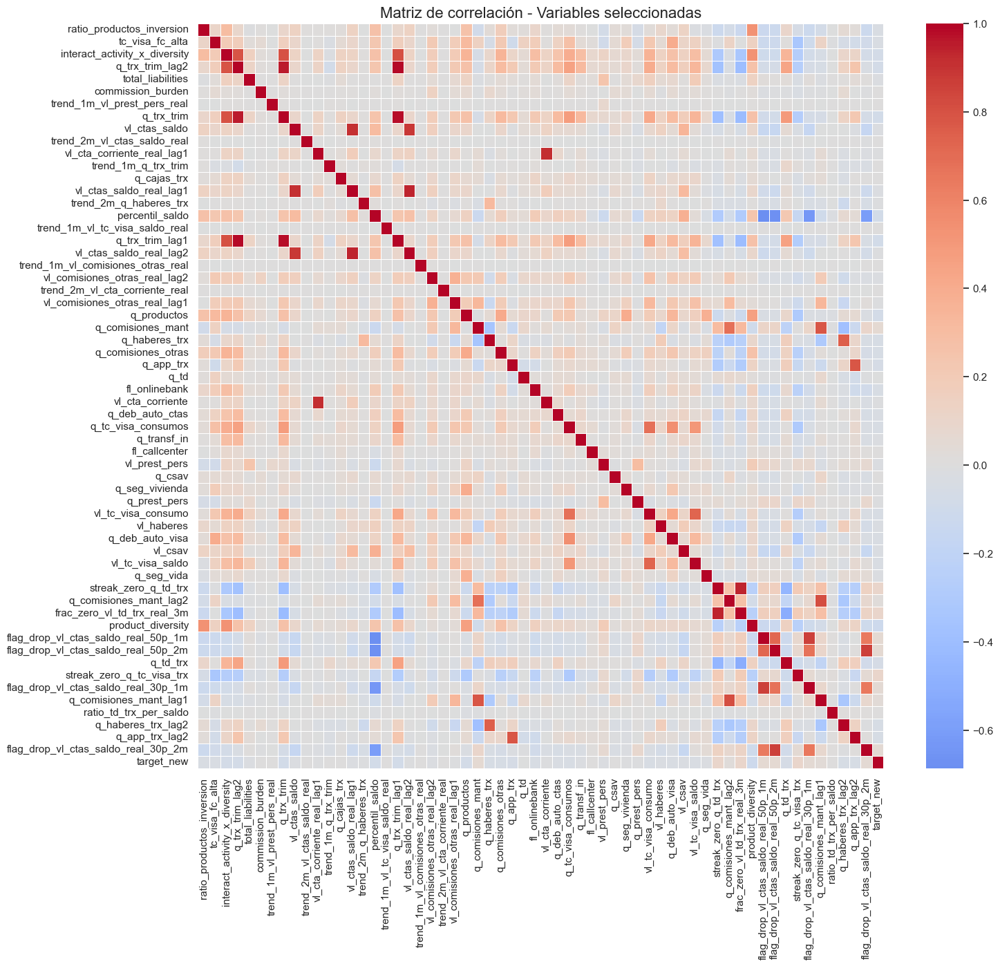

In [69]:
plt.figure(figsize=(16, 14))
sns.heatmap(
    matriz_corr,
    cmap="coolwarm",
    center=0,
    square=False,
    linewidths=0.5
)
plt.title("Matriz de correlación - Variables seleccionadas", fontsize=16)
plt.show()


In [70]:
corr_target = matriz_corr["target_new"].sort_values(ascending=False)
corr_target


target_new                             1.000
streak_zero_q_td_trx                   0.102
streak_zero_q_tc_visa_trx              0.100
frac_zero_vl_td_trx_real_3m            0.100
flag_drop_vl_ctas_saldo_real_50p_1m    0.064
q_comisiones_mant                      0.064
flag_drop_vl_ctas_saldo_real_50p_2m    0.062
flag_drop_vl_ctas_saldo_real_30p_1m    0.056
flag_drop_vl_ctas_saldo_real_30p_2m    0.053
q_comisiones_mant_lag1                 0.035
q_comisiones_mant_lag2                 0.025
commission_burden                      0.005
trend_1m_vl_prest_pers_real            0.005
q_cajas_trx                            0.003
fl_callcenter                          0.001
trend_1m_vl_comisiones_otras_real      0.001
ratio_td_trx_per_saldo                 0.000
q_csav                                 0.000
trend_2m_vl_cta_corriente_real        -0.000
trend_1m_q_trx_trim                   -0.000
trend_1m_vl_tc_visa_saldo_real        -0.001
trend_2m_vl_ctas_saldo_real           -0.001
q_td      

In [71]:
# Cantidad de variables a tomar
K = 10

# Top K positivas (excluyendo target_new)
top_pos = corr_target.drop("target_new").head(K).index.tolist()

# Top K negativas
top_neg = corr_target.drop("target_new").tail(K).index.tolist()

# Variables seleccionadas
vars_top = top_pos + top_neg
vars_top


['streak_zero_q_td_trx',
 'streak_zero_q_tc_visa_trx',
 'frac_zero_vl_td_trx_real_3m',
 'flag_drop_vl_ctas_saldo_real_50p_1m',
 'q_comisiones_mant',
 'flag_drop_vl_ctas_saldo_real_50p_2m',
 'flag_drop_vl_ctas_saldo_real_30p_1m',
 'flag_drop_vl_ctas_saldo_real_30p_2m',
 'q_comisiones_mant_lag1',
 'q_comisiones_mant_lag2',
 'q_haberes_trx_lag2',
 'q_app_trx',
 'q_td_trx',
 'interact_activity_x_diversity',
 'q_productos',
 'q_trx_trim_lag2',
 'q_trx_trim_lag1',
 'q_trx_trim',
 'percentil_saldo',
 'product_diversity']

In [72]:
# Matriz de correlación entre seleccionadas
matriz_small = df_corr[vars_top].corr()

matriz_small


,streak_zero_q_td_trx,streak_zero_q_tc_visa_trx,frac_zero_vl_td_trx_real_3m,flag_drop_vl_ctas_saldo_real_50p_1m,q_comisiones_mant,flag_drop_vl_ctas_saldo_real_50p_2m,flag_drop_vl_ctas_saldo_real_30p_1m,flag_drop_vl_ctas_saldo_real_30p_2m,q_comisiones_mant_lag1,q_comisiones_mant_lag2,q_haberes_trx_lag2,q_app_trx,q_td_trx,interact_activity_x_diversity,q_productos,q_trx_trim_lag2,q_trx_trim_lag1,q_trx_trim,percentil_saldo,product_diversity
streak_zero_q_td_trx,1.000,0.197,0.940,0.165,0.303,0.160,0.135,0.131,0.268,0.261,-0.242,-0.283,-0.454,-0.307,-0.121,-0.368,-0.379,-0.390,-0.288,-0.243
streak_zero_q_tc_visa_trx,0.197,1.000,0.191,0.078,-0.001,0.074,0.061,0.057,0.014,0.008,-0.027,-0.151,-0.103,-0.267,-0.301,-0.262,-0.272,-0.271,-0.160,-0.245
frac_zero_vl_td_trx_real_3m,0.940,0.191,1.000,0.164,0.325,0.154,0.133,0.123,0.286,0.278,-0.261,-0.283,-0.511,-0.325,-0.122,-0.397,-0.409,-0.418,-0.292,-0.244
flag_drop_vl_ctas_saldo_real_50p_1m,0.165,0.078,0.164,1.000,0.117,0.718,0.860,0.641,0.094,0.080,-0.032,-0.022,-0.108,-0.106,-0.035,-0.080,-0.079,-0.091,-0.686,-0.129
q_comisiones_mant,0.303,-0.001,0.325,0.117,1.000,0.111,0.108,0.099,0.778,0.678,-0.387,-0.134,-0.214,-0.056,-0.010,-0.057,-0.063,-0.056,-0.129,-0.097
flag_drop_vl_ctas_saldo_real_50p_2m,0.160,0.074,0.154,0.718,0.111,1.000,0.673,0.856,0.092,0.082,-0.025,-0.021,-0.115,-0.100,-0.037,-0.067,-0.071,-0.087,-0.670,-0.128
flag_drop_vl_ctas_saldo_real_30p_1m,0.135,0.061,0.133,0.860,0.108,0.673,1.000,0.648,0.089,0.075,-0.024,-0.015,-0.079,-0.083,-0.023,-0.059,-0.057,-0.067,-0.630,-0.105
flag_drop_vl_ctas_saldo_real_30p_2m,0.131,0.057,0.123,0.641,0.099,0.856,0.648,1.000,0.083,0.074,-0.013,-0.017,-0.088,-0.077,-0.023,-0.040,-0.045,-0.061,-0.604,-0.106
q_comisiones_mant_lag1,0.268,0.014,0.286,0.094,0.778,0.092,0.089,0.083,1.000,0.815,-0.336,-0.126,-0.188,-0.053,-0.023,-0.053,-0.058,-0.055,-0.098,-0.080
q_comisiones_mant_lag2,0.261,0.008,0.278,0.080,0.678,0.082,0.075,0.074,0.815,1.000,-0.321,-0.127,-0.182,-0.040,-0.021,-0.035,-0.043,-0.041,-0.085,-0.071


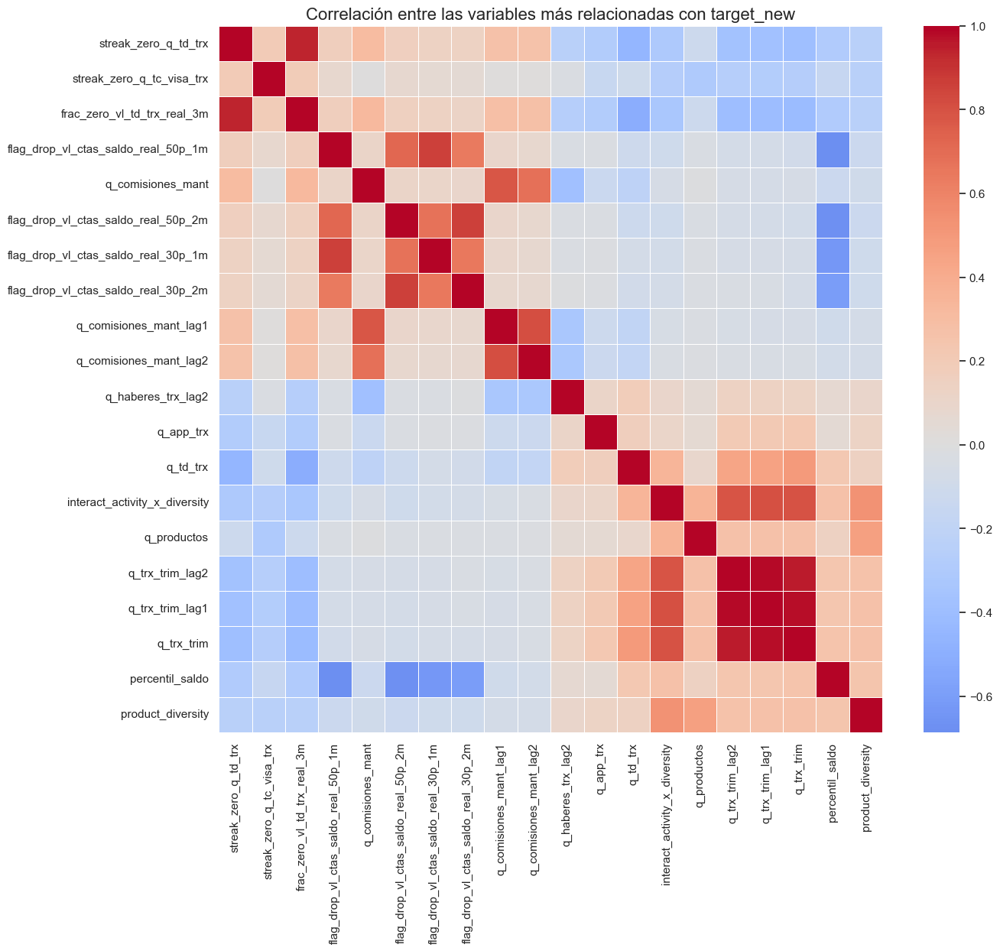

In [73]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 12))
sns.heatmap(
    matriz_small,
    annot=False,
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)
plt.title("Correlación entre las variables más relacionadas con target_new", fontsize=16)
plt.show()


In [74]:
import numpy as np

# Matriz solo entre seleccionadas
matriz_small = df_corr[vars_top].corr().abs()

# Ordenar por importancia absoluta (correlación con target)
ranking = corr_target.loc[vars_top].abs().sort_values(ascending=False).index.tolist()

selected_features = []
discarded_features = []

threshold = 0.80  # Umbral de correlación entre variables

for var in ranking:
    if var not in discarded_features:
        selected_features.append(var)
        # Eliminar futuras variables altamente correlacionadas con esta
        highly_corr = matriz_small.index[
            (matriz_small[var] > threshold) & (matriz_small.index != var)
        ].tolist()
        discarded_features.extend(highly_corr)

selected_features


['product_diversity',
 'streak_zero_q_td_trx',
 'streak_zero_q_tc_visa_trx',
 'percentil_saldo',
 'q_trx_trim',
 'q_productos',
 'flag_drop_vl_ctas_saldo_real_50p_1m',
 'q_comisiones_mant',
 'flag_drop_vl_ctas_saldo_real_50p_2m',
 'q_td_trx',
 'q_app_trx',
 'q_haberes_trx_lag2',
 'q_comisiones_mant_lag1']

## Prueba 8

In [75]:
features_seleccionadas = [
    'product_diversity',
    'streak_zero_q_td_trx',
    'streak_zero_q_tc_visa_trx',
    'percentil_saldo',
    'q_trx_trim',
    'q_productos',
    'flag_drop_vl_ctas_saldo_real_50p_1m',
    'q_comisiones_mant',
    'flag_drop_vl_ctas_saldo_real_50p_2m',
    'q_td_trx',
    'q_app_trx',
    'q_haberes_trx_lag2',
    'q_comisiones_mant_lag1'
]


In [76]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, accuracy_score, f1_score,
    precision_score, recall_score, matthews_corrcoef
)

# =============================================================================
#  1) Copiar datasets
# =============================================================================
df_train = df_train2.copy()
df_valid = df_valid2.copy()

# =============================================================================
#  2) Variables a usar
# =============================================================================
features = [
    'product_diversity',
    'streak_zero_q_td_trx',
    'streak_zero_q_tc_visa_trx',
    'percentil_saldo',
    'q_trx_trim',
    'q_productos',
    'flag_drop_vl_ctas_saldo_real_50p_1m',
    'q_comisiones_mant',
    'flag_drop_vl_ctas_saldo_real_50p_2m',
    'q_td_trx',
    'q_app_trx',
    'q_haberes_trx_lag2',
    'q_comisiones_mant_lag1'
]

# Asegurar que todas existan
cols_existentes = [c for c in features if c in df_train.columns]
cols_faltantes = set(features) - set(cols_existentes)

if cols_faltantes:
    print("⚠️ Faltan columnas:", cols_faltantes)

# =============================================================================
#  3) Armar datasets de modelado
# =============================================================================
df_train_mod = df_train[cols_existentes + ['target_new']].copy()
df_valid_mod = df_valid[cols_existentes + ['target_new']].copy()

X_train = df_train_mod.drop(columns='target_new')
y_train = df_train_mod['target_new']

X_valid = df_valid_mod.drop(columns='target_new')
y_valid = df_valid_mod['target_new']

# =============================================================================
#  4) Dummies (solo si hay categóricas)
# =============================================================================
X_train = pd.get_dummies(X_train, drop_first=True)
X_valid = pd.get_dummies(X_valid, drop_first=True)

# Alinear columnas
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)

print("Shapes:")
print("Train:", X_train.shape, "| Valid:", X_valid.shape)

# =============================================================================
#  5) LightGBM Dataset
# =============================================================================
train_data = lgb.Dataset(X_train, label=y_train)
valid_data = lgb.Dataset(X_valid, label=y_valid, reference=train_data)

# =============================================================================
#  6) Parámetros del modelo
# =============================================================================
params = {
    'objective': 'binary',
    'metric': 'auc',
    'learning_rate': 0.1,
    'num_leaves': 31,
    'verbose': -1,
    'seed': 42
}

# =============================================================================
#  7) Entrenamiento
# =============================================================================
model = lgb.train(
    params,
    train_data,
    num_boost_round=300,
    valid_sets=[valid_data],
    callbacks=[lgb.early_stopping(stopping_rounds=10)]
)

# =============================================================================
#  8) Predicción
# =============================================================================
y_pred_proba = model.predict(X_valid, num_iteration=model.best_iteration)
y_pred_class = (y_pred_proba >= 0.5).astype(int)

# =============================================================================
#  9) Métricas
# =============================================================================
print("\n🔍 Matriz de confusión:")
print(confusion_matrix(y_valid, y_pred_class))

print("\n📋 Reporte de clasificación:")
print(classification_report(y_valid, y_pred_class, digits=3))

print(f"AUC:      {roc_auc_score(y_valid, y_pred_proba):.4f}")
print(f"Accuracy: {accuracy_score(y_valid, y_pred_class):.4f}")
print(f"Precision:{precision_score(y_valid, y_pred_class):.4f}")
print(f"Recall:   {recall_score(y_valid, y_pred_class):.4f}")
print(f"F1-score: {f1_score(y_valid, y_pred_class):.4f}")

mcc = matthews_corrcoef(y_valid, y_pred_class)
print(f"MCC:      {mcc:.4f}")


Shapes:
Train: (109537, 13) | Valid: (109344, 13)
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[21]	valid_0's auc: 0.896013

🔍 Matriz de confusión:
[[108651     44]
 [   609     40]]

📋 Reporte de clasificación:
              precision    recall  f1-score   support

         0.0      0.994     1.000     0.997    108695
         1.0      0.476     0.062     0.109       649

    accuracy                          0.994    109344
   macro avg      0.735     0.531     0.553    109344
weighted avg      0.991     0.994     0.992    109344

AUC:      0.8960
Accuracy: 0.9940
Precision:0.4762
Recall:   0.0616
F1-score: 0.1091
MCC:      0.1698


# Aplico el modelo 7 en test

In [77]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, accuracy_score, f1_score,
    precision_score, recall_score, matthews_corrcoef
)

# =============================================================================
#  1) Preparación del dataset: copiar para no modificar los originales
# =============================================================================
df_train = df_train2.copy()
df_test  = df_test2.copy()   # ⬅️ ahora usamos df_test2

# Lista de features que querés usar
features_modelo = [
    'total_liabilities',
    'q_trx_trim',
    'vl_ctas_saldo',
    'q_comisiones_mant',
    'q_haberes_trx',
    'q_app_trx',
    'fl_onlinebank',
    'q_deb_auto_ctas',
    'q_productos'
]

# Columnas a excluir "administrativas"
cols_excluir = [
    'id', 'anio_mes', 'flag_baja', 'anio_mes_orig',
    'tc_visa_status', 'tc_visa_fc_alta_rango',
    'antiguedad_anios', 'antiguedad_rango',
    'edad_rango', 'target'
]

# Me quedo con target_new + features elegidas
df_train_prueba = df_train.drop(columns=[c for c in cols_excluir if c in df_train.columns],
                                errors='ignore')
df_test_prueba  = df_test.drop(columns=[c for c in cols_excluir if c in df_test.columns],
                               errors='ignore')

# Verificamos que todas las columnas existan
missing_train = [c for c in features_modelo + ['target_new'] if c not in df_train_prueba.columns]
missing_test  = [c for c in features_modelo + ['target_new'] if c not in df_test_prueba.columns]

if missing_train:
    print("⚠️ Faltan estas columnas en df_train_prueba:", missing_train)
if missing_test:
    print("⚠️ Faltan estas columnas en df_test_prueba:", missing_test)

# Subset explícito a las columnas del modelo
df_train_prueba = df_train_prueba[features_modelo + ['target_new']]
df_test_prueba  = df_test_prueba[features_modelo + ['target_new']]

# =============================================================================
#  2) Separar features y target
# =============================================================================
X_train = df_train_prueba.drop(columns='target_new')
y_train = df_train_prueba['target_new']

X_test = df_test_prueba.drop(columns='target_new')
y_test = df_test_prueba['target_new']

# =============================================================================
#  3) Dummies (por si alguna es categórica; si todas son numéricas, igual no molesta)
# =============================================================================
X_train = pd.get_dummies(X_train, drop_first=True)
X_test  = pd.get_dummies(X_test, drop_first=True)

# Alinear columnas entre train y test
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)

# =============================================================================
#  4) Crear datasets LightGBM
# =============================================================================
train_data = lgb.Dataset(X_train, label=y_train)
test_data  = lgb.Dataset(X_test,  label=y_test, reference=train_data)

# =============================================================================
#  5) Configurar parámetros LightGBM
# =============================================================================
params = {
    'objective': 'binary',
    'metric': 'auc',
    'learning_rate': 0.1,
    'num_leaves': 31,
    'verbose': -1,
    'seed': 42
}

# =============================================================================
#  6) Entrenamiento
# =============================================================================
model = lgb.train(
    params,
    train_data,
    num_boost_round=200,
    valid_sets=[test_data],               # ⬅️ early stopping monitorea test
    callbacks=[lgb.early_stopping(stopping_rounds=3)]
)

# =============================================================================
#  7) Predicción y evaluación sobre df_test2
# =============================================================================
y_pred_proba = model.predict(X_test, num_iteration=model.best_iteration)
y_pred_class = (y_pred_proba >= 0.5).astype(int)

print("\n🔍 Matriz de confusión (df_test2):")
print(confusion_matrix(y_test, y_pred_class))

print("\n📋 Reporte de clasificación (df_test2):")
print(classification_report(y_test, y_pred_class, digits=3))

print(f"AUC:      {roc_auc_score(y_test, y_pred_proba):.4f}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_class):.4f}")
print(f"Precision:{precision_score(y_test, y_pred_class):.4f}")
print(f"Recall:   {recall_score(y_test, y_pred_class):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred_class):.4f}")

mcc = matthews_corrcoef(y_test, y_pred_class)
print(f"MCC:      {mcc:.4f}")


Shape X_train: (109537, 9)
Shape X_test : (109306, 9)
Training until validation scores don't improve for 3 rounds
Early stopping, best iteration is:
[16]	valid_0's auc: 0.874317

🔍 Matriz de confusión (df_test2):
[[108659    107]
 [   528     12]]

📋 Reporte de clasificación (df_test2):
              precision    recall  f1-score   support

         0.0      0.995     0.999     0.997    108766
         1.0      0.101     0.022     0.036       540

    accuracy                          0.994    109306
   macro avg      0.548     0.511     0.517    109306
weighted avg      0.991     0.994     0.992    109306

AUC:      0.8743
Accuracy: 0.9942
Precision:0.1008
Recall:   0.0222
F1-score: 0.0364
MCC:      0.0452


# Aplico el modelo baseline en test

In [78]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, accuracy_score, f1_score,
    precision_score, recall_score, matthews_corrcoef
)

# =============================================================================
#  1) Preparación del dataset: copiar para no modificar los originales
# =============================================================================
df_train = df_train1.copy()
df_test  = df_test1.copy()   # ⬅️ ahora usamos df_test1

# Definir columnas a excluir
cols_excluir = [
    'id', 'anio_mes', 'flag_baja', 'anio_mes_orig',
    'tc_visa_status', 'tc_visa_fc_alta_rango',
    'antiguedad_anios', 'antiguedad_rango',
    'edad_rango', "target"
]

df_train_prueba = df_train.drop(columns=[c for c in cols_excluir if c in df_train.columns],
                                errors='ignore')
df_test_prueba  = df_test.drop(columns=[c for c in cols_excluir if c in df_test.columns],
                               errors='ignore')

# =============================================================================
#  2) Separar features y target
# =============================================================================
X_train = df_train_prueba.drop(columns='target_new')
y_train = df_train_prueba['target_new']

X_test = df_test_prueba.drop(columns='target_new')
y_test = df_test_prueba['target_new']

# =============================================================================
#  3) Crear dummies (por si hay categóricas)
# =============================================================================
X_train = pd.get_dummies(X_train, drop_first=True)
X_test  = pd.get_dummies(X_test, drop_first=True)

# Alinear columnas entre train y test
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)

# =============================================================================
#  4) Crear datasets LightGBM
# =============================================================================
train_data = lgb.Dataset(X_train, label=y_train)
test_data  = lgb.Dataset(X_test,  label=y_test, reference=train_data)

# =============================================================================
#  5) Configurar parámetros LightGBM
# =============================================================================
params = {
    'objective': 'binary',
    'metric': 'auc',
    'learning_rate': 0.1,
    'num_leaves': 31,
    'verbose': -1,
    'seed': 42
}

# =============================================================================
#  6) Entrenamiento
# =============================================================================
model = lgb.train(
    params,
    train_data,
    num_boost_round=200,
    valid_sets=[test_data],
    callbacks=[lgb.early_stopping(stopping_rounds=3)]
)

# =============================================================================
#  7) Predicción y evaluación en df_test1
# =============================================================================
y_pred_proba = model.predict(X_test, num_iteration=model.best_iteration)
y_pred_class = (y_pred_proba >= 0.5).astype(int)

print("🔍 Matriz de confusión (df_test1):")
print(confusion_matrix(y_test, y_pred_class))

print("\n📋 Reporte de clasificación (df_test1):")
print(classification_report(y_test, y_pred_class, digits=3))

print(f"AUC:      {roc_auc_score(y_test, y_pred_proba):.4f}")
print(f"Accuracy: {accuracy_score(y_test, y_pred_class):.4f}")
print(f"Precision:{precision_score(y_test, y_pred_class):.4f}")
print(f"Recall:   {recall_score(y_test, y_pred_class):.4f}")
print(f"F1-score: {f1_score(y_test, y_pred_class):.4f}")

mcc = matthews_corrcoef(y_test, y_pred_class)
print(f"Matthews Correlation Coefficient (MCC): {mcc:.4f}")


Shape X_train: (109537, 78)
Shape X_test : (109306, 78)
Training until validation scores don't improve for 3 rounds
Early stopping, best iteration is:
[17]	valid_0's auc: 0.874827
🔍 Matriz de confusión (df_test1):
[[108620    146]
 [   521     19]]

📋 Reporte de clasificación (df_test1):
              precision    recall  f1-score   support

         0.0      0.995     0.999     0.997    108766
         1.0      0.115     0.035     0.054       540

    accuracy                          0.994    109306
   macro avg      0.555     0.517     0.525    109306
weighted avg      0.991     0.994     0.992    109306

AUC:      0.8748
Accuracy: 0.9939
Precision:0.1152
Recall:   0.0352
F1-score: 0.0539
Matthews Correlation Coefficient (MCC): 0.0611


Aplicando el modelo 7 en test se llega a un AUC de 0.87, mismo resultado que la aplicación del modelo baseline pero con menos variables.

# Presentación de resultados:
El modelo final, por resultados similares en cuanto al AUC y teniendo en cuenta la parsimonia del mismo, es el modelo 7 

In [79]:
# =============================================================================
#  1) Preparación del dataset: copiar para no modificar los originales
# =============================================================================
df_train = df_train2.copy()
df_test  = df_test2.copy()   # ⬅️ ahora usamos df_test2

# Lista de features que querés usar
features_modelo = [
    'total_liabilities',
    'q_trx_trim',
    'vl_ctas_saldo',
    'q_comisiones_mant',
    'q_haberes_trx',
    'q_app_trx',
    'fl_onlinebank',
    'q_deb_auto_ctas',
    'q_productos'
]

# Columnas a excluir "administrativas"
cols_excluir = [
    'id', 'anio_mes', 'flag_baja', 'anio_mes_orig',
    'tc_visa_status', 'tc_visa_fc_alta_rango',
    'antiguedad_anios', 'antiguedad_rango',
    'edad_rango', 'target'
]

# Me quedo con target_new + features elegidas
df_train_prueba = df_train.drop(columns=[c for c in cols_excluir if c in df_train.columns],
                                errors='ignore')
df_test_prueba  = df_test.drop(columns=[c for c in cols_excluir if c in df_test.columns],
                               errors='ignore')

# Verificamos que todas las columnas existan
missing_train = [c for c in features_modelo + ['target_new'] if c not in df_train_prueba.columns]
missing_test  = [c for c in features_modelo + ['target_new'] if c not in df_test_prueba.columns]

if missing_train:
    print("⚠️ Faltan estas columnas en df_train_prueba:", missing_train)
if missing_test:
    print("⚠️ Faltan estas columnas en df_test_prueba:", missing_test)

# Subset explícito a las columnas del modelo
df_train_prueba = df_train_prueba[features_modelo + ['target_new']]
df_test_prueba  = df_test_prueba[features_modelo + ['target_new']]

# =============================================================================
#  2) Separar features y target
# =============================================================================
X_train = df_train_prueba.drop(columns='target_new')
y_train = df_train_prueba['target_new']

X_test = df_test_prueba.drop(columns='target_new')
y_test = df_test_prueba['target_new']

# =============================================================================
#  3) Dummies (por si alguna es categórica; si todas son numéricas, igual no molesta)
# =============================================================================
X_train = pd.get_dummies(X_train, drop_first=True)
X_test  = pd.get_dummies(X_test, drop_first=True)

# Alinear columnas entre train y test
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)

# =============================================================================
#  4) Crear datasets LightGBM
# =============================================================================
train_data = lgb.Dataset(X_train, label=y_train)
test_data  = lgb.Dataset(X_test,  label=y_test, reference=train_data)

# =============================================================================
#  5) Configurar parámetros LightGBM
# =============================================================================
params = {
    'objective': 'binary',
    'metric': 'auc',
    'learning_rate': 0.1,
    'num_leaves': 31,
    'verbose': -1,
    'seed': 42
}

# =============================================================================
#  6) Entrenamiento
# =============================================================================
model = lgb.train(
    params,
    train_data,
    num_boost_round=200,
    valid_sets=[test_data],               # ⬅️ early stopping monitorea test
    callbacks=[lgb.early_stopping(stopping_rounds=3)]
)

# =============================================================================
#  7) Predicción y evaluación sobre df_test2
# =============================================================================
y_pred_proba = model.predict(X_test, num_iteration=model.best_iteration)

Shape X_train: (109537, 9)
Shape X_test : (109306, 9)
Training until validation scores don't improve for 3 rounds
Early stopping, best iteration is:
[16]	valid_0's auc: 0.874317


In [80]:
import pandas as pd
import numpy as np
from scipy.stats import ks_2samp  

# =============================================================================
#  1) Armar DataFrame con probabilidades y target
# =============================================================================
df_scores = pd.DataFrame({
    'probabilidad': y_pred_proba,
    'target_real': y_test.values  # asumo 0 = sigue, 1 = churn
})

# =============================================================================
#  2) Crear deciles (1 = mayor probabilidad de churn, 10 = menor)
# =============================================================================
# Deciles de 0 a 9 (0 = prob más baja, 9 = más alta)
df_scores['decil'] = pd.qcut(
    df_scores['probabilidad'],
    q=10,
    labels=False,
    duplicates='drop'
)

# Invertimos para que 1 sea el más alto (top riesgo)
df_scores['decil'] = 10 - df_scores['decil']   # queda 1..10

# =============================================================================
#  3) Tabla de estadísticos por decil
# =============================================================================
tabla_deciles = (
    df_scores
      .groupby('decil', as_index=False)
      .agg(
          n_clientes=('probabilidad', 'count'),
          n_bajas=('target_real', 'sum'),
          prob_min=('probabilidad', 'min'),
          prob_max=('probabilidad', 'max'),
          prob_media=('probabilidad', 'mean'),
          prob_mediana=('probabilidad', 'median')
      )
      .sort_values('decil')  # 1 al 10
)

# Tasa de attrition por decil
tabla_deciles['tasa_baja'] = tabla_deciles['n_bajas'] / tabla_deciles['n_clientes']

# Totales
total_clientes = tabla_deciles['n_clientes'].sum()
total_bajas = tabla_deciles['n_bajas'].sum()

# Porcentajes y acumulados (para ver si ordena bien)
tabla_deciles['pct_clientes'] = tabla_deciles['n_clientes'] / total_clientes
tabla_deciles['pct_bajas'] = tabla_deciles['n_bajas'] / total_bajas

tabla_deciles['pct_clientes_acum'] = tabla_deciles['pct_clientes'].cumsum()
tabla_deciles['pct_bajas_acum'] = tabla_deciles['pct_bajas'].cumsum()

# Lift por decil (tasa_baja_decil / tasa_baja_global)
tasa_baja_global = total_bajas / total_clientes
tabla_deciles['lift'] = tabla_deciles['tasa_baja'] / tasa_baja_global

print("\n📊 Tabla por deciles de probabilidad (1 = mayor riesgo):")
print(tabla_deciles.round(4))

# =============================================================================
#  4) KS (Kolmogorov-Smirnov)
# =============================================================================
# KS continuo sobre las distribuciones de probabilidad
scores_baja = df_scores.loc[df_scores['target_real'] == 1, 'probabilidad']
scores_no_baja = df_scores.loc[df_scores['target_real'] == 0, 'probabilidad']

ks_stat, ks_pvalue = ks_2samp(scores_baja, scores_no_baja)

print("\n📈 KS (Kolmogorov-Smirnov) sobre las probabilidades:")
print(f"KS statistic: {ks_stat:.4f}")
print(f"p-value     : {ks_pvalue:.4e}")

# =============================================================================
#  5) (Opcional) KS por deciles (diferencia de % acumulado)
# =============================================================================
ks_por_decil = (
    tabla_deciles
      .assign(
          diff_acum=lambda d: (d['pct_bajas_acum'] - d['pct_clientes_acum']).abs()
      )
      [['decil', 'pct_clientes_acum', 'pct_bajas_acum', 'diff_acum']]
)

ks_max = ks_por_decil['diff_acum'].max()

print("\n📈 KS aproximado por deciles (diferencia máxima de acumulados):")
print(ks_por_decil.round(4))
print(f"\nKS máximo por deciles (aprox): {ks_max:.4f}")



📊 Tabla por deciles de probabilidad (1 = mayor riesgo):
   decil  n_clientes  n_bajas  prob_min  prob_max  prob_media  prob_mediana  tasa_baja  pct_clientes  pct_bajas  pct_clientes_acum  pct_bajas_acum  lift
0      3       10931      336     0.012     0.827       0.045         0.025      0.031         0.100      0.622              0.100           0.622 6.222
1      4       10917       96     0.006     0.012       0.009         0.008      0.009         0.100      0.178              0.200           0.800 1.780
2      5       10810       47     0.004     0.006       0.005         0.005      0.004         0.099      0.087              0.299           0.887 0.880
3      6       10722       19     0.003     0.004       0.004         0.004      0.002         0.098      0.035              0.397           0.922 0.359
4      7       10542       11     0.003     0.003       0.003         0.003      0.001         0.096      0.020              0.493           0.943 0.211
5      8        7658     

El decil 3 (está mal las etiquetas) concentra el 10% de los clientes pero captura el 62.2% de todas las bajas. Si también consideramos el decil 4 entonces se estarían capturando el 80% de las bajas con sólo el 20% de los clientes que tienen mayor riesgo de darse de baja en 2 meses.

## Curva ROC

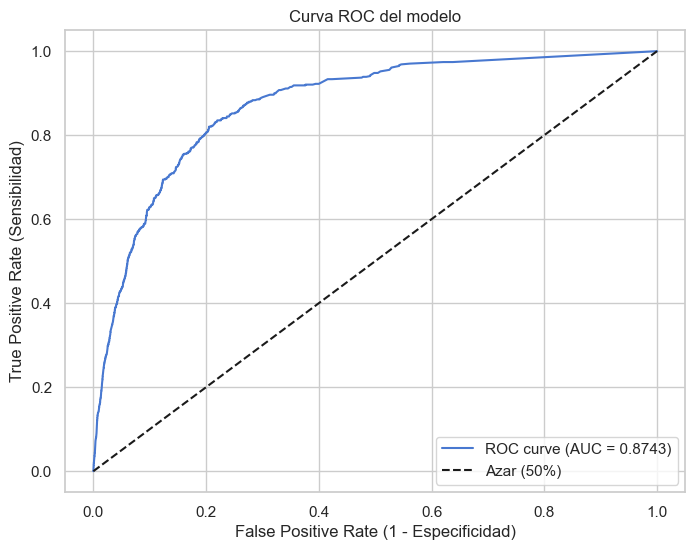

In [81]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt


y_true = y_test        
y_score = y_pred_proba

# Calcular curvas
fpr, tpr, thresholds = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0,1], [0,1], 'k--', label='Azar (50%)')

plt.xlabel('False Positive Rate (1 - Especificidad)')
plt.ylabel('True Positive Rate (Sensibilidad)')
plt.title('Curva ROC del modelo')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


# Predicciones

In [86]:
df_predicciones = pd.DataFrame({
    'id': df_test2['id'],
    'probabilidad_churn': y_pred_proba,
})

df_predicciones.head(20)


,id,probabilidad_churn
4,29183981,0.002
11,29184630,0.004
18,29185587,0.003
25,29188277,0.011
32,29188490,0.002
39,29188883,0.006
46,29189950,0.004
53,29190599,0.002
60,29191573,0.010
67,29192154,0.004


In [ ]:
df_predicciones.to_excel("predicciones_churn_test.xlsx", index=False)
print("Archivo generado: predicciones_churn_test.xlsx")

# Otros códigos que probé y quedaron descartados

## Features

In [82]:
# def crear_ratios_y_variaciones(df, verbose=True):
#     """
#     Crea ratios y variaciones avanzadas para predicción de churn
#     """
#     df = df.copy()
    
#     if verbose:
#         print("🎯 Creando ratios y variaciones avanzadas...")
#         print(f"   Dataset inicial: {df.shape}")
    
#     feature_count = 0
    
#     # =========================================================================
#     # 1. RATIOS DE ACTIVIDAD VS NIVEL (¿está usando menos sus productos?)
#     # =========================================================================
#     if verbose:
#         print("\n1️⃣ Ratios de actividad/nivel...")
    
#     # Ratio: Transacciones TD vs Saldo en cuenta
#     if 'q_td_trx' in df.columns and 'vl_ctas_saldo_real' in df.columns:
#         df['ratio_td_trx_per_saldo'] = df['q_td_trx'] / (df['vl_ctas_saldo_real'] / 10000 + 1)
#         feature_count += 1
    
#     # Ratio: Transacciones TC vs Límite
#     if 'q_tc_visa_trx' in df.columns and 'vl_tc_visa_limite_compra' in df.columns:
#         df['ratio_tc_trx_per_limite'] = df['q_tc_visa_trx'] / (df['vl_tc_visa_limite_compra'] / 10000 + 1)
#         feature_count += 1
    
#     # Ratio: Consumo TC vs Límite (intensidad de uso)
#     if 'vl_tc_visa_consumo_real' in df.columns and 'vl_tc_visa_limite_compra' in df.columns:
#         df['ratio_consumo_vs_limite'] = df['vl_tc_visa_consumo_real'] / (df['vl_tc_visa_limite_compra'] + 1)
#         feature_count += 1
    
#     # Ratio: Inversiones vs Haberes (¿está invirtiendo con nosotros?)
#     if 'total_assets' in df.columns and 'vl_haberes_real' in df.columns:
#         df['ratio_assets_vs_income'] = df['total_assets'] / (df['vl_haberes_real'] * 3 + 1)  # 3 meses
#         feature_count += 1
    
#     # Ratio: Débitos automáticos vs Haberes (engagement con pagos)
#     if 'monthly_commitments' in df.columns and 'vl_haberes_real' in df.columns:
#         df['ratio_commitments_vs_income'] = df['monthly_commitments'] / (df['vl_haberes_real'] + 1)
#         feature_count += 1
    
#     if verbose:
#         print(f"   ✅ {feature_count} ratios de actividad creados")
    
#     # =========================================================================
#     # 2. RATIOS DE DISTRIBUCIÓN DE USO (¿dónde opera más?)
#     # =========================================================================
#     if verbose:
#         print("\n2️⃣ Ratios de distribución de uso...")
    
#     prev_count = feature_count
    
#     # Ratio: Cajeros propios vs externos (lealtad)
#     if 'vl_atm_real' in df.columns and 'vl_atm2_real' in df.columns:
#         df['ratio_atm_interno_vs_externo'] = df['vl_atm_real'] / (df['vl_atm2_real'] + 1)
#         df['ratio_atm_externo_vs_total'] = df['vl_atm2_real'] / (df['vl_atm_real'] + df['vl_atm2_real'] + 1)
#         feature_count += 2
    
#     # Ratio: Transferencias enviadas vs recibidas
#     if 'vl_transf_out_real' in df.columns and 'vl_transf_inf_real' in df.columns:
#         df['ratio_transf_out_vs_in'] = df['vl_transf_out_real'] / (df['vl_transf_inf_real'] + 1)
#         df['ratio_transf_in_vs_haberes'] = df['vl_transf_inf_real'] / (df['vl_haberes_real'] + 1) if 'vl_haberes_real' in df.columns else 0
#         feature_count += 2
    
#     # Ratio: Pagos de servicios vs Haberes (¿paga servicios aquí?)
#     if 'vl_pago_serv_real' in df.columns and 'vl_haberes_real' in df.columns:
#         df['ratio_pago_serv_vs_haberes'] = df['vl_pago_serv_real'] / (df['vl_haberes_real'] + 1)
#         feature_count += 1
    
#     # Ratio: Cheques emitidos vs depositados
#     if 'vl_cheq_emit_real' in df.columns and 'vl_cheq_dep_real' in df.columns:
#         df['ratio_cheq_emit_vs_dep'] = df['vl_cheq_emit_real'] / (df['vl_cheq_dep_real'] + 1)
#         feature_count += 1
    
#     if verbose:
#         print(f"   ✅ {feature_count - prev_count} ratios de distribución creados")
    
#     # =========================================================================
#     # 3. VARIACIONES PORCENTUALES (mes actual vs mes anterior)
#     # =========================================================================
#     if verbose:
#         print("\n3️⃣ Variaciones porcentuales (MoM)...")
    
#     prev_count = feature_count
    
#     # Variables clave para variación MoM
#     vars_para_var = [
#         'vl_ctas_saldo_real', 'vl_tc_visa_consumo_real', 'vl_haberes_real',
#         'vl_td_trx_real', 'q_td_trx', 'q_tc_visa_trx', 'activity_score'
#     ]
    
#     for col in vars_para_var:
#         if col in df.columns and f'{col}_lag1' in df.columns:
#             var_name = f'var_pct_mom_{col}'
#             df[var_name] = (df[col] - df[f'{col}_lag1']) / (df[f'{col}_lag1'].abs() + 1)
#             feature_count += 1
    
#     if verbose:
#         print(f"   ✅ {feature_count - prev_count} variaciones MoM creadas")
    
#     # =========================================================================
#     # 4. ACELERACIONES (cambio de la tendencia)
#     # =========================================================================
#     if verbose:
#         print("\n4️⃣ Aceleraciones (segunda derivada)...")
    
#     prev_count = feature_count
    
#     # Variables para aceleración
#     vars_para_acel = [
#         'vl_ctas_saldo_real', 'vl_tc_visa_consumo_real', 'vl_haberes_real',
#         'activity_score', 'product_diversity'
#     ]
    
#     for col in vars_para_acel:
#         if col in df.columns and f'{col}_lag1' in df.columns and f'{col}_lag2' in df.columns:
#             acel_name = f'accel_{col}'
#             cambio_actual = df[col] - df[f'{col}_lag1']
#             cambio_anterior = df[f'{col}_lag1'] - df[f'{col}_lag2']
#             df[acel_name] = cambio_actual - cambio_anterior
#             feature_count += 1
    
#     if verbose:
#         print(f"   ✅ {feature_count - prev_count} aceleraciones creadas")
    
#     # =========================================================================
#     # 5. RATIOS DE MOMENTUM (tendencia reciente vs histórica)
#     # =========================================================================
#     if verbose:
#         print("\n5️⃣ Ratios de momentum...")
    
#     prev_count = feature_count
    
#     # Promedio últimos 3 meses vs valor actual
#     vars_para_momentum = [
#         'vl_ctas_saldo_real', 'vl_tc_visa_consumo_real', 'activity_score'
#     ]
    
#     for col in vars_para_momentum:
#         if all(f'{col}_lag{i}' in df.columns for i in [1, 2, 3]):
#             avg_3m = (df[f'{col}_lag1'] + df[f'{col}_lag2'] + df[f'{col}_lag3']) / 3
#             df[f'momentum_{col}'] = df[col] / (avg_3m + 1)
#             feature_count += 1
    
#     if verbose:
#         print(f"   ✅ {feature_count - prev_count} ratios de momentum creados")
    
#     # =========================================================================
#     # 6. CONSISTENCIA (coeficiente de variación)
#     # =========================================================================
#     if verbose:
#         print("\n6️⃣ Métricas de consistencia...")
    
#     prev_count = feature_count
    
#     # CV = std / mean (cuanto más alto, más inconsistente)
#     vars_para_cv = ['vl_haberes_real', 'vl_tc_visa_consumo_real', 'activity_score']
    
#     for col in vars_para_cv:
#         if f'volatility_3m_{col}' in df.columns:
#             # Calcular media últimos 3 meses
#             if all(f'{col}_lag{i}' in df.columns for i in [1, 2, 3]):
#                 mean_3m = (df[f'{col}_lag1'] + df[f'{col}_lag2'] + df[f'{col}_lag3']) / 3
#                 df[f'cv_{col}'] = df[f'volatility_3m_{col}'] / (mean_3m.abs() + 1)
#                 feature_count += 1
    
#     if verbose:
#         print(f"   ✅ {feature_count - prev_count} métricas de consistencia creadas")
    
#     # =========================================================================
#     # 7. RATIOS DE CROSS-SELLING (uso de múltiples productos)
#     # =========================================================================
#     if verbose:
#         print("\n7️⃣ Ratios de cross-selling...")
    
#     prev_count = feature_count
    
#     # Ratio: Productos de inversión vs productos de transacción
#     inv_cols = [c for c in df.columns if any(x in c for x in ['pl_fijo', 'inv']) and '_real' in c]
#     if inv_cols and 'product_diversity' in df.columns:
#         tiene_inversiones = (df[inv_cols].sum(axis=1) > 0).astype(int)
#         df['ratio_productos_inversion'] = tiene_inversiones / (df['product_diversity'] + 1)
#         feature_count += 1
    
#     # Ratio: Productos de deuda vs productos de ahorro
#     if 'total_liabilities' in df.columns and 'total_assets' in df.columns:
#         df['ratio_debt_to_savings'] = df['total_liabilities'] / (df['total_assets'] + 1)
#         feature_count += 1
    
#     if verbose:
#         print(f"   ✅ {feature_count - prev_count} ratios de cross-selling creados")
    
#     # =========================================================================
#     # 8. FEATURES DE INTERACCIÓN (multiplicaciones significativas)
#     # =========================================================================
#     if verbose:
#         print("\n8️⃣ Features de interacción...")
    
#     prev_count = feature_count
    
#     # Interacciones basadas en correlaciones conocidas
#     if 'antiguedad_cliente' in df.columns and 'product_diversity' in df.columns:
#         df['interact_antiguedad_x_diversity'] = df['antiguedad_cliente'] * df['product_diversity']
#         feature_count += 1
    
#     if 'vl_haberes_real' in df.columns and 'tc_visa_utilization' in df.columns:
#         df['interact_haberes_x_utilization'] = df['vl_haberes_real'] * df['tc_visa_utilization']
#         feature_count += 1
    
#     if 'activity_score' in df.columns and 'product_diversity' in df.columns:
#         df['interact_activity_x_diversity'] = df['activity_score'] * df['product_diversity']
#         feature_count += 1
    
#     if 'net_monthly_balance' in df.columns and 'liquidity_ratio' in df.columns:
#         df['interact_balance_x_liquidity'] = df['net_monthly_balance'] * df['liquidity_ratio']
#         feature_count += 1
    
#     if verbose:
#         print(f"   ✅ {feature_count - prev_count} interacciones creadas")
    
#     # =========================================================================
#     # 9. SEÑALES COMBINADAS DE CHURN (flags compuestos)
#     # =========================================================================
#     if verbose:
#         print("\n9️⃣ Señales combinadas de churn...")
    
#     prev_count = feature_count
    
#     # Flag: Cliente en declive (múltiples señales negativas)
#     condiciones_declive = []
    
#     if 'activity_trend' in df.columns:
#         condiciones_declive.append(df['activity_trend'] < -0.2)
#     if 'product_diversity_change' in df.columns:
#         condiciones_declive.append(df['product_diversity_change'] < 0)
#     if 'net_balance_trend' in df.columns:
#         condiciones_declive.append(df['net_balance_trend'] < 0)
    
#     if condiciones_declive:
#         df['flag_multiple_decline_signals'] = sum(condiciones_declive).clip(0, 3)
#         feature_count += 1
    
#     # Flag: Cliente en riesgo financiero
#     condiciones_riesgo = []
    
#     if 'tc_visa_utilization' in df.columns:
#         condiciones_riesgo.append(df['tc_visa_utilization'] > 0.8)
#     if 'has_rejected_checks' in df.columns:
#         condiciones_riesgo.append(df['has_rejected_checks'] == 1)
#     if 'liquidity_ratio' in df.columns:
#         condiciones_riesgo.append(df['liquidity_ratio'] < 1)
    
#     if condiciones_riesgo:
#         df['flag_financial_stress'] = sum(condiciones_riesgo).clip(0, 3)
#         feature_count += 1
    
#     # Flag: Cliente desconectándose
#     condiciones_desconexion = []
    
#     if 'atm_external_preference' in df.columns:
#         condiciones_desconexion.append(df['atm_external_preference'] > 0.5)
#     if 'callcenter_spike' in df.columns:
#         condiciones_desconexion.append(df['callcenter_spike'] == 1)
#     if 'activity_score' in df.columns and 'activity_score_lag3' in df.columns:
#         condiciones_desconexion.append(df['activity_score'] < df['activity_score_lag3'] * 0.5)
    
#     if condiciones_desconexion:
#         df['flag_disconnecting'] = sum(condiciones_desconexion).clip(0, 3)
#         feature_count += 1
    
#     if verbose:
#         print(f"   ✅ {feature_count - prev_count} señales combinadas creadas")
    
#     # =========================================================================
#     # 10. PERCENTILES Y RANKINGS (posición relativa)
#     # =========================================================================
#     if verbose:
#         print("\n🔟 Percentiles y rankings...")
    
#     prev_count = feature_count
    
#     # Percentil de saldo dentro del mes
#     if 'vl_ctas_saldo_real' in df.columns:
#         df['percentil_saldo'] = df.groupby('anio_mes')['vl_ctas_saldo_real'].rank(pct=True)
#         feature_count += 1
    
#     # Percentil de actividad dentro del mes
#     if 'activity_score' in df.columns:
#         df['percentil_activity'] = df.groupby('anio_mes')['activity_score'].rank(pct=True)
#         feature_count += 1
    
#     # Cambio de percentil (¿está cayendo en ranking?)
#     if 'percentil_activity' in df.columns:
#         df['percentil_activity_lag3'] = df.groupby('id')['percentil_activity'].shift(3)
#         df['cambio_percentil_activity'] = df['percentil_activity'] - df['percentil_activity_lag3']
#         feature_count += 1
    
#     if verbose:
#         print(f"   ✅ {feature_count - prev_count} percentiles creados")
    
#     # =========================================================================
#     # RESUMEN FINAL
#     # =========================================================================
#     if verbose:
#         print("\n" + "="*70)
#         print("✅ RATIOS Y VARIACIONES COMPLETADOS")
#         print("="*70)
#         print(f"📊 Total de nuevas features: {feature_count}")
#         print(f"📊 Shape final: {df.shape}")
#         print("="*70)
    
#     return df

# df_completo = crear_ratios_y_variaciones(df_filtrado, verbose=True)

In [83]:
# # ============================================================================
# # CELDA 1: DEFINIR FUNCIONES (copiar todo el código de features_completo.py)
# # ============================================================================

# import pandas as pd
# import numpy as np
# from sklearn.linear_model import LinearRegression

# def crear_features_completo(df, mes_referencia='abril'):
   
#     df = df.copy()
#     features_creadas = []
    
#     # ========================================================================
#     # PASO 1: LAGS (1, 2, 3 meses atrás)
#     # ========================================================================
#     print("\n1. Creando lags (1, 2, 3 meses)...")
    
#     vars_importantes = [
#         # Tarjeta de crédito
#         'vl_tc_visa_consumo', 'vl_tc_visa_saldo', 'vl_tc_visa_pagado',
#         'vl_tc_visa_limite_compra', 'q_tc_visa_trx',
#         # Haberes (MUY importante)
#         'vl_haberes',
#         # Actividad
#         'q_atm_trx', 'q_td_trx', 'q_cheq_emit', 'q_cheq_dep',
#         # Comisiones y callcenter
#         'vl_comisiones_mant', 'q_callcenter_trx',
#         # Cuentas
#         'vl_cta_corriente', 'vl_csav', 'vl_pl_fijo_ars', 'vl_pl_fijo_usd','vl_inv_ars', 'vl_inv_usd',
#         # Préstamos
#         'vl_prest_pers', 'vl_prest_hipo',
#         # Transferencias
#         'vl_transf_out', 'vl_transf_in'
#     ]
    
#     # Filtrar solo las que existen en tu dataset
#     vars_importantes = [v for v in vars_importantes if v in df.columns]
    
#     for var in vars_importantes:
#         # Lag 1, 2, 3
#         for lag in [1, 2, 3]:
#             nombre_lag = f'{var}_lag{lag}'
#             df[nombre_lag] = df[var].shift(lag)
#             features_creadas.append(nombre_lag)
    
#     print(f"   ✓ {len(vars_importantes) * 3} lags creados")
    
#     # ========================================================================
#     # PASO 2: RATIOS (inmunes a inflación)
#     # ========================================================================
#     print("\n2. Creando ratios...")
    
#     # Ratio uso de límite TC
#     df['ratio_uso_limite_tc'] = np.where(
#         df['vl_tc_visa_limite_compra'] > 0,
#         df['vl_tc_visa_saldo'] / df['vl_tc_visa_limite_compra'],
#         np.nan
#     )
#     features_creadas.append('ratio_uso_limite_tc')
    
#     # Ratio pago/consumo TC
#     df['ratio_pago_consumo_tc'] = np.where(
#         df['vl_tc_visa_consumo'] > 0,
#         df['vl_tc_visa_pagado'] / df['vl_tc_visa_consumo'],
#         np.nan
#     )
#     features_creadas.append('ratio_pago_consumo_tc')
    
#     # Ratio consumo/saldo TC
#     df['ratio_consumo_saldo_tc'] = np.where(
#         df['vl_tc_visa_saldo'] > 0,
#         df['vl_tc_visa_consumo'] / df['vl_tc_visa_saldo'],
#         np.nan
#     )
#     features_creadas.append('ratio_consumo_saldo_tc')
    
#     # Crear activos y pasivos totales
#     df['activos_totales'] = (
#         df['vl_cta_corriente'].fillna(0) + 
#         df['vl_csav'].fillna(0) + 
#         df['vl_pl_fijo_ars'].fillna(0) + 
#         df['vl_pl_fijo_usd'].fillna(0) +
#         df['vl_inv_ars'].fillna(0) +
#         df['vl_inv_usd'].fillna(0)
#     )
#     features_creadas.append('activos_totales')
    
#     df['pasivos_totales'] = (
#         df['vl_tc_visa_saldo'].fillna(0) + 
#         df['vl_prest_pers'].fillna(0) + 
#         df['vl_prest_hipo'].fillna(0)
#     )
#     features_creadas.append('pasivos_totales')
    
#     # Ratio activos/pasivos
#     df['ratio_activos_pasivos'] = np.where(
#         df['pasivos_totales'] > 0,
#         df['activos_totales'] / df['pasivos_totales'],
#         np.nan
#     )
#     features_creadas.append('ratio_activos_pasivos')
    
#     # Ratio transferencias salida/entrada
#     df['ratio_transf_salida_entrada'] = np.where(
#         (df['vl_transf_in'].fillna(0) > 0),
#         df['vl_transf_out'].fillna(0) / df['vl_transf_in'].fillna(0),
#         np.nan
#     )
#     features_creadas.append('ratio_transf_salida_entrada')
    
#     # Ingresos y egresos
#     df['ingresos_totales'] = df['vl_haberes'].fillna(0) + df['vl_transf_in'].fillna(0)
#     features_creadas.append('ingresos_totales')
    
#     df['egresos_totales'] = (
#         df['vl_transf_out'].fillna(0) + 
#         df['vl_pago_serv'].fillna(0) + 
#         df['vl_tc_visa_consumo'].fillna(0)
#     )
#     features_creadas.append('egresos_totales')
    
#     # Ratio comisiones/ingresos
#     df['ratio_comisiones_ingresos'] = np.where(
#         df['ingresos_totales'] > 0,
#         df['vl_comisiones_mant'].fillna(0) / df['ingresos_totales'],
#         np.nan
#     )
#     features_creadas.append('ratio_comisiones_ingresos')
    
#     print(f"   ✓ 9 ratios creados")
    
#     # ========================================================================
#     # PASO 3: DELTAS (cambios absolutos)
#     # ========================================================================
#     print("\n3. Creando deltas (cambios)...")
    
#     # Actividad total
#     df['actividad_total'] = (
#         df['q_atm_trx'].fillna(0) + 
#         df['q_td_trx'].fillna(0) + 
#         df['q_tc_visa_trx'].fillna(0) + 
#         df['q_cheq_emit'].fillna(0) + 
#         df['q_cheq_dep'].fillna(0)
#     )
#     features_creadas.append('actividad_total')
    
#     # Cantidad de productos
#     df['cant_productos'] = (
#         (df['cta_corriente'] > 0).astype(int) +
#         (df['csav'] > 0).astype(int) +
#         (df['q_tc_visa'] > 0).astype(int) +
#         (df['pl_fijo'] > 0).astype(int) +
#         (df['inv'] > 0).astype(int)
#     )
#     features_creadas.append('cant_productos')
    
#     # Variables para calcular deltas
#     vars_deltas = [
#         'actividad_total', 'cant_productos', 
#         'vl_tc_visa_consumo', 'q_tc_visa_trx', 'vl_haberes',
#         'activos_totales', 'pasivos_totales',
#         'ratio_uso_limite_tc', 'ratio_activos_pasivos'
#     ]
    
#     count_deltas = 0
#     for var in vars_deltas:
#         if var not in df.columns:
#             continue
        
#         # Delta 1, 2, 3 meses
#         for lag in [1, 2, 3]:
#             lag_col = f'{var}_lag{lag}'
            
#             # Si no existe el lag, crearlo
#             if lag_col not in df.columns:
#                 df[lag_col] = df[var].shift(lag)
            
#             # Crear delta
#             nombre_delta = f'delta_{var}_{lag}m'
#             df[nombre_delta] = df[var] - df[lag_col]
#             features_creadas.append(nombre_delta)
#             count_deltas += 1
            
#             # Cambio porcentual (solo para algunas variables)
#             if var in ['actividad_total', 'vl_tc_visa_consumo', 'activos_totales']:
#                 nombre_pct = f'pct_cambio_{var}_{lag}m'
#                 df[nombre_pct] = np.where(
#                     df[lag_col] > 0,
#                     ((df[var] - df[lag_col]) / df[lag_col]) * 100,
#                     np.nan
#                 )
#                 features_creadas.append(nombre_pct)
#                 count_deltas += 1
    
#     print(f"   ✓ {count_deltas} deltas creados")
    
#     # ========================================================================
#     # PASO 4: TENDENCIAS (regresión lineal sobre 3 meses)
#     # ========================================================================
#     print("\n4. Creando tendencias (regresión lineal)...")
    
#     def calcular_tendencia_lineal(valores):
#         """
#         Calcula pendiente de regresión lineal
#         valores = [mes_t-2, mes_t-1, mes_t]
#         """
#         # Filtrar NaN
#         mask = ~np.isnan(valores)
#         if mask.sum() < 2:
#             return np.nan
        
#         X = np.arange(len(valores))[mask].reshape(-1, 1)
#         y = valores[mask]
        
#         try:
#             reg = LinearRegression()
#             reg.fit(X, y)
#             return reg.coef_[0]  # Pendiente
#         except:
#             return np.nan
    
#     # Variables para calcular tendencia
#     vars_tendencia = [
#         'actividad_total', 'vl_tc_visa_consumo', 'activos_totales',
#         'cant_productos', 'vl_haberes'
#     ]
    
#     for var in vars_tendencia:
#         if (var not in df.columns or 
#             f'{var}_lag1' not in df.columns or 
#             f'{var}_lag2' not in df.columns):
#             continue
        
#         # Calcular tendencia para cada fila
#         tendencias = []
#         for idx in df.index:
#             valores = np.array([
#                 df.loc[idx, f'{var}_lag2'],
#                 df.loc[idx, f'{var}_lag1'],
#                 df.loc[idx, var]
#             ])
#             tendencias.append(calcular_tendencia_lineal(valores))
        
#         nombre_tendencia = f'tendencia_lineal_{var}_3m'
#         df[nombre_tendencia] = tendencias
#         features_creadas.append(nombre_tendencia)
    
#     print(f"   ✓ {len(vars_tendencia)} tendencias lineales creadas")
    
#     # ========================================================================
#     # PASO 5: FLAGS CRÍTICOS
#     # ========================================================================
#     print("\n5. Creando flags críticos...")
    
#     # Perdió sueldo
#     if 'vl_haberes_lag1' in df.columns:
#         df['flag_perdio_sueldo'] = np.where(
#             (df['vl_haberes'] == 0) & (df['vl_haberes_lag1'] > 0),
#             1, 0
#         )
#         features_creadas.append('flag_perdio_sueldo')
    
#     # Dejó de usar TC
#     if 'q_tc_visa_trx_lag1' in df.columns:
#         df['flag_dejo_usar_tc'] = np.where(
#             (df['q_tc_visa_trx'] == 0) & (df['q_tc_visa_trx_lag1'] > 0),
#             1, 0
#         )
#         features_creadas.append('flag_dejo_usar_tc')
    
#     # Vaciamiento de activos
#     if 'activos_totales_lag2' in df.columns:
#         df['flag_vacio_activos'] = np.where(
#             (df['activos_totales'] < 0.5 * df['activos_totales_lag2']) & 
#             (df['activos_totales_lag2'] > 0),
#             1, 0
#         )
#         features_creadas.append('flag_vacio_activos')
    
#     # Mes sin actividad
#     df['flag_sin_actividad'] = np.where(df['actividad_total'] == 0, 1, 0)
#     features_creadas.append('flag_sin_actividad')
    
#     # Caída fuerte de actividad
#     if 'pct_cambio_actividad_total_2m' in df.columns:
#         df['flag_caida_fuerte_actividad'] = np.where(
#             df['pct_cambio_actividad_total_2m'] < -70,
#             1, 0
#         )
#         features_creadas.append('flag_caida_fuerte_actividad')
    
#     print(f"   ✓ 5 flags críticos creados")
    
#     # ========================================================================
#     # PASO 6: PERCENTILES (para variables vl_ con drift)
#     # ========================================================================
#     print(f"\n6. Calculando percentiles basados en {mes_referencia}...")
    
#     if 'mes' in df.columns:
#         # Obtener distribución de referencia
#         df_ref = df[df['mes'] == mes_referencia]
        
#         if len(df_ref) > 0:
#             # Variables vl_ para percentiles
#             vars_percentiles = [
#                 'vl_tc_visa_consumo', 'vl_tc_visa_saldo', 'vl_haberes',
#                 'vl_comisiones_mant', 'activos_totales', 'pasivos_totales',
#                 'ingresos_totales', 'egresos_totales'
#             ]
            
#             vars_percentiles = [v for v in vars_percentiles if v in df.columns]
            
#             from scipy.stats import percentileofscore
            
#             for var in vars_percentiles:
#                 ref_values = df_ref[var].dropna()
                
#                 if len(ref_values) < 10:
#                     continue
                
#                 nombre_percentil = f'percentil_{var}'
                
#                 def calc_percentil(x):
#                     if pd.isna(x):
#                         return np.nan
#                     return percentileofscore(ref_values, x, kind='rank')
                
#                 df[nombre_percentil] = df[var].apply(calc_percentil)
#                 features_creadas.append(nombre_percentil)
            
#             print(f"   ✓ {len(vars_percentiles)} percentiles creados")
#         else:
#             print(f"   ⚠️  No hay datos para {mes_referencia}, saltando percentiles")
#     else:
#         print("   ⚠️  Columna 'mes' no encontrada, saltando percentiles")
    
#     # ========================================================================
#     # RESUMEN
#     # ========================================================================
#     print("\n" + "="*70)
#     print(f"✓ PROCESO COMPLETADO")
#     print(f"  Total features creadas: {len(features_creadas)}")
#     print("="*70 + "\n")
    
#     return df, features_creadas


# def validar_features(df, features):
#     """
#     Validación básica de features
#     """
#     print("\nValidando features...")
#     print("="*70)
    
#     problemas = []
    
#     for feat in features[:20]:  # Revisar primeras 20
#         if feat not in df.columns:
#             continue
        
#         nan_pct = df[feat].isna().sum() / len(df) * 100
        
#         if df[feat].dtype in ['float64', 'int64']:
#             inf_count = np.isinf(df[feat]).sum()
#             if inf_count > 0:
#                 problemas.append(f"⚠️  {feat}: {inf_count} infinitos")
        
#         if nan_pct > 80:
#             problemas.append(f"⚠️  {feat}: {nan_pct:.1f}% NaN")
    
#     if problemas:
#         print("Problemas detectados:")
#         for p in problemas:
#             print(f"  {p}")
#     else:
#         print("✓ Validación OK")
    
#     print("="*70)


# # ============================================================================
# # USAR LAS FUNCIONES
# # ============================================================================

# # En train/valid
# df_con_features, features_lista = crear_features_completo(
#     df_filtrado, 
#     mes_referencia='abril'
# )

# validar_features(df_con_features, features_lista)


# ## En train/test
# #df_con_features_test, features_lista = crear_features_completo(
# #    df_filtrado, 
# #    mes_referencia='mayo'
# #)
# #
# #validar_features(df_con_features, features_lista)


## Descartado porque no lo logré correr todo por falta de tiempo. Mi idea era condensar toda la creación de features en un codigo más prolijo y que tenga en cuenta otras cosas que hablamos en clase.

In [84]:
# import pandas as pd
# import numpy as np
# from sklearn.linear_model import LinearRegression

# def crear_features_completo(df, mes_referencia='abril'):
       
#     df = df.copy()
#     features_creadas = []
    
#     # ========================================================================
#     # PASO 1: LAGS (1, 2, 3 meses atrás)
#     # ========================================================================
#     print("\n1. Creando lags (1, 2, 3 meses)...")
    
#     vars_importantes = [
#         # Tarjeta de crédito
#         'vl_tc_visa_consumo', 'vl_tc_visa_saldo', 'vl_tc_visa_pagado',
#         'vl_tc_visa_limite_compra', 'q_tc_visa_trx',
#         # Haberes (MUY importante)
#         'vl_haberes',
#         # Actividad
#         'q_atm_trx', 'q_td_trx', 'q_cheq_emit', 'q_cheq_dep',
#         # Comisiones y callcenter
#         'vl_comisiones_mant', 'q_callcenter_trx',
#         # Cuentas
#         'vl_cta_corriente', 'vl_csav', 'vl_pl_fijo_ars', 'vl_pl_fijo_usd','vl_inv_ars', 'vl_inv_usd',
#         # Préstamos
#         'vl_prest_pers', 'vl_prest_hipo',
#         # Transferencias
#         'vl_transf_out', 'vl_transf_in'
#     ]
    
#     # Filtrar solo las que existen en tu dataset
#     vars_importantes = [v for v in vars_importantes if v in df.columns]
    
#     for var in vars_importantes:
#         # Lag 1, 2, 3
#         for lag in [1, 2, 3]:
#             nombre_lag = f'{var}_lag{lag}'
#             df[nombre_lag] = df[var].shift(lag)
#             features_creadas.append(nombre_lag)
    
#     print(f"   ✓ {len(vars_importantes) * 3} lags creados")
    
#     # ========================================================================
#     # PASO 2: RATIOS (inmunes a inflación)
#     # ========================================================================
#     print("\n2. Creando ratios...")
    
#     # Ratio uso de límite TC
#     df['ratio_uso_limite_tc'] = np.where(
#         df['vl_tc_visa_limite_compra'] > 0,
#         df['vl_tc_visa_saldo'] / df['vl_tc_visa_limite_compra'],
#         np.nan
#     )
#     features_creadas.append('ratio_uso_limite_tc')
    
#     # Ratio pago/consumo TC
#     df['ratio_pago_consumo_tc'] = np.where(
#         df['vl_tc_visa_consumo'] > 0,
#         df['vl_tc_visa_pagado'] / df['vl_tc_visa_consumo'],
#         np.nan
#     )
#     features_creadas.append('ratio_pago_consumo_tc')
    
#     # Ratio consumo/saldo TC
#     df['ratio_consumo_saldo_tc'] = np.where(
#         df['vl_tc_visa_saldo'] > 0,
#         df['vl_tc_visa_consumo'] / df['vl_tc_visa_saldo'],
#         np.nan
#     )
#     features_creadas.append('ratio_consumo_saldo_tc')
    
#     # Crear activos y pasivos totales
#     df['activos_totales'] = (
#          df['vl_cta_corriente'].fillna(0) + 
#          df['vl_csav'].fillna(0) + 
#          df['vl_pl_fijo_ars'].fillna(0) + 
#          df['vl_pl_fijo_usd'].fillna(0) +
#          df['vl_inv_ars'].fillna(0) +
#          df['vl_inv_usd'].fillna(0)
#     )

#     features_creadas.append('activos_totales')
    
#     df['pasivos_totales'] = (
#         df['vl_tc_visa_saldo'].fillna(0) + 
#         df['vl_prest_pers'].fillna(0) + 
#         df['vl_prest_hipo'].fillna(0)
#     )
#     features_creadas.append('pasivos_totales')
    
#     # Ratio activos/pasivos
#     df['ratio_activos_pasivos'] = np.where(
#         df['pasivos_totales'] > 0,
#         df['activos_totales'] / df['pasivos_totales'],
#         np.nan
#     )
#     features_creadas.append('ratio_activos_pasivos')
    
#     # Ratio transferencias salida/entrada
#     df['ratio_transf_salida_entrada'] = np.where(
#         (df['vl_transf_in'].fillna(0) > 0),
#         df['vl_transf_out'].fillna(0) / df['vl_transf_in'].fillna(0),
#         np.nan
#     )
#     features_creadas.append('ratio_transf_salida_entrada')
    
#     # Ingresos y egresos
#     df['ingresos_totales'] = df['vl_haberes'].fillna(0) + df['vl_transf_in'].fillna(0)
#     features_creadas.append('ingresos_totales')
    
#     df['egresos_totales'] = (
#         df['vl_transf_out'].fillna(0) + 
#         df['vl_pago_serv'].fillna(0) + 
#         df['vl_tc_visa_consumo'].fillna(0)
#     )
#     features_creadas.append('egresos_totales')
    
#     # Ratio comisiones/ingresos
#     df['ratio_comisiones_ingresos'] = np.where(
#         df['ingresos_totales'] > 0,
#         df['vl_comisiones_mant'].fillna(0) / df['ingresos_totales'],
#         np.nan
#     )
#     features_creadas.append('ratio_comisiones_ingresos')
    
#     print(f"   ✓ {9} ratios creados")
    
#     # ========================================================================
#     # PASO 3: DELTAS (cambios absolutos)
#     # ========================================================================
#     print("\n3. Creando deltas (cambios)...")
    
#     # Actividad total
#     df['actividad_total'] = (
#         df['q_atm_trx'].fillna(0) + 
#         df['q_td_trx'].fillna(0) + 
#         df['q_tc_visa_trx'].fillna(0) + 
#         df['q_cheq_emit'].fillna(0) + 
#         df['q_cheq_dep'].fillna(0)
#     )
#     features_creadas.append('actividad_total')
    
#     # Cantidad de productos
#     df['cant_productos'] = (
#          df['q_productos'].fillna(0) 
#     )
#     features_creadas.append('cant_productos')
    
#     # Variables para calcular deltas
#     vars_deltas = [
#         'actividad_total', 'cant_productos', 
#         'vl_tc_visa_consumo', 'q_tc_visa_trx', 'vl_haberes',
#         'activos_totales', 'pasivos_totales',
#         'ratio_uso_limite_tc', 'ratio_activos_pasivos'
#     ]
    
#     count_deltas = 0
#     for var in vars_deltas:
#         if var not in df.columns:
#             continue
        
#         # Delta 1, 2, 3 meses
#         for lag in [1, 2, 3]:
#             lag_col = f'{var}_lag{lag}'
            
#             # Si no existe el lag, crearlo
#             if lag_col not in df.columns:
#                 df[lag_col] = df[var].shift(lag)
            
#             # Crear delta
#             nombre_delta = f'delta_{var}_{lag}m'
#             df[nombre_delta] = df[var] - df[lag_col]
#             features_creadas.append(nombre_delta)
#             count_deltas += 1
            
#             # Cambio porcentual (solo para algunas variables)
#             if var in ['actividad_total', 'vl_tc_visa_consumo', 'activos_totales']:
#                 nombre_pct = f'pct_cambio_{var}_{lag}m'
#                 df[nombre_pct] = np.where(
#                     df[lag_col] > 0,
#                     ((df[var] - df[lag_col]) / df[lag_col]) * 100,
#                     np.nan
#                 )
#                 features_creadas.append(nombre_pct)
#                 count_deltas += 1
    
#     print(f"   ✓ {count_deltas} deltas creados")
    
#     # ========================================================================
#     # PASO 4: TENDENCIAS (regresión lineal sobre 3 meses)
#     # ========================================================================
#     print("\n4. Creando tendencias (regresión lineal)...")
    
#     def calcular_tendencia_lineal(valores):
#         """
#         Calcula pendiente de regresión lineal
#         valores = [mes_t-2, mes_t-1, mes_t]
#         """
#         # Filtrar NaN
#         mask = ~np.isnan(valores)
#         if mask.sum() < 2:
#             return np.nan
        
#         X = np.arange(len(valores))[mask].reshape(-1, 1)
#         y = valores[mask]
        
#         try:
#             reg = LinearRegression()
#             reg.fit(X, y)
#             return reg.coef_[0]  # Pendiente
#         except:
#             return np.nan
    
#     # Variables para calcular tendencia
#     vars_tendencia = [
#         'actividad_total', 'vl_tc_visa_consumo', 'activos_totales',
#         'cant_productos', 'vl_haberes'
#     ]
    
#     for var in vars_tendencia:
#         if (var not in df.columns or 
#             f'{var}_lag1' not in df.columns or 
#             f'{var}_lag2' not in df.columns):
#             continue
        
#         # Calcular tendencia para cada fila
#         tendencias = []
#         for idx in df.index:
#             valores = np.array([
#                 df.loc[idx, f'{var}_lag2'],
#                 df.loc[idx, f'{var}_lag1'],
#                 df.loc[idx, var]
#             ])
#             tendencias.append(calcular_tendencia_lineal(valores))
        
#         nombre_tendencia = f'tendencia_lineal_{var}_3m'
#         df[nombre_tendencia] = tendencias
#         features_creadas.append(nombre_tendencia)
    
#     print(f"   ✓ {len(vars_tendencia)} tendencias lineales creadas")
    
#     # ========================================================================
#     # PASO 5: FLAGS CRÍTICOS
#     # ========================================================================
#     print("\n5. Creando flags críticos...")
    
#     # Perdió sueldo
#     if 'vl_haberes_lag1' in df.columns:
#         df['flag_perdio_sueldo'] = np.where(
#             (df['vl_haberes'] == 0) & (df['vl_haberes_lag1'] > 0),
#             1, 0
#         )
#         features_creadas.append('flag_perdio_sueldo')
    
#     # Dejó de usar TC
#     if 'q_tc_visa_trx_lag1' in df.columns:
#         df['flag_dejo_usar_tc'] = np.where(
#             (df['q_tc_visa_trx'] == 0) & (df['q_tc_visa_trx_lag1'] > 0),
#             1, 0
#         )
#         features_creadas.append('flag_dejo_usar_tc')
    
#     # Vaciamiento de activos
#     if 'activos_totales_lag2' in df.columns:
#         df['flag_vacio_activos'] = np.where(
#             (df['activos_totales'] < 0.5 * df['activos_totales_lag2']) & 
#             (df['activos_totales_lag2'] > 0),
#             1, 0
#         )
#         features_creadas.append('flag_vacio_activos')
    
#     # Mes sin actividad
#     df['flag_sin_actividad'] = np.where(df['actividad_total'] == 0, 1, 0)
#     features_creadas.append('flag_sin_actividad')
    
#     # Caída fuerte de actividad
#     if 'pct_cambio_actividad_total_2m' in df.columns:
#         df['flag_caida_fuerte_actividad'] = np.where(
#             df['pct_cambio_actividad_total_2m'] < -70,
#             1, 0
#         )
#         features_creadas.append('flag_caida_fuerte_actividad')
    
#     print(f"   ✓ 5 flags críticos creados")
    
#     # ========================================================================
#     # PASO 6: PERCENTILES (para variables vl_ con drift)
#     # ========================================================================
#     print(f"\n6. Calculando percentiles basados en {mes_referencia}...")
    
#     if 'mes' in df.columns:
#         # Obtener distribución de referencia
#         df_ref = df[df['mes'] == mes_referencia]
        
#         if len(df_ref) > 0:
#             # Variables vl_ para percentiles
#             vars_percentiles = [
#                 'vl_tc_visa_consumo', 'vl_tc_visa_saldo', 'vl_haberes',
#                 'vl_comisiones_mant', 'activos_totales', 'pasivos_totales',
#                 'ingresos_totales', 'egresos_totales'
#             ]
            
#             vars_percentiles = [v for v in vars_percentiles if v in df.columns]
            
#             from scipy.stats import percentileofscore
            
#             for var in vars_percentiles:
#                 ref_values = df_ref[var].dropna()
                
#                 if len(ref_values) < 10:
#                     continue
                
#                 nombre_percentil = f'percentil_{var}'
                
#                 def calc_percentil(x):
#                     if pd.isna(x):
#                         return np.nan
#                     return percentileofscore(ref_values, x, kind='rank')
                
#                 df[nombre_percentil] = df[var].apply(calc_percentil)
#                 features_creadas.append(nombre_percentil)
            
#             print(f"   ✓ {len(vars_percentiles)} percentiles creados")
#         else:
#             print(f"   ⚠️  No hay datos para {mes_referencia}, saltando percentiles")
#     else:
#         print("   ⚠️  Columna 'mes' no encontrada, saltando percentiles")
    
#     # ========================================================================
#     # RESUMEN
#     # ========================================================================
#     print("\n" + "="*70)
#     print(f"✓ PROCESO COMPLETADO")
#     print(f"  Total features creadas: {len(features_creadas)}")
#     print("="*70 + "\n")
    
#     return df, features_creadas


# def validar_features(df, features):
#     """
#     Validación básica de features
#     """
#     print("\nValidando features...")
#     print("="*70)
    
#     problemas = []
    
#     for feat in features[:20]:  # Revisar primeras 20
#         if feat not in df.columns:
#             continue
        
#         nan_pct = df[feat].isna().sum() / len(df) * 100
        
#         if df[feat].dtype in ['float64', 'int64']:
#             inf_count = np.isinf(df[feat]).sum()
#             if inf_count > 0:
#                 problemas.append(f"⚠️  {feat}: {inf_count} infinitos")
        
#         if nan_pct > 80:
#             problemas.append(f"⚠️  {feat}: {nan_pct:.1f}% NaN")
    
#     if problemas:
#         print("Problemas detectados:")
#         for p in problemas:
#             print(f"  {p}")
#     else:
#         print("✓ Validación OK")
    
#     print("="*70)

In [85]:
# df_con_features, features_lista = crear_features_completo(
#     df_filtrado, 
#     mes_referencia='abril'  #  validación
# )

# print(f"\n✓ {len(features_lista)} features creadas")

# # 3. VALIDAR
# validar_features(df_con_features, features_lista)

# #Para test
# df_con_features_test, features_lista = crear_features_completo(
#     df_filtrado, 
#     mes_referencia='mayo'  #  validación
# )

# print(f"\n✓ {len(features_lista)} features creadas")

# # 3. VALIDAR
# validar_features(df_con_features_test, features_lista)